#Ensemble Learning Dashboard for Flood Risk Prediction



| | |
|---|---|
| **Student name** | Yasanayaka HKARG |
| **Index number** | 224221G |
| **Module** | CM4371 : Machine Learning & Pattern Recognition |


## About this notebook

This notebook builds and compares **ensemble learning models** for predicting **river flood risk in Sri Lanka**. It supports an interactive **Ensemble Learning Dashboard** built with Streamlit.

**Data.** There was no ready-made dataset, so I built one from **1,135 official Irrigation Department reports** (water level and rainfall). The final dataset has **37,300 readings** from **39 gauging stations** in **18 river basins**, from June 2025 to November 2026.

**Two prediction tasks**
1. **Classification:** will a station reach alert level or higher within the next 24 hours?
2. **Regression:** what will the water level be 24 hours from now?

## What I did, section by section

| Section | What it does |
|---|---|
| **Data Preprocessing** | Cleaned the data, removed faulty readings, created features (rainfall totals, recent changes, distance to flood thresholds), handled missing values and split the data **by time** into train, validation and test sets to avoid data leakage. |
| **Ensemble Classification: Bagging vs Boosting vs Stacking** | Trained and tuned bagging (Random Forest, Extra Trees, Bagging), boosting (AdaBoost, HistGradientBoosting, XGBoost, LightGBM, CatBoost) and stacking models, and compared them with simple baselines using PR-AUC, recall, precision and bootstrap confidence intervals. |
| **Ensemble Regression and the RF + ANN Hybrid** | Predicted the water level 24 hours ahead with the same ensemble families, and tested three ways of combining a Random Forest with a neural network. |
| **Time-Series Hybrid: RF + ARIMA** | Fitted an ARIMA model for every station, then used a Random Forest to correct ARIMA's errors using rainfall and basin information. |
| **Trained Summary** | Brought all results together: best model per family, RF vs XGBoost, the hybrid models and statistical comparisons. |
| **Load the Saved Models** | Reloaded every saved model, checked that it reproduces the reported results exactly, and assessed the final models against clear criteria. |

## Key results (test set)

* **Flood warning:** CatBoost reached a **PR-AUC of 0.907**, compared with **0.721** for the baseline (repeating today's status). Bagging, boosting and stacking performed equally well: their confidence intervals overlap.
* **Early warning:** Extra Trees caught **about one third** of alerts at stations that still looked normal. The baseline catches none.
* **Water level forecast:** the best ensemble reduced the error by **17%** compared with assuming no change.
* **RF + ARIMA hybrid:** doubled ARIMA's improvement (from **8% to 16%**) and beat ARIMA at **two thirds** of the stations.
* **Limitation:** sudden flood peaks remain hard to predict a day in advance.

## How to run this notebook

1. Upload `flood_dataset.csv` to `MyDrive/MachineLearningCA01/` in Google Drive.
2. Select **Runtime > Run all**. The sections run in order and share one session.
3. Trained models and results are saved to `MyDrive/MachineLearningCA01/processed/`.

## Acknowledgement

I used **Claude** (an AI assistant by Anthropic) for support during this assignment. It helped me extract the data from the PDF reports, structure and draft the Python code for each section, debug errors, and understand the methods and results. I ran all the notebooks myself in Google Colab, reviewed the outputs, and made the final decisions about the analysis and its interpretation.

##Data Preprocessing

###Environment Setup

In [ ]:
import os, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import sklearn
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 100)
pd.set_option('display.width', 200)
sns.set_theme(style='whitegrid')
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print('pandas', pd.__version__, '| numpy', np.__version__, '| scikit-learn', sklearn.__version__)

pandas 2.2.3 | numpy 2.4.6 | scikit-learn 1.6.1


###Load the Data Set

In [ ]:
try:
    from google.colab import drive, files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    drive.mount('/content/drive')
    BASE_DIR = '/content/drive/MyDrive/MachineLearningCA01'
else:
    BASE_DIR = os.path.abspath('..')

DATA_PATH = os.path.join(BASE_DIR, 'flood_dataset.csv')
if not IN_COLAB and not os.path.exists(DATA_PATH):
    DATA_PATH = os.path.join(BASE_DIR, 'data', 'final', 'flood_dataset.csv')
OUT_DIR = os.path.join(BASE_DIR, 'processed')
os.makedirs(OUT_DIR, exist_ok=True)

if not os.path.exists(DATA_PATH) and IN_COLAB:
    print('flood_dataset.csv not found in Drive - please upload it now')
    up = files.upload()
    name = list(up.keys())[0]
    os.makedirs(BASE_DIR, exist_ok=True)
    with open(DATA_PATH, 'wb') as f:
        f.write(up[name])

df_raw = pd.read_csv(DATA_PATH, low_memory=False)
print('Loaded:', DATA_PATH)
print('Shape :', df_raw.shape)

Mounted at /content/drive
Loaded: /content/drive/MyDrive/MachineLearningCA01/flood_dataset.csv
Shape : (39288, 70)


In [ ]:
display(df_raw.head())
print()
print(df_raw.dtypes.value_counts())

,obs_datetime,report_date,station,basin,tributary,url,split,station_id,basin_id,rb_number,unit_original,alert_level,minor_flood_level,major_flood_level,water_level,level_prev_in_report,in_report_gap_h,level_change_in_report,level_rate_in_report_m_per_h,trend,status,status_name,remarks_official,rainfall_24h_mm,rain_traced,rain_prev_day_mm,rain_3d_sum_mm,rain_7d_sum_mm,rain_days_observed_7d,hours_since_prev_obs,level_lag1,level_lag2,level_lag3,level_diff_lag1,level_rate_lag1_m_per_h,level_24h_ago,level_change_24h,level_max_24h,level_mean_24h,level_std_24h,level_max_72h,level_mean_72h,level_std_72h,n_obs_24h,level_to_alert_ratio,level_to_major_ratio,margin_to_alert_m,margin_to_minor_m,margin_to_major_m,basin_rain_mean_mm,basin_rain_max_mm,basin_max_alert_ratio,basin_mean_level_change,national_stations_above_alert,national_rain_mean_mm,month,hour,doy_sin,doy_cos,monsoon_season,flag_threshold_mismatch,flag_level_outlier,flag_parser_disagree,target_alert_or_flood_24h,target_level_24h,target_max_status_24h,target_next_level,target_next_level_change,target_next_status,target_hours_ahead
0,2025-06-10 09:00:00,2025-06-10 09:30:00,Nagalagam Street,Kelani Ganga,Kelani Ganga,document_1134.pdf#page=1,train,0,0,1,ft,1.2192,1.524,2.1336,0.3658,0.2743,1.0,0.0915,0.0915,NaN,0.0,Normal,Normal,NaN,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.3658,0.3658,NaN,0.3658,0.3658,NaN,1,0.3000,0.1714,0.8534,1.1582,1.7678,NaN,NaN,0.6153,-0.0441,0,NaN,6,9,0.363482,-0.931601,SW_monsoon,0,0,0,NaN,NaN,NaN,0.3962,0.0304,0.0,48.0
1,2025-06-10 09:00:00,2025-06-10 09:30:00,Hanwella,Kelani Ganga,Kelani Ganga,document_1134.pdf#page=1,train,1,0,1,m,7.0000,8.000,10.0000,1.0200,1.0000,1.0,0.0200,0.0200,NaN,0.0,Normal,Normal,NaN,NaN,3.2,3.2,3.2,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0200,1.0200,NaN,1.0200,1.0200,NaN,1,0.1457,0.1020,5.9800,6.9800,8.9800,NaN,NaN,0.6153,-0.0441,0,NaN,6,9,0.363482,-0.931601,SW_monsoon,0,0,0,NaN,NaN,NaN,3.8600,2.8400,0.0,48.0
2,2025-06-10 09:00:00,2025-06-10 09:30:00,Glencourse,Kelani Ganga,Kelani Ganga,document_1134.pdf#page=1,train,2,0,1,m,15.0000,16.500,19.0000,9.2300,9.2600,1.0,-0.0300,-0.0300,NaN,0.0,Normal,Normal,NaN,NaN,2.1,2.1,2.1,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,9.2300,9.2300,NaN,9.2300,9.2300,NaN,1,0.6153,0.4858,5.7700,7.2700,9.7700,NaN,NaN,0.6153,-0.0441,0,NaN,6,9,0.363482,-0.931601,SW_monsoon,0,0,0,NaN,NaN,NaN,11.9400,2.7100,0.0,48.0
3,2025-06-10 09:00:00,2025-06-10 09:30:00,Kithulgala,Kelani Ganga,Kelani Ganga,document_1134.pdf#page=1,train,3,0,1,m,3.0000,4.000,6.0000,1.2000,1.6200,1.0,-0.4200,-0.4200,NaN,0.0,Normal,Normal,NaN,NaN,2.5,2.5,2.5,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.2000,1.2000,NaN,1.2000,1.2000,NaN,1,0.4000,0.2000,1.8000,2.8000,4.8000,NaN,NaN,0.6153,-0.0441,0,NaN,6,9,0.363482,-0.931601,SW_monsoon,0,0,0,NaN,NaN,NaN,2.0400,0.8400,0.0,48.0
4,2025-06-10 09:00:00,2025-06-10 09:30:00,Holombuwa,Kelani Ganga,Gurugoda Oya,document_1134.pdf#page=1,train,4,0,1,m,3.0000,3.400,5.0000,0.2600,0.2800,1.0,-0.0200,-0.0200,NaN,0.0,Normal,Normal,NaN,NaN,0.0,0.0,0.0,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.2600,0.2600,NaN,0.2600,0.2600,NaN,1,0.0867,0.0520,2.7400,3.1400,4.7400,NaN,NaN,0.6153,-0.0441,0,NaN,6,9,0.363482,-0.931601,SW_monsoon,0,0,0,NaN,NaN,NaN,0.7900,0.5300,0.0,48.0



float64    47
object     12
int64      11
Name: count, dtype: int64


In [ ]:
# Basic coverage
print('Stations      :', df_raw['station'].nunique())
print('River basins  :', df_raw['basin'].nunique())
print('Obs. times    :', df_raw['obs_datetime'].nunique())
print('Period        :', df_raw['obs_datetime'].min(), '->', df_raw['obs_datetime'].max())
print()
print(df_raw.groupby('basin')['station'].nunique().sort_values(ascending=False).to_string())

Stations      : 39
River basins  : 18
Obs. times    : 1012
Period        : 2025-06-10 09:00:00 -> 2026-11-22 12:00:00

basin
Kelani Ganga      7
Kalu Ganga        5
Mahaweli Ganga    5
Nilwala Ganga     4
Kirindi Oya       3
Maha Oya          2
Gin Ganga         2
Attanagalu Oya    1
Deduru Oya        1
Heda Oya          1
Maduru Oya        1
Maa Oya           1
Kumbukkan Oya     1
Malwathu Oya      1
Mee Oya           1
Menik Ganga       1
Walawe Ganga      1
Yan Oya           1


###Column Groups

In [ ]:
ID_COLS = ['obs_datetime', 'report_date', 'station', 'basin', 'tributary', 'url', 'split']
STATION_COLS = ['station_id', 'basin_id', 'rb_number', 'unit_original']
THRESHOLD_COLS = ['alert_level', 'minor_flood_level', 'major_flood_level']
CURRENT_COLS = ['water_level', 'level_prev_in_report', 'in_report_gap_h', 'level_change_in_report',
                'level_rate_in_report_m_per_h', 'trend', 'status', 'status_name', 'remarks_official']
RAIN_COLS = ['rainfall_24h_mm', 'rain_traced', 'rain_prev_day_mm', 'rain_3d_sum_mm', 'rain_7d_sum_mm',
             'rain_days_observed_7d']
HIST_COLS = ['hours_since_prev_obs', 'level_lag1', 'level_lag2', 'level_lag3', 'level_diff_lag1',
             'level_rate_lag1_m_per_h', 'level_24h_ago', 'level_change_24h', 'level_max_24h', 'level_mean_24h',
             'level_std_24h', 'level_max_72h', 'level_mean_72h', 'level_std_72h', 'n_obs_24h']
REL_COLS = ['level_to_alert_ratio', 'level_to_major_ratio', 'margin_to_alert_m', 'margin_to_minor_m',
            'margin_to_major_m']
CONTEXT_COLS = ['basin_rain_mean_mm', 'basin_rain_max_mm', 'basin_max_alert_ratio', 'basin_mean_level_change',
                'national_stations_above_alert', 'national_rain_mean_mm']
CAL_COLS = ['month', 'hour', 'doy_sin', 'doy_cos', 'monsoon_season']
FLAG_COLS = ['flag_threshold_mismatch', 'flag_level_outlier', 'flag_parser_disagree']
TARGET_COLS = ['target_alert_or_flood_24h', 'target_level_24h', 'target_max_status_24h', 'target_next_level',
               'target_next_level_change', 'target_next_status', 'target_hours_ahead']

groups = {'ID': ID_COLS, 'Station': STATION_COLS, 'Thresholds': THRESHOLD_COLS, 'Current level': CURRENT_COLS,
          'Rainfall': RAIN_COLS, 'History': HIST_COLS, 'Threshold-relative': REL_COLS,
          'Basin/National': CONTEXT_COLS, 'Calendar': CAL_COLS, 'Quality flags': FLAG_COLS, 'Targets': TARGET_COLS}
all_listed = sum(groups.values(), [])
assert set(all_listed) == set(df_raw.columns), set(df_raw.columns) ^ set(all_listed)
for g, cols in groups.items():
    print(f'{g:20s} {len(cols):3d} columns')
print('Total', len(all_listed))

ID                     7 columns
Station                4 columns
Thresholds             3 columns
Current level          9 columns
Rainfall               6 columns
History               15 columns
Threshold-relative     5 columns
Basin/National         6 columns
Calendar               5 columns
Quality flags          3 columns
Targets                7 columns
Total 70


###Data Types and datetime parsing

In [ ]:
df = df_raw.copy()
df['obs_datetime'] = pd.to_datetime(df['obs_datetime'])
df['report_date'] = pd.to_datetime(df['report_date'])
for c in ['station', 'basin', 'tributary', 'split', 'unit_original', 'trend', 'status_name',
          'remarks_official', 'monsoon_season']:
    df[c] = df[c].astype('category')
df = df.sort_values(['obs_datetime', 'station_id']).reset_index(drop=True)
print(df[['obs_datetime', 'report_date', 'station', 'water_level', 'status', 'split']].head())
print()
print('Memory usage: %.1f MB' % (df.memory_usage(deep=True).sum() / 1e6))

         obs_datetime         report_date           station  water_level  status  split
0 2025-06-10 09:00:00 2025-06-10 09:30:00  Nagalagam Street       0.3658     0.0  train
1 2025-06-10 09:00:00 2025-06-10 09:30:00          Hanwella       1.0200     0.0  train
2 2025-06-10 09:00:00 2025-06-10 09:30:00        Glencourse       9.2300     0.0  train
3 2025-06-10 09:00:00 2025-06-10 09:30:00        Kithulgala       1.2000     0.0  train
4 2025-06-10 09:00:00 2025-06-10 09:30:00         Holombuwa       0.2600     0.0  train

Memory usage: 22.1 MB


###Data quality checks

Duplicate station-observations: 0

Columns with missing values: 45 of 70


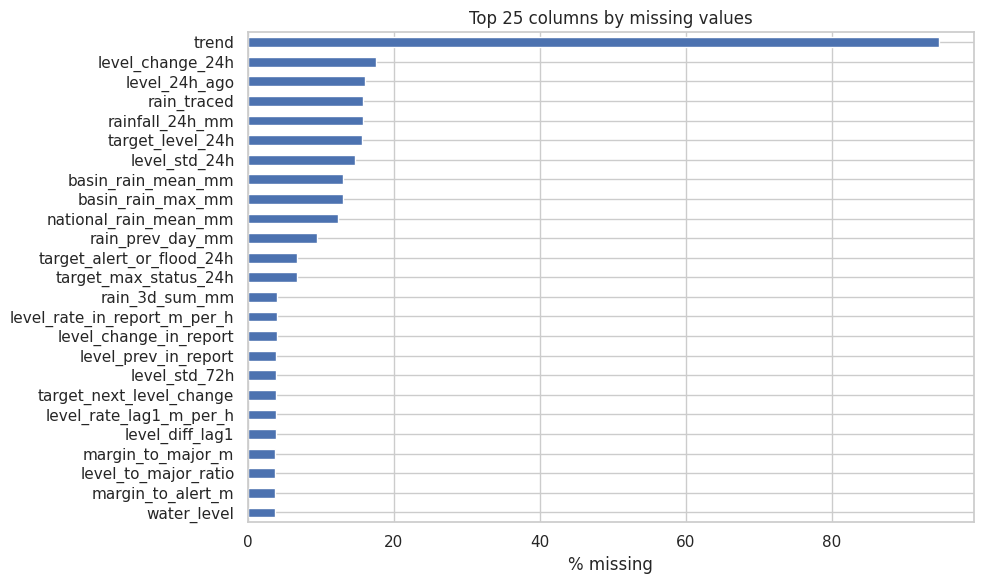

In [ ]:
dups = df.duplicated(['station', 'obs_datetime']).sum()
print('Duplicate station-observations:', dups)

miss = df.isna().mean().mul(100).round(2).sort_values(ascending=False)
miss = miss[miss > 0]
print(f'\nColumns with missing values: {len(miss)} of {df.shape[1]}')
plt.figure(figsize=(10, 6))
miss.head(25).sort_values().plot.barh(color='#4C72B0')
plt.xlabel('% missing'); plt.title('Top 25 columns by missing values')
plt.tight_layout(); plt.show()

In [ ]:
for c in FLAG_COLS:
    print(f'{c:25s} {int(df[c].sum()):5d} rows flagged')

ok = (df.alert_level <= df.minor_flood_level) & (df.minor_flood_level <= df.major_flood_level)
known = df[THRESHOLD_COLS].notna().all(axis=1)
print('\nRows with complete & valid thresholds:', int((ok & known).sum()), 'of', len(df))

def thr_status(r):
    if pd.isna(r.water_level) or r[THRESHOLD_COLS].isna().any():
        return np.nan
    return 3 if r.water_level >= r.major_flood_level else 2 if r.water_level >= r.minor_flood_level \
        else 1 if r.water_level >= r.alert_level else 0
chk = df.dropna(subset=['status']).apply(thr_status, axis=1)
agree = (chk == df.loc[chk.index, 'status'])[chk.notna()]
print('Official status agrees with thresholds: %.2f%% of rows' % (100 * agree.mean()))

flag_threshold_mismatch       4 rows flagged
flag_level_outlier           20 rows flagged
flag_parser_disagree          0 rows flagged

Rows with complete & valid thresholds: 39284 of 39288
Official status agrees with thresholds: 100.00% of rows


In [ ]:
display(df[['water_level', 'alert_level', 'major_flood_level', 'level_change_in_report',
            'rainfall_24h_mm', 'rain_7d_sum_mm', 'hours_since_prev_obs']].describe().T.round(3))

,count,mean,std,min,25%,50%,75%,max
water_level,37806.0,1.967,2.347,-3.640,0.65,1.3,2.45,21.9
alert_level,39288.0,4.528,2.322,1.219,3.00,4.0,5.00,15.0
major_flood_level,39284.0,7.206,2.729,2.134,6.00,7.0,8.00,19.0
level_change_in_report,37700.0,-0.008,0.542,-100.190,-0.02,0.0,0.00,2.9
rainfall_24h_mm,33098.0,13.784,26.336,0.000,0.00,2.1,16.50,364.5
rain_7d_sum_mm,38201.0,88.127,96.520,0.000,12.40,61.1,127.70,686.3
hours_since_prev_obs,39249.0,13.866,50.394,3.000,3.00,3.0,6.00,1080.0


###Exploratory Checks

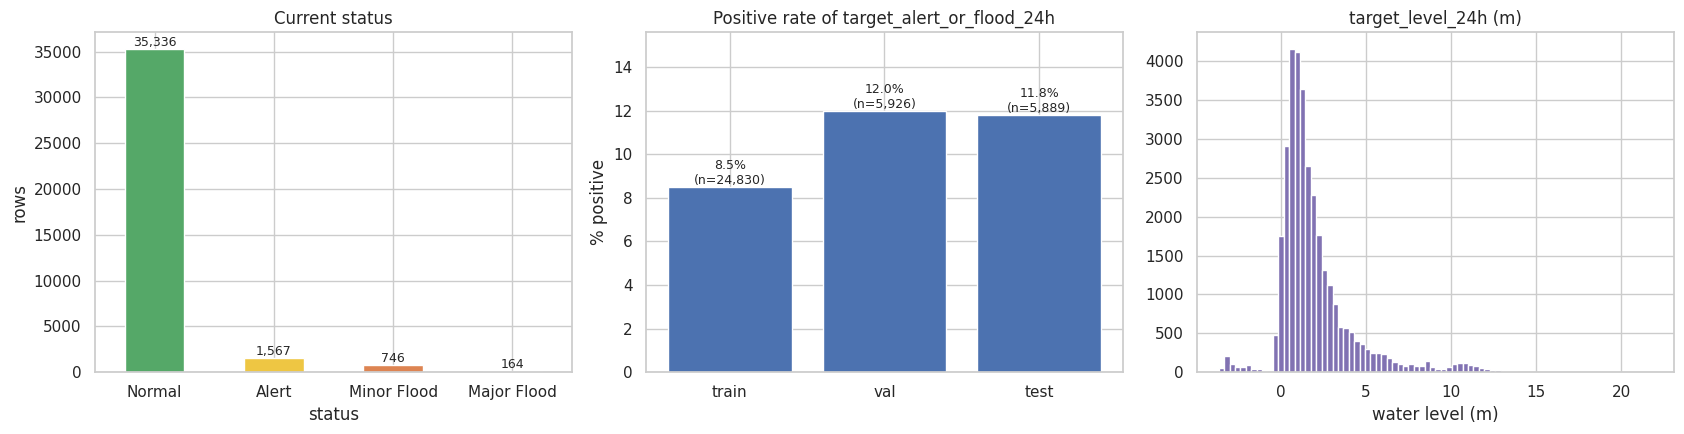

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))

st = df['status'].map({0: 'Normal', 1: 'Alert', 2: 'Minor Flood', 3: 'Major Flood'}).value_counts()
st = st.reindex(['Normal', 'Alert', 'Minor Flood', 'Major Flood'])
st.plot.bar(ax=ax[0], color=['#55A868', '#EEC643', '#DD8452', '#C44E52'])
ax[0].set_title('Current status'); ax[0].set_ylabel('rows'); ax[0].tick_params(axis='x', rotation=0)
for i, v in enumerate(st.values):
    ax[0].text(i, v, f'{v:,}', ha='center', va='bottom', fontsize=9)

t = df.groupby('split', observed=True)['target_alert_or_flood_24h'].agg(['mean', 'count'])
t = t.reindex(['train', 'val', 'test'])
ax[1].bar(t.index, t['mean'] * 100, color='#4C72B0')
ax[1].set_title('Positive rate of target_alert_or_flood_24h'); ax[1].set_ylabel('% positive')
ax[1].set_ylim(0, t['mean'].max() * 100 * 1.3)
for i, (m, n) in enumerate(zip(t['mean'], t['count'])):
    ax[1].text(i, m * 100, f'{m*100:.1f}%\n(n={n:,})', ha='center', va='bottom', fontsize=9)

df['target_level_24h'].clip(-5, 25).hist(bins=80, ax=ax[2], color='#8172B2')
ax[2].set_title('target_level_24h (m)'); ax[2].set_xlabel('water level (m)')
plt.tight_layout(); plt.show()

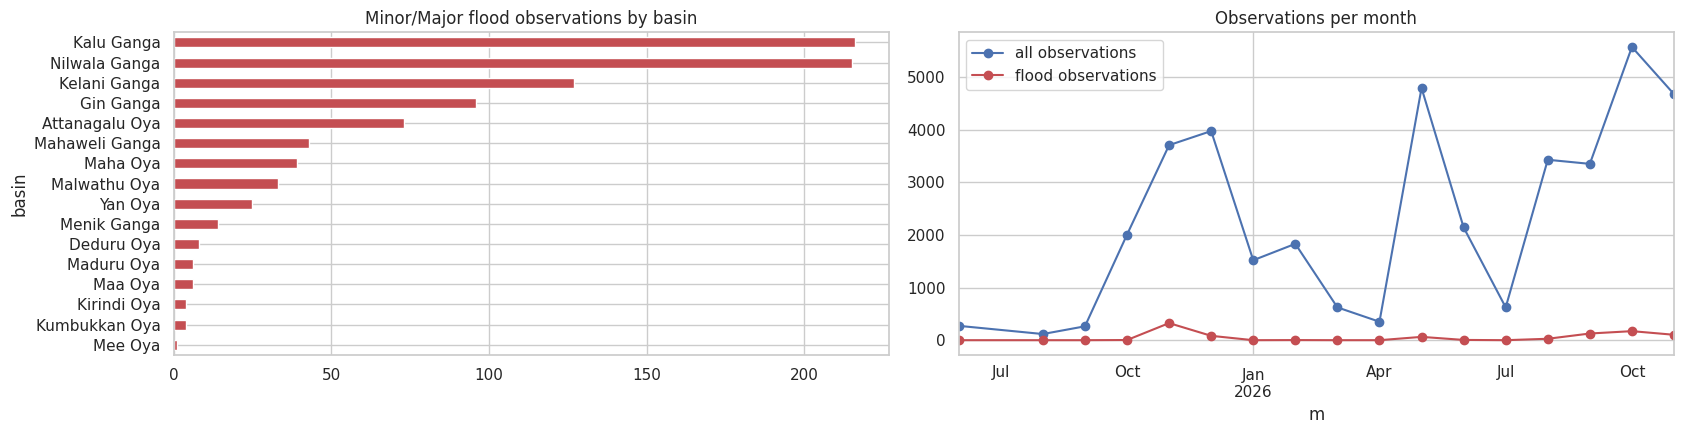

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(17, 4.5))
fb = df[df.status >= 2].groupby('basin', observed=True).size().sort_values()
fb.plot.barh(ax=ax[0], color='#C44E52'); ax[0].set_title('Minor/Major flood observations by basin')
mon = df.assign(m=df.obs_datetime.dt.to_period('M')).groupby('m').agg(
    obs=('station', 'size'), flood=('status', lambda s: (s >= 2).sum()))
mon['obs'].plot(ax=ax[1], label='all observations', marker='o')
mon['flood'].plot(ax=ax[1], label='flood observations', marker='o', color='#C44E52')
ax[1].set_title('Observations per month'); ax[1].legend()
plt.tight_layout(); plt.show()

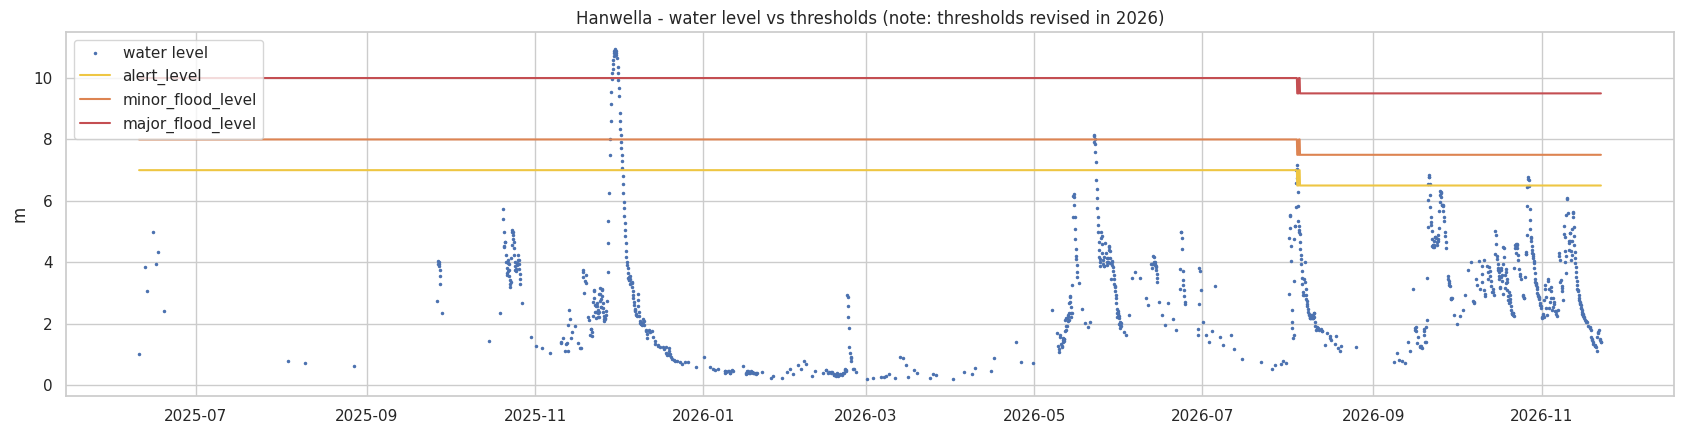

In [ ]:
s = df[df.station == 'Hanwella'].set_index('obs_datetime')
fig, ax = plt.subplots(figsize=(17, 4.5))
ax.plot(s.index, s.water_level, '.', ms=3, label='water level')
for col, c in [('alert_level', '#EEC643'), ('minor_flood_level', '#DD8452'), ('major_flood_level', '#C44E52')]:
    ax.plot(s.index, s[col], color=c, lw=1.5, label=col)
ax.set_title('Hanwella - water level vs thresholds (note: thresholds revised in 2026)')
ax.set_ylabel('m'); ax.legend(loc='upper left'); plt.tight_layout(); plt.show()

In [ ]:
num = df.select_dtypes('number').drop(columns=FLAG_COLS + TARGET_COLS, errors='ignore')
corr = pd.DataFrame({
    'corr_with_alert_24h': num.corrwith(df['target_alert_or_flood_24h']),
    'corr_with_level_24h': num.corrwith(df['target_level_24h'])}).round(3)
display(corr.sort_values('corr_with_alert_24h', ascending=False).head(15))

,corr_with_alert_24h,corr_with_level_24h
status,0.708,0.317
level_to_alert_ratio,0.586,0.644
level_to_major_ratio,0.547,0.753
basin_max_alert_ratio,0.501,0.467
rain_3d_sum_mm,0.385,0.392
national_stations_above_alert,0.375,0.228
rain_7d_sum_mm,0.372,0.422
basin_rain_mean_mm,0.354,0.323
water_level,0.340,0.945
level_max_24h,0.330,0.924


###Cleaning

In [ ]:
n0 = len(df)
log = []
m = df['flag_level_outlier'] == 1
log.append(('flag_level_outlier == 1', int(m.sum()))); df = df[~m]
m = df['water_level'].isna()
log.append(('water_level missing', int(m.sum()))); df = df[~m]
df = df.reset_index(drop=True)
for r, n in log:
    print(f'Removed {n:5d} rows : {r}')
print(f'Rows: {n0:,} -> {len(df):,}')

Removed    20 rows : flag_level_outlier == 1
Removed  1482 rows : water_level missing
Rows: 39,288 -> 37,786


###Leakage Control

In [ ]:
cut_val = df.loc[df.split == 'val', 'obs_datetime'].min()
cut_test = df.loc[df.split == 'test', 'obs_datetime'].min()
gap = pd.Timedelta(hours=24)
purge = ((df.split == 'train') & (df.obs_datetime > cut_val - gap)) | \
        ((df.split == 'val') & (df.obs_datetime > cut_test - gap))
print('Validation starts :', cut_val)
print('Test starts       :', cut_test)
print('Rows purged       :', int(purge.sum()))
df = df[~purge].reset_index(drop=True)
print()
print(df.groupby('split', observed=True)['obs_datetime'].agg(['min', 'max', 'count']).reindex(['train', 'val', 'test']))

Validation starts : 2026-09-22 21:00:00
Test starts       : 2026-10-27 18:00:00
Rows purged       : 486

                      min                 max  count
split                                               
train 2025-06-10 09:00:00 2026-09-21 21:00:00  26076
val   2026-09-22 21:00:00 2026-10-26 18:00:00   5492
test  2026-10-27 18:00:00 2026-11-22 12:00:00   5732


###Feature Engineering and Encoding

In [ ]:
df['trend_num'] = df['trend'].map({'Rising': 1, 'Falling': -1}).astype(float).fillna(0)
df['unit_is_ft'] = (df['unit_original'] == 'ft').astype(int)
df['level_range_72h'] = df['level_max_72h'] - df['level_mean_72h']
df['rain_intensity_3d'] = df['rain_3d_sum_mm'] / 3
season = pd.get_dummies(df['monsoon_season'], prefix='season', dtype=int)
df = pd.concat([df, season], axis=1)

EXCLUDE = set(ID_COLS + FLAG_COLS + TARGET_COLS +
              ['unit_original', 'trend', 'status_name', 'remarks_official', 'monsoon_season'])
FEATURES = [c for c in df.columns if c not in EXCLUDE]
print(len(FEATURES), 'candidate features')
print(FEATURES)

56 candidate features
['station_id', 'basin_id', 'rb_number', 'alert_level', 'minor_flood_level', 'major_flood_level', 'water_level', 'level_prev_in_report', 'in_report_gap_h', 'level_change_in_report', 'level_rate_in_report_m_per_h', 'status', 'rainfall_24h_mm', 'rain_traced', 'rain_prev_day_mm', 'rain_3d_sum_mm', 'rain_7d_sum_mm', 'rain_days_observed_7d', 'hours_since_prev_obs', 'level_lag1', 'level_lag2', 'level_lag3', 'level_diff_lag1', 'level_rate_lag1_m_per_h', 'level_24h_ago', 'level_change_24h', 'level_max_24h', 'level_mean_24h', 'level_std_24h', 'level_max_72h', 'level_mean_72h', 'level_std_72h', 'n_obs_24h', 'level_to_alert_ratio', 'level_to_major_ratio', 'margin_to_alert_m', 'margin_to_minor_m', 'margin_to_major_m', 'basin_rain_mean_mm', 'basin_rain_max_mm', 'basin_max_alert_ratio', 'basin_mean_level_change', 'national_stations_above_alert', 'national_rain_mean_mm', 'month', 'hour', 'doy_sin', 'doy_cos', 'trend_num', 'unit_is_ft', 'level_range_72h', 'rain_intensity_3d', 'sea

###Removing constant and duplicate features(decided on train only)

In [ ]:
train_mask = df.split == 'train'
nunq = df.loc[train_mask, FEATURES].nunique(dropna=True)
constant = nunq[nunq <= 1].index.tolist()
print('Constant on train  :', constant)

tr = df.loc[train_mask, [c for c in FEATURES if c not in constant]]
dup_cols = tr.T.duplicated()
duplicates = dup_cols[dup_cols].index.tolist()
print('Exact duplicates   :', duplicates)

FEATURES = [c for c in FEATURES if c not in constant + duplicates]
print('\nFinal feature count:', len(FEATURES))

Constant on train  : ['in_report_gap_h', 'rain_traced']
Exact duplicates   : ['level_rate_in_report_m_per_h']

Final feature count: 53


###Build the classification and regression datasets

In [ ]:
def make_task(target):
    d = df[df[target].notna()]
    out = {}
    for sp in ['train', 'val', 'test']:
        part = d[d.split == sp]
        out[sp] = (part[FEATURES].astype(float), part[target].astype(float), part[ID_COLS])
    return out

clf = make_task('target_alert_or_flood_24h')
reg = make_task('target_level_24h')
for name, task in [('Classification', clf), ('Regression', reg)]:
    print(name)
    for sp in ['train', 'val', 'test']:
        X, y, _ = task[sp]
        print(f'  {sp:5s}  X={X.shape}  y mean={y.mean():.4f}')

Classification
  train  X=(23829, 53)  y mean=0.0845
  val    X=(5490, 53)  y mean=0.1155
  test   X=(5693, 53)  y mean=0.1217
Regression
  train  X=(21481, 53)  y mean=1.9192
  val    X=(5151, 53)  y mean=2.1605
  test   X=(5428, 53)  y mean=2.1714


###Missing-value handling

In [ ]:
miss_train = clf['train'][0].isna().mean().sort_values(ascending=False)
print('Missing share in classification TRAIN features (top 12):')
print((miss_train.head(12) * 100).round(2).to_string())

IND_COLS = [c for c in FEATURES if clf['train'][0][c].isna().mean() > 0.05]
print('\nMissing-indicator columns added for:', IND_COLS)

def fit_imputer(X_train):
    imp = SimpleImputer(strategy='median')
    imp.fit(X_train)
    return imp

def apply_imputer(imp, X):
    Xi = pd.DataFrame(imp.transform(X), columns=X.columns, index=X.index)
    for c in IND_COLS:
        Xi[c + '_was_missing'] = X[c].isna().astype(int)
    return Xi

imp_clf = fit_imputer(clf['train'][0])
imp_reg = fit_imputer(reg['train'][0])
clf_imp = {sp: apply_imputer(imp_clf, clf[sp][0]) for sp in clf}
reg_imp = {sp: apply_imputer(imp_reg, reg[sp][0]) for sp in reg}
print('\nRemaining NaN after imputation (clf train):', int(clf_imp['train'].isna().sum().sum()))
print('Imputed feature count:', clf_imp['train'].shape[1])

Missing share in classification TRAIN features (top 12):
level_24h_ago            16.19
level_change_24h         16.19
level_std_24h            13.08
rainfall_24h_mm          10.39
rain_prev_day_mm          9.80
basin_rain_mean_mm        7.80
basin_rain_max_mm         7.80
national_rain_mean_mm     7.56
rain_intensity_3d         3.90
rain_3d_sum_mm            3.90
rain_7d_sum_mm            2.70
level_std_72h             2.32

Missing-indicator columns added for: ['rainfall_24h_mm', 'rain_prev_day_mm', 'level_24h_ago', 'level_change_24h', 'level_std_24h', 'basin_rain_mean_mm', 'basin_rain_max_mm', 'national_rain_mean_mm']

Remaining NaN after imputation (clf train): 0
Imputed feature count: 61


###Feature scaling

In [ ]:
sc_clf = StandardScaler().fit(clf_imp['train'])
sc_reg = StandardScaler().fit(reg_imp['train'])
clf_sc = {sp: pd.DataFrame(sc_clf.transform(X), columns=X.columns, index=X.index) for sp, X in clf_imp.items()}
reg_sc = {sp: pd.DataFrame(sc_reg.transform(X), columns=X.columns, index=X.index) for sp, X in reg_imp.items()}
print('Scaled train mean (should be ~0):', round(float(clf_sc['train'].values.mean()), 4))
print('Scaled train std  (should be ~1):', round(float(clf_sc['train'].values.std()), 4))

Scaled train mean (should be ~0): 0.0
Scaled train std  (should be ~1): 1.0


###Class imbalance analysis

Train: negatives=21,816  positives=2,013  ratio=10.84:1
Baseline accuracy of always predicting 0 on test: 0.878


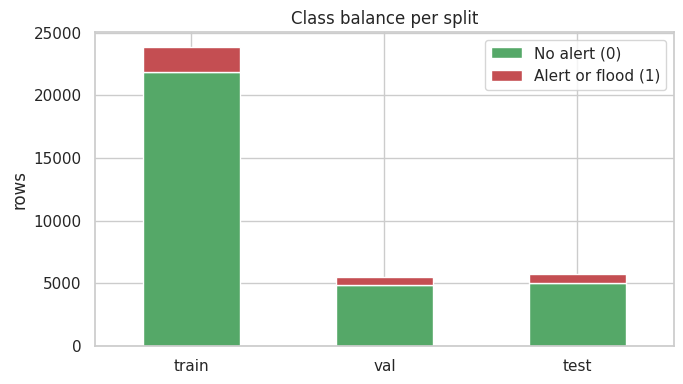

In [ ]:
y_tr = clf['train'][1]
neg, pos = int((y_tr == 0).sum()), int((y_tr == 1).sum())
scale_pos_weight = neg / pos
print(f'Train: negatives={neg:,}  positives={pos:,}  ratio={scale_pos_weight:.2f}:1')
print('Baseline accuracy of always predicting 0 on test: %.3f' % (1 - clf['test'][1].mean()))

fig, ax = plt.subplots(figsize=(7, 4))
cnt = pd.DataFrame({sp: clf[sp][1].value_counts() for sp in ['train', 'val', 'test']}).T
cnt.columns = ['No alert (0)', 'Alert or flood (1)']
cnt.plot.bar(stacked=True, ax=ax, color=['#55A868', '#C44E52'])
ax.set_title('Class balance per split'); ax.set_ylabel('rows'); ax.tick_params(axis='x', rotation=0)
plt.tight_layout(); plt.show()

###Summary

In [ ]:
print('=' * 60)
print('PREPROCESSING SUMMARY')
print('=' * 60)
print(f'Raw rows                     : {len(df_raw):,}')
print(f'Rows after cleaning & purge  : {len(df):,}')
print(f'Features (raw / imputed)     : {len(FEATURES)} / {clf_imp["train"].shape[1]}')
print(f'scale_pos_weight             : {scale_pos_weight:.3f}')
for name, task in [('CLASSIFICATION', clf), ('REGRESSION', reg)]:
    print(f'\n{name}')
    for sp in ['train', 'val', 'test']:
        X, y, ids = task[sp]
        extra = f'positive rate={y.mean():.3%}' if name == 'CLASSIFICATION' else f'mean level={y.mean():.3f} m'
        print(f'  {sp:5s} rows={len(X):6,}  {ids.obs_datetime.min():%Y-%m-%d} -> {ids.obs_datetime.max():%Y-%m-%d}  {extra}')

PREPROCESSING SUMMARY
Raw rows                     : 39,288
Rows after cleaning & purge  : 37,300
Features (raw / imputed)     : 53 / 61
scale_pos_weight             : 10.838

CLASSIFICATION
  train rows=23,829  2025-06-12 -> 2026-09-21  positive rate=8.448%
  val   rows= 5,490  2026-09-22 -> 2026-10-26  positive rate=11.548%
  test  rows= 5,693  2026-10-27 -> 2026-11-22  positive rate=12.173%

REGRESSION
  train rows=21,481  2025-06-12 -> 2026-09-21  mean level=1.919 m
  val   rows= 5,151  2026-09-22 -> 2026-10-26  mean level=2.161 m
  test  rows= 5,428  2026-10-27 -> 2026-11-21  mean level=2.171 m


## Ensemble Classification: Bagging vs Boosting vs Stacking

###Setup

In [ ]:
try:
    import catboost
except ImportError:
    !pip install -q catboost

In [ ]:
import time
from itertools import product

from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (BaggingClassifier, RandomForestClassifier, ExtraTreesClassifier,
                              AdaBoostClassifier, HistGradientBoostingClassifier,
                              StackingClassifier, VotingClassifier)
from sklearn.metrics import (average_precision_score, roc_auc_score, f1_score, precision_score,
                             recall_score, balanced_accuracy_score, matthews_corrcoef, accuracy_score,
                             precision_recall_curve, roc_curve, confusion_matrix, ConfusionMatrixDisplay)
from sklearn.inspection import permutation_importance
import xgboost as xgb
import lightgbm as lgb
import catboost
from catboost import CatBoostClassifier

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 50); pd.set_option('display.width', 200)
sns.set_theme(style='whitegrid')
RANDOM_STATE = 42
N_JOBS = -1
print('xgboost', xgb.__version__, '| lightgbm', lgb.__version__, '| catboost', catboost.__version__)

xgboost 3.4.1 | lightgbm 4.6.0 | catboost 1.2.10


###Load preprocessed data

In [ ]:
try:
    from google.colab import drive
    drive.mount('/content/drive')
    BASE_DIR = '/content/drive/MyDrive/MachineLearningCA01'
except ImportError:
    BASE_DIR = os.path.abspath('..')

PROC = os.path.join(BASE_DIR, 'processed')
MODEL_DIR = os.path.join(PROC, 'models_clf'); os.makedirs(MODEL_DIR, exist_ok=True)
meta = json.load(open(f'{PROC}/meta.json'))

def load(split, kind):
    return pd.read_parquet(f'{PROC}/clf_X_{split}_{kind}.parquet')

X_raw = {s: load(s, 'raw') for s in ['train', 'val', 'test']}
X_imp = {s: load(s, 'imputed') for s in ['train', 'val', 'test']}
X_sc = {s: load(s, 'scaled') for s in ['train', 'val', 'test']}
y = {s: pd.read_parquet(f'{PROC}/clf_y_{s}.parquet')['y'].astype(int) for s in ['train', 'val', 'test']}
ids = {s: pd.read_parquet(f'{PROC}/clf_ids_{s}.parquet') for s in ['train', 'val', 'test']}
SPW = meta['scale_pos_weight']

for s in ['train', 'val', 'test']:
    print(f'{s:5s} raw={X_raw[s].shape} imputed={X_imp[s].shape}  positives={y[s].sum():,} ({y[s].mean():.2%})')
print('scale_pos_weight =', round(SPW, 3))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
train raw=(23829, 53) imputed=(23829, 61)  positives=2,013 (8.45%)
val   raw=(5490, 53) imputed=(5490, 61)  positives=634 (11.55%)
test  raw=(5693, 53) imputed=(5693, 61)  positives=693 (12.17%)
scale_pos_weight = 10.838


###Evaluation Helpers

In [ ]:
FMT4 = ['PR_AUC', 'ROC_AUC', 'F1', 'Recall', 'Precision', 'MCC', 'Bal_Acc', 'Accuracy', 'Threshold']

def show_table(t):
    try:
        display(t.style.format({c: '{:.4f}' for c in FMT4 if c in t} | {'Fit_s': '{:.1f}'})
                .background_gradient(subset=['PR_AUC', 'F1'], cmap='Greens'))
    except Exception:
        display(t.round(4))

RESULTS = {}

def best_threshold(y_true, proba):
    p, r, t = precision_recall_curve(y_true, proba)
    f1 = 2 * p * r / np.clip(p + r, 1e-12, None)
    i = np.nanargmax(f1[:-1]) if len(t) else 0
    return float(t[i]) if len(t) else 0.5

def evaluate(y_true, proba, thr):
    pred = (proba >= thr).astype(int)
    return {'PR_AUC': average_precision_score(y_true, proba),
            'ROC_AUC': roc_auc_score(y_true, proba) if len(np.unique(proba)) > 1 else 0.5,
            'F1': f1_score(y_true, pred, zero_division=0),
            'Recall': recall_score(y_true, pred, zero_division=0),
            'Precision': precision_score(y_true, pred, zero_division=0),
            'MCC': matthews_corrcoef(y_true, pred),
            'Bal_Acc': balanced_accuracy_score(y_true, pred),
            'Accuracy': accuracy_score(y_true, pred)}

def proba_of(model, X):
    return model.predict_proba(X)[:, 1]

def register(name, family, model, data, params=None, fit_s=np.nan):
    pv, pt = proba_of(model, X_of(data, 'val')), proba_of(model, X_of(data, 'test'))
    thr = best_threshold(y['val'], pv)
    RESULTS[name] = dict(model=model, family=family, data=data, proba_val=pv, proba_test=pt,
                         threshold=thr, params=params or {}, fit_s=fit_s)
    m = evaluate(y['val'], pv, thr)
    print(f'{name:22s} VAL  PR-AUC={m["PR_AUC"]:.4f}  F1={m["F1"]:.4f}  Recall={m["Recall"]:.4f}  '
          f'Precision={m["Precision"]:.4f}  thr={thr:.3f}  fit={fit_s:.1f}s')

def X_of(data, split):
    return {'raw': X_raw, 'imputed': X_imp, 'scaled': X_sc}[data][split]

def tune(name, family, make_model, grid, data, fit_kwargs=None):
    keys = list(grid)
    best = (-1, None, None, None)
    for vals in product(*[grid[k] for k in keys]):
        params = dict(zip(keys, vals))
        t0 = time.time()
        m = make_model(**params)
        m.fit(X_of(data, 'train'), y['train'], **(fit_kwargs or {}))
        fit_s = time.time() - t0
        ap = average_precision_score(y['val'], proba_of(m, X_of(data, 'val')))
        print(f'   {params}  val PR-AUC={ap:.4f}  ({fit_s:.1f}s)')
        if ap > best[0]:
            best = (ap, m, params, fit_s)
    print(f' -> best {best[2]}')
    register(name, family, best[1], data, best[2], best[3])
    return best[1]

###Baselines

In [ ]:
class Persistence:
    def fit(self, X, y): return self
    def predict_proba(self, X):
        p = (X['status'].values >= 1).astype(float)
        return np.column_stack([1 - p, p])

register('Persistence', 'Baseline', Persistence(), 'raw')

t0 = time.time()
lr = LogisticRegression(class_weight='balanced', max_iter=3000, C=1.0, random_state=RANDOM_STATE)
lr.fit(X_sc['train'], y['train'])
register('Logistic Regression', 'Baseline', lr, 'scaled', {'C': 1.0}, time.time() - t0)

print('\nDecision tree grid:')
dt = tune('Decision Tree', 'Baseline',
          lambda **p: DecisionTreeClassifier(class_weight='balanced', random_state=RANDOM_STATE, **p),
          {'max_depth': [4, 8, 12], 'min_samples_leaf': [20, 100]}, 'imputed')

Persistence            VAL  PR-AUC=0.6033  F1=0.7307  Recall=0.6057  Precision=0.9209  thr=1.000  fit=nans
Logistic Regression    VAL  PR-AUC=0.8615  F1=0.7864  Recall=0.7287  Precision=0.8540  thr=0.888  fit=1.4s

Decision tree grid:
   {'max_depth': 4, 'min_samples_leaf': 20}  val PR-AUC=0.7765  (0.5s)
   {'max_depth': 4, 'min_samples_leaf': 100}  val PR-AUC=0.7938  (0.5s)
   {'max_depth': 8, 'min_samples_leaf': 20}  val PR-AUC=0.7874  (1.0s)
   {'max_depth': 8, 'min_samples_leaf': 100}  val PR-AUC=0.8003  (0.8s)
   {'max_depth': 12, 'min_samples_leaf': 20}  val PR-AUC=0.7563  (1.2s)
   {'max_depth': 12, 'min_samples_leaf': 100}  val PR-AUC=0.8004  (0.8s)
 -> best {'max_depth': 12, 'min_samples_leaf': 100}
Decision Tree          VAL  PR-AUC=0.8004  F1=0.7322  Recall=0.7224  Precision=0.7423  thr=0.877  fit=0.8s


###Bagging

In [ ]:
print('BaggingClassifier grid:')
bag = tune('Bagging (DT)', 'Bagging',
           lambda **p: BaggingClassifier(estimator=DecisionTreeClassifier(class_weight='balanced',
                                                                         min_samples_leaf=p.pop('min_samples_leaf')),
                                         n_estimators=200, n_jobs=N_JOBS, random_state=RANDOM_STATE, **p),
           {'max_samples': [0.5, 1.0], 'min_samples_leaf': [1, 5]}, 'imputed')

BaggingClassifier grid:
   {'max_samples': 0.5, 'min_samples_leaf': 1}  val PR-AUC=0.8538  (78.5s)
   {'max_samples': 0.5, 'min_samples_leaf': 5}  val PR-AUC=0.8674  (49.7s)
   {'max_samples': 1.0, 'min_samples_leaf': 1}  val PR-AUC=0.8481  (86.5s)
   {'max_samples': 1.0, 'min_samples_leaf': 5}  val PR-AUC=0.8580  (77.2s)
 -> best {'max_samples': 0.5, 'min_samples_leaf': 5}
Bagging (DT)           VAL  PR-AUC=0.8674  F1=0.7870  Recall=0.7256  Precision=0.8598  thr=0.492  fit=49.7s


In [ ]:
print('Random Forest grid:')
rf = tune('Random Forest', 'Bagging',
          lambda **p: RandomForestClassifier(n_estimators=400, class_weight='balanced_subsample',
                                             n_jobs=N_JOBS, random_state=RANDOM_STATE, **p),
          {'max_features': ['sqrt', 0.3], 'min_samples_leaf': [1, 5], 'max_depth': [None, 16]}, 'imputed')

Random Forest grid:
   {'max_features': 'sqrt', 'min_samples_leaf': 1, 'max_depth': None}  val PR-AUC=0.8759  (23.7s)
   {'max_features': 'sqrt', 'min_samples_leaf': 1, 'max_depth': 16}  val PR-AUC=0.8752  (21.7s)
   {'max_features': 'sqrt', 'min_samples_leaf': 5, 'max_depth': None}  val PR-AUC=0.8734  (21.7s)
   {'max_features': 'sqrt', 'min_samples_leaf': 5, 'max_depth': 16}  val PR-AUC=0.8729  (21.8s)
   {'max_features': 0.3, 'min_samples_leaf': 1, 'max_depth': None}  val PR-AUC=0.8765  (51.6s)
   {'max_features': 0.3, 'min_samples_leaf': 1, 'max_depth': 16}  val PR-AUC=0.8697  (52.2s)
   {'max_features': 0.3, 'min_samples_leaf': 5, 'max_depth': None}  val PR-AUC=0.8741  (49.0s)
   {'max_features': 0.3, 'min_samples_leaf': 5, 'max_depth': 16}  val PR-AUC=0.8724  (47.9s)
 -> best {'max_features': 0.3, 'min_samples_leaf': 1, 'max_depth': None}
Random Forest          VAL  PR-AUC=0.8765  F1=0.7839  Recall=0.7240  Precision=0.8547  thr=0.338  fit=51.6s


In [ ]:
print('Extra Trees grid:')
et = tune('Extra Trees', 'Bagging',
          lambda **p: ExtraTreesClassifier(n_estimators=400, class_weight='balanced_subsample',
                                           n_jobs=N_JOBS, random_state=RANDOM_STATE, **p),
          {'max_features': ['sqrt', 0.5], 'min_samples_leaf': [1, 5]}, 'imputed')

Extra Trees grid:
   {'max_features': 'sqrt', 'min_samples_leaf': 1}  val PR-AUC=0.8686  (5.7s)
   {'max_features': 'sqrt', 'min_samples_leaf': 5}  val PR-AUC=0.8574  (7.6s)
   {'max_features': 0.5, 'min_samples_leaf': 1}  val PR-AUC=0.8724  (17.0s)
   {'max_features': 0.5, 'min_samples_leaf': 5}  val PR-AUC=0.8688  (15.8s)
 -> best {'max_features': 0.5, 'min_samples_leaf': 1}
Extra Trees            VAL  PR-AUC=0.8724  F1=0.7875  Recall=0.7571  Precision=0.8205  thr=0.295  fit=17.0s


Trees:  25 | OOB Error: 0.0194
Trees:  50 | OOB Error: 0.0180
Trees: 100 | OOB Error: 0.0170
Trees: 150 | OOB Error: 0.0167
Trees: 200 | OOB Error: 0.0165


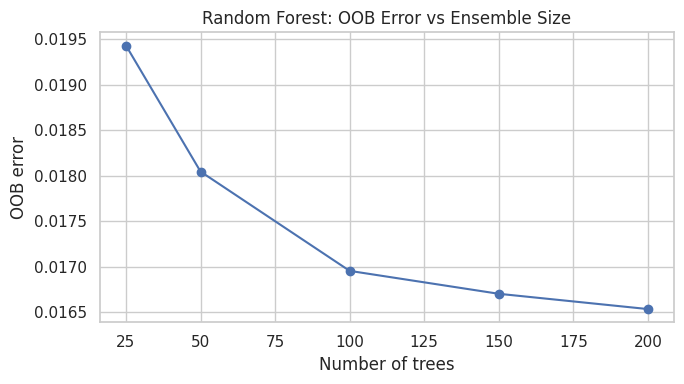

In [ ]:
params = RESULTS['Random Forest']['params']

oob_rf = RandomForestClassifier(
    class_weight='balanced_subsample',
    oob_score=True,
    warm_start=True,
    n_jobs=N_JOBS,
    random_state=RANDOM_STATE,
    **params
)

n_list = [25, 50, 100, 150, 200]
oob_err = []

for n in n_list:
    oob_rf.set_params(n_estimators=n)
    oob_rf.fit(X_imp['train'], y['train'])

    error = 1 - oob_rf.oob_score_
    oob_err.append(error)

    print(f"Trees: {n:3d} | OOB Error: {error:.4f}")

plt.figure(figsize=(7, 4))
plt.plot(n_list, oob_err, marker='o')
plt.xlabel('Number of trees')
plt.ylabel('OOB error')
plt.title('Random Forest: OOB Error vs Ensemble Size')
plt.grid(True)
plt.tight_layout()
plt.show()

###Boosting

In [ ]:
print('AdaBoost grid:')
ada = tune('AdaBoost', 'Boosting',
           lambda **p: AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=p.pop('depth'),
                                                                          class_weight='balanced'),
                                          random_state=RANDOM_STATE, **p),
           {'depth': [1, 3], 'n_estimators': [200], 'learning_rate': [0.1, 0.5]}, 'imputed')

AdaBoost grid:
   {'depth': 1, 'n_estimators': 200, 'learning_rate': 0.1}  val PR-AUC=0.7057  (0.8s)
   {'depth': 1, 'n_estimators': 200, 'learning_rate': 0.5}  val PR-AUC=0.5759  (0.4s)
   {'depth': 3, 'n_estimators': 200, 'learning_rate': 0.1}  val PR-AUC=0.8457  (47.5s)
   {'depth': 3, 'n_estimators': 200, 'learning_rate': 0.5}  val PR-AUC=0.8324  (2.1s)
 -> best {'depth': 3, 'n_estimators': 200, 'learning_rate': 0.1}
AdaBoost               VAL  PR-AUC=0.8457  F1=0.7910  Recall=0.7224  Precision=0.8740  thr=0.751  fit=47.5s


In [ ]:
print('HistGradientBoosting grid:')
hgb = tune('HistGradientBoosting', 'Boosting',
           lambda **p: HistGradientBoostingClassifier(max_iter=400, class_weight='balanced',
                                                      random_state=RANDOM_STATE, **p),
           {'learning_rate': [0.05, 0.1], 'max_leaf_nodes': [15, 31]}, 'raw')

HistGradientBoosting grid:
   {'learning_rate': 0.05, 'max_leaf_nodes': 15}  val PR-AUC=0.8780  (4.5s)
   {'learning_rate': 0.05, 'max_leaf_nodes': 31}  val PR-AUC=0.8723  (3.3s)
   {'learning_rate': 0.1, 'max_leaf_nodes': 15}  val PR-AUC=0.8816  (2.1s)
   {'learning_rate': 0.1, 'max_leaf_nodes': 31}  val PR-AUC=0.8762  (1.7s)
 -> best {'learning_rate': 0.1, 'max_leaf_nodes': 15}
HistGradientBoosting   VAL  PR-AUC=0.8816  F1=0.8073  Recall=0.7334  Precision=0.8977  thr=0.706  fit=2.1s


In [ ]:
print('XGBoost grid:')
xgbm = tune('XGBoost', 'Boosting',
            lambda **p: xgb.XGBClassifier(n_estimators=400, subsample=0.8, colsample_bytree=0.8,
                                          scale_pos_weight=SPW, eval_metric='aucpr', tree_method='hist',
                                          n_jobs=N_JOBS, random_state=RANDOM_STATE, **p),
            {'max_depth': [4, 6], 'learning_rate': [0.05, 0.1], 'min_child_weight': [1, 5]}, 'raw')

XGBoost grid:
   {'max_depth': 4, 'learning_rate': 0.05, 'min_child_weight': 1}  val PR-AUC=0.8849  (2.6s)
   {'max_depth': 4, 'learning_rate': 0.05, 'min_child_weight': 5}  val PR-AUC=0.8871  (4.6s)
   {'max_depth': 4, 'learning_rate': 0.1, 'min_child_weight': 1}  val PR-AUC=0.8823  (2.8s)
   {'max_depth': 4, 'learning_rate': 0.1, 'min_child_weight': 5}  val PR-AUC=0.8865  (2.1s)
   {'max_depth': 6, 'learning_rate': 0.05, 'min_child_weight': 1}  val PR-AUC=0.8904  (4.1s)
   {'max_depth': 6, 'learning_rate': 0.05, 'min_child_weight': 5}  val PR-AUC=0.8887  (6.5s)
   {'max_depth': 6, 'learning_rate': 0.1, 'min_child_weight': 1}  val PR-AUC=0.8897  (3.7s)
   {'max_depth': 6, 'learning_rate': 0.1, 'min_child_weight': 5}  val PR-AUC=0.8905  (3.1s)
 -> best {'max_depth': 6, 'learning_rate': 0.1, 'min_child_weight': 5}
XGBoost                VAL  PR-AUC=0.8905  F1=0.8137  Recall=0.8028  Precision=0.8250  thr=0.270  fit=3.1s


In [ ]:
lgbm = tune('LightGBM', 'Boosting',
            lambda **p: lgb.LGBMClassifier(n_estimators=400, subsample=0.8, subsample_freq=1,
                                           colsample_bytree=0.8, scale_pos_weight=SPW, n_jobs=N_JOBS,
                                           random_state=RANDOM_STATE, verbose=-1, **p),
            {'num_leaves': [15, 31], 'learning_rate': [0.05, 0.1], 'min_child_samples': [20, 50]}, 'raw')

   {'num_leaves': 15, 'learning_rate': 0.05, 'min_child_samples': 20}  val PR-AUC=0.8851  (2.6s)
   {'num_leaves': 15, 'learning_rate': 0.05, 'min_child_samples': 50}  val PR-AUC=0.8898  (4.7s)
   {'num_leaves': 15, 'learning_rate': 0.1, 'min_child_samples': 20}  val PR-AUC=0.8861  (2.3s)
   {'num_leaves': 15, 'learning_rate': 0.1, 'min_child_samples': 50}  val PR-AUC=0.8881  (2.2s)
   {'num_leaves': 31, 'learning_rate': 0.05, 'min_child_samples': 20}  val PR-AUC=0.8906  (3.3s)
   {'num_leaves': 31, 'learning_rate': 0.05, 'min_child_samples': 50}  val PR-AUC=0.8913  (6.2s)
   {'num_leaves': 31, 'learning_rate': 0.1, 'min_child_samples': 20}  val PR-AUC=0.8837  (3.3s)
   {'num_leaves': 31, 'learning_rate': 0.1, 'min_child_samples': 50}  val PR-AUC=0.8822  (3.1s)
 -> best {'num_leaves': 31, 'learning_rate': 0.05, 'min_child_samples': 50}
LightGBM               VAL  PR-AUC=0.8913  F1=0.8119  Recall=0.7524  Precision=0.8817  thr=0.557  fit=6.2s


In [ ]:
print('CatBoost grid:')
cat = tune('CatBoost', 'Boosting',
           lambda **p: CatBoostClassifier(iterations=500, scale_pos_weight=SPW, eval_metric='PRAUC',
                                          random_seed=RANDOM_STATE, verbose=0, thread_count=-1, **p),
           {'depth': [4, 6], 'learning_rate': [0.05, 0.1]}, 'raw')

CatBoost grid:
   {'depth': 4, 'learning_rate': 0.05}  val PR-AUC=0.8840  (8.0s)
   {'depth': 4, 'learning_rate': 0.1}  val PR-AUC=0.8736  (6.4s)
   {'depth': 6, 'learning_rate': 0.05}  val PR-AUC=0.8858  (11.2s)
   {'depth': 6, 'learning_rate': 0.1}  val PR-AUC=0.8794  (11.0s)
 -> best {'depth': 6, 'learning_rate': 0.05}
CatBoost               VAL  PR-AUC=0.8858  F1=0.7929  Recall=0.7366  Precision=0.8585  thr=0.654  fit=11.2s


###Stacking

In [ ]:
base = [('rf', clone(RESULTS['Random Forest']['model']).set_params(n_estimators=200)),
        ('et', clone(RESULTS['Extra Trees']['model']).set_params(n_estimators=200)),
        ('xgb', clone(RESULTS['XGBoost']['model'])),
        ('lgbm', clone(RESULTS['LightGBM']['model'])),
        ('cat', clone(RESULTS['CatBoost']['model']))]

t0 = time.time()
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer

def to_logit(p):
    p = np.clip(p, 1e-4, 1 - 1e-4)
    return np.log(p / (1 - p))

meta_learner = make_pipeline(FunctionTransformer(to_logit),
                             LogisticRegression(C=0.01, class_weight='balanced', max_iter=2000))
stack = StackingClassifier(estimators=base, final_estimator=meta_learner, stack_method='predict_proba',
                           cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
                           n_jobs=1, passthrough=False)
stack.fit(X_imp['train'], y['train'])
register('Stacking (LR meta)', 'Stacking', stack, 'imputed', {'cv': 'StratifiedKFold(5, shuffle)', 'meta': 'LR(C=0.01) on logits'}, time.time() - t0)

coef = pd.Series(stack.final_estimator_[-1].coef_[0], index=[n for n, _ in base])
print('\nMeta-learner weights (how much the stack trusts each base model):')
print(coef.round(3).to_string())

t0 = time.time()
vote = VotingClassifier(estimators=[(n, clone(m)) for n, m in base], voting='soft', n_jobs=1)
vote.fit(X_imp['train'], y['train'])
register('Soft Voting', 'Stacking', vote, 'imputed', {'voting': 'soft'}, time.time() - t0)

Stacking (LR meta)     VAL  PR-AUC=0.8892  F1=0.8104  Recall=0.7650  Precision=0.8615  thr=0.841  fit=273.3s

Meta-learner weights (how much the stack trusts each base model):
rf     -0.150
et      0.644
xgb     0.290
lgbm    0.267
cat    -0.069
Soft Voting            VAL  PR-AUC=0.8925  F1=0.8159  Recall=0.8107  Precision=0.8211  thr=0.326  fit=53.9s


###Validation comparison(used for model selection)

In [ ]:
def table(split):
    rows = []
    for n, r in RESULTS.items():
        p = r['proba_val'] if split == 'val' else r['proba_test']
        rows.append({'Model': n, 'Family': r['family'], **evaluate(y[split], p, r['threshold']),
                     'Threshold': r['threshold'], 'Fit_s': r['fit_s']})
    return pd.DataFrame(rows).sort_values('PR_AUC', ascending=False).reset_index(drop=True)

val_tbl = table('val')
show_table(val_tbl)

,Model,Family,PR_AUC,ROC_AUC,F1,Recall,Precision,MCC,Bal_Acc,Accuracy,Threshold,Fit_s
0,Soft Voting,Stacking,0.8925,0.9709,0.8159,0.8107,0.8211,0.7920,0.8938,0.9577,0.3261,53.9
1,LightGBM,Boosting,0.8913,0.9727,0.8119,0.7524,0.8817,0.7926,0.8696,0.9597,0.5574,6.2
2,XGBoost,Boosting,0.8905,0.9703,0.8137,0.8028,0.8250,0.7899,0.8903,0.9576,0.2695,3.1
3,Stacking (LR meta),Stacking,0.8892,0.9710,0.8104,0.7650,0.8615,0.7890,0.8745,0.9587,0.8409,273.3
4,CatBoost,Boosting,0.8858,0.9717,0.7929,0.7366,0.8585,0.7710,0.8604,0.9556,0.6538,11.2
5,HistGradientBoosting,Boosting,0.8816,0.9686,0.8073,0.7334,0.8977,0.7900,0.8613,0.9596,0.7057,2.1
6,Random Forest,Bagging,0.8765,0.9665,0.7839,0.7240,0.8547,0.7616,0.8540,0.9539,0.3375,51.6
7,Extra Trees,Bagging,0.8724,0.9655,0.7875,0.7571,0.8205,0.7618,0.8677,0.9528,0.2950,17.0
8,Bagging (DT),Bagging,0.8674,0.9650,0.7870,0.7256,0.8598,0.7653,0.8551,0.9546,0.4922,49.7
9,Logistic Regression,Baseline,0.8615,0.9640,0.7864,0.7287,0.8540,0.7640,0.8562,0.9543,0.8876,1.4


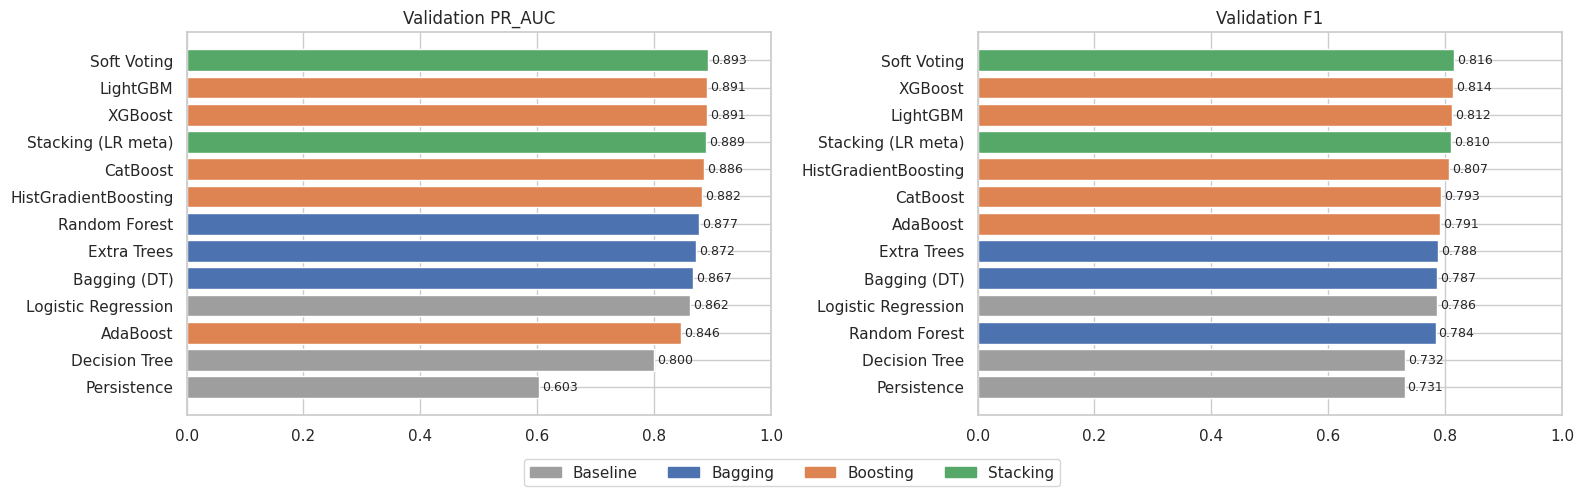

In [ ]:
FAM_COLORS = {'Baseline': '#9E9E9E', 'Bagging': '#4C72B0', 'Boosting': '#DD8452', 'Stacking': '#55A868'}
fig, ax = plt.subplots(1, 2, figsize=(16, 5))
for a, metric in zip(ax, ['PR_AUC', 'F1']):
    t = val_tbl.sort_values(metric)
    a.barh(t['Model'], t[metric], color=t['Family'].map(FAM_COLORS))
    a.set_title(f'Validation {metric}'); a.set_xlim(0, 1)
    for i, v in enumerate(t[metric]): a.text(v + 0.005, i, f'{v:.3f}', va='center', fontsize=9)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in FAM_COLORS.values()]
fig.legend(handles, FAM_COLORS.keys(), loc='lower center', ncol=4)
plt.tight_layout(rect=(0, 0.06, 1, 1)); plt.show()

###Final test Evaluation

In [ ]:
test_tbl = table('test')
show_table(test_tbl)

best_by_family = val_tbl.groupby('Family').head(1).set_index('Family')['Model'].to_dict()
print('Best per family (chosen on validation):', best_by_family)

,Model,Family,PR_AUC,ROC_AUC,F1,Recall,Precision,MCC,Bal_Acc,Accuracy,Threshold,Fit_s
0,CatBoost,Boosting,0.9071,0.9752,0.8368,0.8066,0.8694,0.8159,0.8949,0.9617,0.6538,11.2
1,Random Forest,Bagging,0.9054,0.9718,0.8225,0.7821,0.8672,0.8006,0.8828,0.9589,0.3375,51.6
2,Extra Trees,Bagging,0.9048,0.9734,0.8252,0.8139,0.8368,0.8014,0.8959,0.9580,0.2950,17.0
3,Soft Voting,Stacking,0.9032,0.9736,0.8132,0.8167,0.8097,0.7872,0.8951,0.9543,0.3261,53.9
4,Bagging (DT),Bagging,0.9018,0.9706,0.8188,0.7792,0.8626,0.7964,0.8810,0.9580,0.4922,49.7
5,HistGradientBoosting,Boosting,0.9013,0.9758,0.8233,0.7633,0.8936,0.8042,0.8754,0.9601,0.7057,2.1
6,Stacking (LR meta),Stacking,0.9005,0.9741,0.8177,0.7864,0.8516,0.7944,0.8837,0.9573,0.8409,273.3
7,LightGBM,Boosting,0.8972,0.9726,0.8065,0.7518,0.8698,0.7845,0.8681,0.9561,0.5574,6.2
8,XGBoost,Boosting,0.8940,0.9711,0.7971,0.8023,0.7920,0.7688,0.8866,0.9503,0.2695,3.1
9,Logistic Regression,Baseline,0.8849,0.9742,0.8111,0.7807,0.8440,0.7868,0.8803,0.9557,0.8876,1.4


Best per family (chosen on validation): {'Stacking': 'Soft Voting', 'Boosting': 'LightGBM', 'Bagging': 'Random Forest', 'Baseline': 'Logistic Regression'}


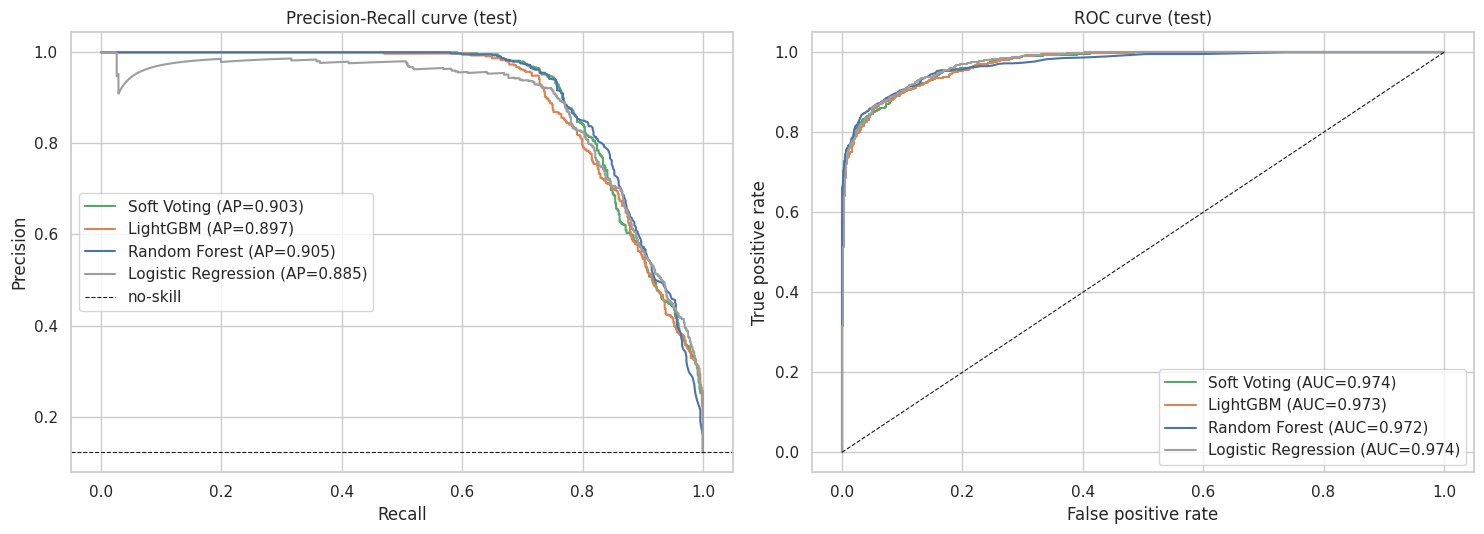

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5.5))
for fam, name in best_by_family.items():
    p = RESULTS[name]['proba_test']
    pr, rc, _ = precision_recall_curve(y['test'], p)
    fpr, tpr, _ = roc_curve(y['test'], p)
    ax[0].plot(rc, pr, label=f'{name} (AP={average_precision_score(y["test"], p):.3f})', color=FAM_COLORS[fam])
    ax[1].plot(fpr, tpr, label=f'{name} (AUC={roc_auc_score(y["test"], p):.3f})', color=FAM_COLORS[fam])
ax[0].axhline(y['test'].mean(), ls='--', c='k', lw=0.8, label='no-skill')
ax[1].plot([0, 1], [0, 1], ls='--', c='k', lw=0.8)
ax[0].set(xlabel='Recall', ylabel='Precision', title='Precision-Recall curve (test)')
ax[1].set(xlabel='False positive rate', ylabel='True positive rate', title='ROC curve (test)')
ax[0].legend(); ax[1].legend(); plt.tight_layout(); plt.show()

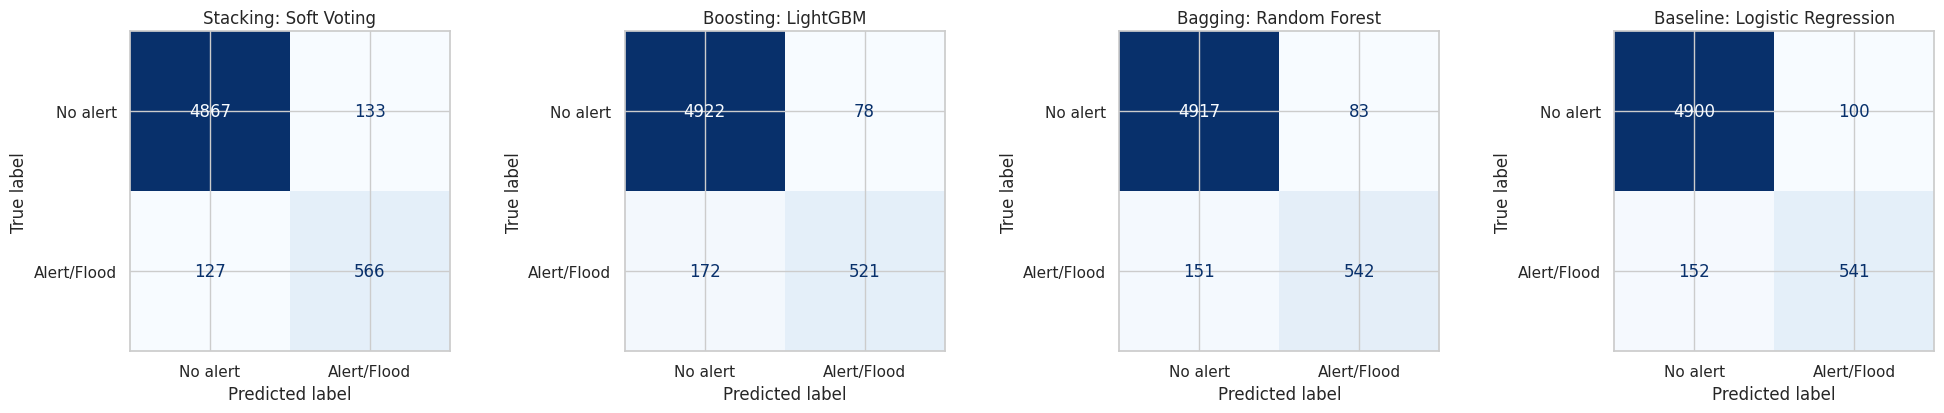

In [ ]:
fig, ax = plt.subplots(1, len(best_by_family), figsize=(5 * len(best_by_family), 4.3))
for a, (fam, name) in zip(np.atleast_1d(ax), best_by_family.items()):
    r = RESULTS[name]
    cm = confusion_matrix(y['test'], (r['proba_test'] >= r['threshold']).astype(int))
    ConfusionMatrixDisplay(cm, display_labels=['No alert', 'Alert/Flood']).plot(ax=a, colorbar=False, cmap='Blues')
    a.set_title(f'{fam}: {name}')
plt.tight_layout(); plt.show()

In [ ]:
rng = np.random.default_rng(RANDOM_STATE)
yt = y['test'].values
B = 1000
idx = [rng.integers(0, len(yt), len(yt)) for _ in range(B)]
ci_rows = []
for name in test_tbl['Model']:
    r = RESULTS[name]; p = r['proba_test']; pred = (p >= r['threshold']).astype(int)
    ap = [average_precision_score(yt[i], p[i]) for i in idx]
    f1 = [f1_score(yt[i], pred[i], zero_division=0) for i in idx]
    ci_rows.append({'Model': name, 'PR_AUC': average_precision_score(yt, p),
                    'PR_AUC_95CI': f'[{np.percentile(ap, 2.5):.3f}, {np.percentile(ap, 97.5):.3f}]',
                    'F1': f1_score(yt, pred), 'F1_95CI': f'[{np.percentile(f1, 2.5):.3f}, {np.percentile(f1, 97.5):.3f}]'})
ci_tbl = pd.DataFrame(ci_rows)
display(ci_tbl.round(4))

,Model,PR_AUC,PR_AUC_95CI,F1,F1_95CI
0,CatBoost,0.9071,"[0.890, 0.922]",0.8368,"[0.814, 0.857]"
1,Random Forest,0.9054,"[0.888, 0.922]",0.8225,"[0.799, 0.844]"
2,Extra Trees,0.9048,"[0.887, 0.922]",0.8252,"[0.803, 0.848]"
3,Soft Voting,0.9032,"[0.885, 0.920]",0.8132,"[0.789, 0.836]"
4,Bagging (DT),0.9018,"[0.884, 0.919]",0.8188,"[0.794, 0.842]"
5,HistGradientBoosting,0.9013,"[0.883, 0.917]",0.8233,"[0.800, 0.844]"
6,Stacking (LR meta),0.9005,"[0.883, 0.917]",0.8177,"[0.795, 0.840]"
7,LightGBM,0.8972,"[0.880, 0.914]",0.8065,"[0.783, 0.829]"
8,XGBoost,0.8940,"[0.876, 0.911]",0.7971,"[0.774, 0.820]"
9,Logistic Regression,0.8849,"[0.863, 0.906]",0.8111,"[0.788, 0.833]"


###Interpretation

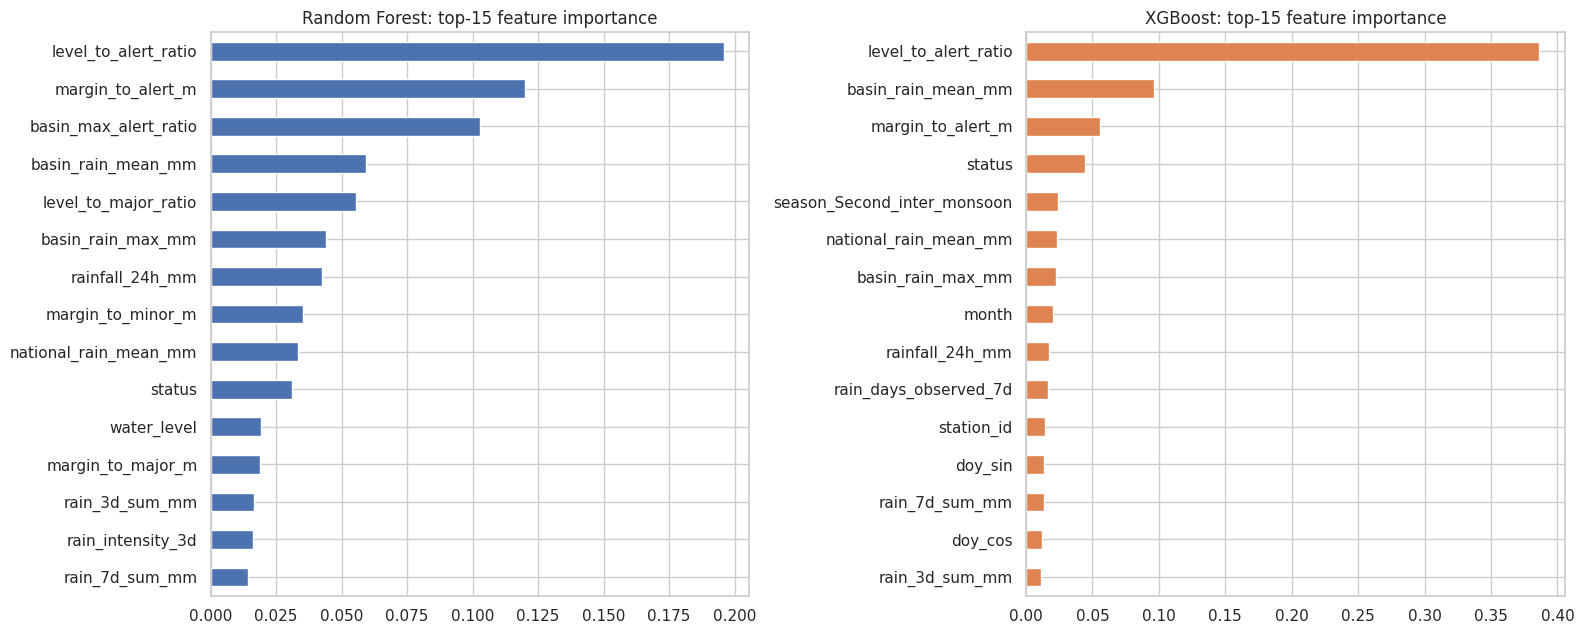

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(16, 6.5))
for a, name in zip(ax, ['Random Forest', 'XGBoost']):
    m = RESULTS[name]['model']; cols = X_of(RESULTS[name]['data'], 'train').columns
    imp = pd.Series(m.feature_importances_, index=cols).sort_values().tail(15)
    imp.plot.barh(ax=a, color=FAM_COLORS[RESULTS[name]['family']])
    a.set_title(f'{name}: top-15 feature importance')
plt.tight_layout(); plt.show()

Permutation importance for Soft Voting (86s)


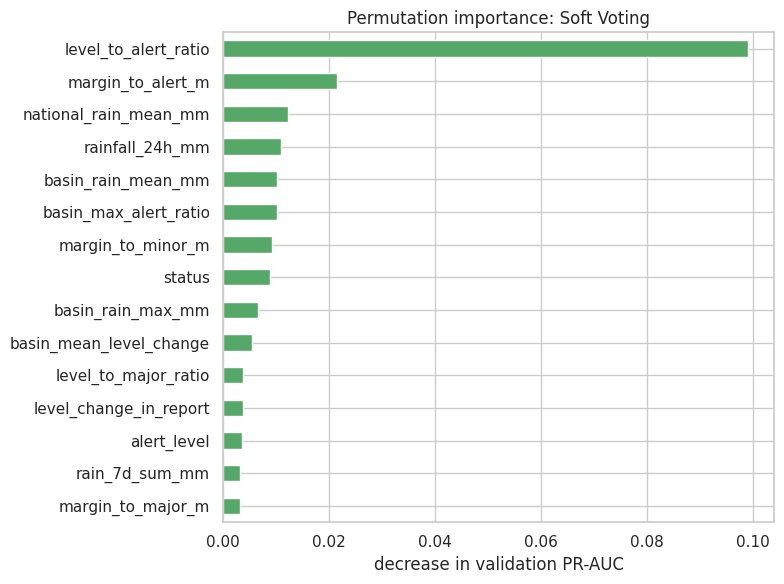

level_to_alert_ratio       0.0991
margin_to_alert_m          0.0216
national_rain_mean_mm      0.0122
rainfall_24h_mm            0.0109
basin_rain_mean_mm         0.0101
basin_max_alert_ratio      0.0101
margin_to_minor_m          0.0091
status                     0.0088
basin_rain_max_mm          0.0065
basin_mean_level_change    0.0054
level_to_major_ratio       0.0038
level_change_in_report     0.0037
alert_level                0.0036
rain_7d_sum_mm             0.0032
margin_to_major_m          0.0031


In [ ]:
best_name = val_tbl.loc[0, 'Model']
r = RESULTS[best_name]
Xv = X_of(r['data'], 'val')
t0 = time.time()
pi = permutation_importance(r['model'], Xv, y['val'], scoring='average_precision', n_repeats=3,
                            random_state=RANDOM_STATE, n_jobs=1)
pim = pd.Series(pi.importances_mean, index=Xv.columns).sort_values(ascending=False)
print(f'Permutation importance for {best_name} ({time.time()-t0:.0f}s)')
plt.figure(figsize=(8, 6)); pim.head(15).sort_values().plot.barh(color='#55A868')
plt.xlabel('decrease in validation PR-AUC'); plt.title(f'Permutation importance: {best_name}')
plt.tight_layout(); plt.show()
print(pim.head(15).round(4).to_string())

###Error Analysis

In [ ]:
cur_normal = (X_raw['test']['status'] == 0).values
ys = y['test'].values[cur_normal]
print(f'Test rows currently Normal: {cur_normal.sum():,} | of which reach Alert+ within 24 h: {ys.sum():,} ({ys.mean():.2%})')
rows = []
for name, r in RESULTS.items():
    p = r['proba_test'][cur_normal]; pred = (p >= r['threshold']).astype(int)
    rows.append({'Model': name, 'Family': r['family'],
                 'PR_AUC': average_precision_score(ys, p) if p.std() > 0 else ys.mean(),
                 'Recall': recall_score(ys, pred, zero_division=0),
                 'Precision': precision_score(ys, pred, zero_division=0),
                 'F1': f1_score(ys, pred, zero_division=0)})
onset_tbl = pd.DataFrame(rows).sort_values('PR_AUC', ascending=False).reset_index(drop=True)
display(onset_tbl.round(4))

Test rows currently Normal: 5,156 | of which reach Alert+ within 24 h: 187 (3.63%)


,Model,Family,PR_AUC,Recall,Precision,F1
0,Extra Trees,Bagging,0.3768,0.3369,0.4257,0.3761
1,CatBoost,Boosting,0.3502,0.3048,0.4790,0.3725
2,Random Forest,Bagging,0.3382,0.2139,0.3883,0.2759
3,Soft Voting,Stacking,0.3245,0.3369,0.3642,0.3500
4,Bagging (DT),Bagging,0.3149,0.1925,0.3711,0.2535
5,HistGradientBoosting,Boosting,0.3128,0.1979,0.4353,0.2721
6,Stacking (LR meta),Stacking,0.3043,0.2674,0.3906,0.3175
7,Logistic Regression,Baseline,0.2975,0.2139,0.3636,0.2694
8,LightGBM,Boosting,0.2799,0.1658,0.3298,0.2206
9,AdaBoost,Boosting,0.2728,0.1123,0.4375,0.1787


In [ ]:
r = RESULTS[best_name]
d = ids['test'][['basin', 'station']].copy()
d['y'] = y['test'].values; d['p'] = r['proba_test']; d['pred'] = (d['p'] >= r['threshold']).astype(int)
def basin_metrics(g):
    return pd.Series({'rows': len(g), 'positives': int(g.y.sum()),
                      'Recall': recall_score(g.y, g.pred, zero_division=0) if g.y.sum() else np.nan,
                      'Precision': precision_score(g.y, g.pred, zero_division=0) if g.pred.sum() else np.nan,
                      'F1': f1_score(g.y, g.pred, zero_division=0) if g.y.sum() else np.nan})
bt = d.groupby('basin').apply(basin_metrics).sort_values('positives', ascending=False)
print(f'Per-basin test performance - {best_name}')
display(bt.round(3))

Per-basin test performance - Soft Voting


,rows,positives,Recall,Precision,F1
basin,,,,,
Nilwala Ganga,602.0,213.0,0.854,0.863,0.858
Kalu Ganga,753.0,213.0,0.944,0.901,0.922
Gin Ganga,301.0,93.0,0.914,0.904,0.909
Attanagalu Oya,151.0,52.0,0.923,0.941,0.932
Walawe Ganga,151.0,50.0,0.540,0.871,0.667
Kelani Ganga,1055.0,43.0,0.279,0.353,0.312
Mahaweli Ganga,709.0,29.0,0.379,0.423,0.400
Deduru Oya,151.0,0.0,NaN,0.000,NaN
Kirindi Oya,452.0,0.0,NaN,0.000,NaN


###Save models and predictions (used by the dashboard)

In [ ]:
for name, r in RESULTS.items():
    if name == 'Persistence':
        continue
    joblib.dump(r['model'], f"{MODEL_DIR}/{name.replace(' ', '_').replace('(', '').replace(')', '')}.joblib")

pred_test = ids['test'][['obs_datetime', 'station', 'basin']].copy()
pred_test['station_id'] = X_raw['test']['station_id'].astype(int).values
pred_test['y_true'] = y['test'].values
for name, r in RESULTS.items():
    pred_test[f'proba__{name}'] = r['proba_test']
pred_test.to_parquet(f'{PROC}/clf_test_predictions.parquet')

val_tbl.to_csv(f'{PROC}/clf_results_val.csv', index=False)
test_tbl.to_csv(f'{PROC}/clf_results_test.csv', index=False)
ci_tbl.to_csv(f'{PROC}/clf_results_test_ci.csv', index=False)
onset_tbl.to_csv(f'{PROC}/clf_results_new_alert.csv', index=False)
json.dump({n: {'family': r['family'], 'data': r['data'], 'threshold': r['threshold'],
               'params': {k: str(v) for k, v in r['params'].items()}} for n, r in RESULTS.items()},
          open(f'{PROC}/clf_model_registry.json', 'w'), indent=2)
print('Saved models to', MODEL_DIR)
print('Saved tables/predictions to', PROC)

Saved models to /content/drive/MyDrive/MachineLearningCA01/processed/models_clf
Saved tables/predictions to /content/drive/MyDrive/MachineLearningCA01/processed


###Summary

In [ ]:
cols = ['Model', 'Family', 'PR_AUC', 'ROC_AUC', 'F1', 'Recall', 'Precision', 'MCC', 'Threshold']
print('=' * 100); print('VALIDATION (model selection)'); print('=' * 100)
print(val_tbl[cols].round(4).to_string(index=False))
print('\n' + '=' * 100); print('TEST (final, untouched)'); print('=' * 100)
print(test_tbl[cols].round(4).to_string(index=False))
print('\nBootstrap 95% CI (test)'); print(ci_tbl.round(4).to_string(index=False))
print('\nNew-alert detection (test rows currently Normal)')
print(onset_tbl.round(4).to_string(index=False))
print('\nBest per family (validation):', best_by_family)
print('Best overall (validation):', best_name)
print('Tuned params:')
for n, r in RESULTS.items():
    if r['params']: print(f'  {n:22s} {r["params"]}')

VALIDATION (model selection)
               Model   Family  PR_AUC  ROC_AUC     F1  Recall  Precision    MCC  Threshold
         Soft Voting Stacking  0.8925   0.9709 0.8159  0.8107     0.8211 0.7920     0.3261
            LightGBM Boosting  0.8913   0.9727 0.8119  0.7524     0.8817 0.7926     0.5574
             XGBoost Boosting  0.8905   0.9703 0.8137  0.8028     0.8250 0.7899     0.2695
  Stacking (LR meta) Stacking  0.8892   0.9710 0.8104  0.7650     0.8615 0.7890     0.8409
            CatBoost Boosting  0.8858   0.9717 0.7929  0.7366     0.8585 0.7710     0.6538
HistGradientBoosting Boosting  0.8816   0.9686 0.8073  0.7334     0.8977 0.7900     0.7057
       Random Forest  Bagging  0.8765   0.9665 0.7839  0.7240     0.8547 0.7616     0.3375
         Extra Trees  Bagging  0.8724   0.9655 0.7875  0.7571     0.8205 0.7618     0.2950
        Bagging (DT)  Bagging  0.8674   0.9650 0.7870  0.7256     0.8598 0.7653     0.4922
 Logistic Regression Baseline  0.8615   0.9640 0.7864  0.7287

##Ensemble Regression and the RF + ANN Hybrid

In [ ]:
from sklearn.linear_model import RidgeCV, LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (BaggingRegressor, RandomForestRegressor, ExtraTreesRegressor, AdaBoostRegressor,
                              HistGradientBoostingRegressor, StackingRegressor, VotingRegressor)
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import KFold, cross_val_predict
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from catboost import CatBoostRegressor

assert 'PROC' in globals(), 'Run Parts 1-2 first in this session (PROC / BASE_DIR not defined)'
print('Using processed data in:', PROC)

Using processed data in: /content/drive/MyDrive/MachineLearningCA01/processed


###Load the regression data

In [ ]:
REG_MODEL_DIR = os.path.join(PROC, 'models_reg'); os.makedirs(REG_MODEL_DIR, exist_ok=True)
SPLITS = ['train', 'val', 'test']

Xr_raw = {s: pd.read_parquet(f'{PROC}/reg_X_{s}_raw.parquet') for s in SPLITS}
Xr_imp = {s: pd.read_parquet(f'{PROC}/reg_X_{s}_imputed.parquet') for s in SPLITS}
Xr_sc = {s: pd.read_parquet(f'{PROC}/reg_X_{s}_scaled.parquet') for s in SPLITS}
y_reg = {s: pd.read_parquet(f'{PROC}/reg_y_{s}.parquet')['y'].values for s in SPLITS}
ids_reg = {s: pd.read_parquet(f'{PROC}/reg_ids_{s}.parquet') for s in SPLITS}

level_now = {s: Xr_raw[s]['water_level'].values for s in SPLITS}
alert = {s: Xr_raw[s]['alert_level'].values for s in SPLITS}
delta = {s: y_reg[s] - level_now[s] for s in SPLITS}

for s in SPLITS:
    print(f'{s:5s} X={Xr_imp[s].shape}  level mean={y_reg[s].mean():.3f} m  change mean={delta[s].mean():+.3f} '
          f'std={delta[s].std():.3f} m')

train X=(21481, 61)  level mean=1.919 m  change mean=-0.023 std=0.833 m
val   X=(5151, 61)  level mean=2.161 m  change mean=+0.018 std=0.651 m
test  X=(5428, 61)  level mean=2.171 m  change mean=-0.076 std=0.593 m


[Text(0.5, 0, '24-h change (m), clipped to +/-3'),
 Text(0.5, 1.0, 'The modelling target: 24-h change')]

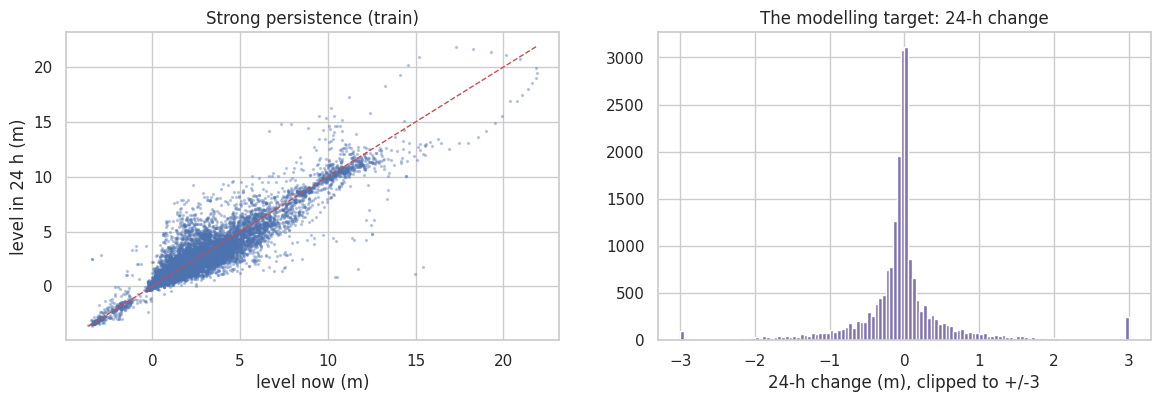

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].scatter(level_now['train'], y_reg['train'], s=2, alpha=0.3)
lim = [min(level_now['train'].min(), y_reg['train'].min()), max(level_now['train'].max(), y_reg['train'].max())]
ax[0].plot(lim, lim, 'r--', lw=1); ax[0].set(xlabel='level now (m)', ylabel='level in 24 h (m)',
                                            title='Strong persistence (train)')
ax[1].hist(np.clip(delta['train'], -3, 3), bins=120, color='#8172B2')
ax[1].set(xlabel='24-h change (m), clipped to +/-3', title='The modelling target: 24-h change')

###Evaluation helpers

In [ ]:
REG_RESULTS = {}
rmse = lambda a, b: float(np.sqrt(mean_squared_error(a, b)))
PERSIST_RMSE = {s: rmse(y_reg[s], level_now[s]) for s in SPLITS}

def reg_evaluate(split, pred):
    yt, al = y_reg[split], alert[split]
    high = yt >= 0.8 * al
    warn_true, warn_pred = (yt >= al).astype(int), (pred >= al).astype(int)
    return {'MAE': mean_absolute_error(yt, pred), 'RMSE': rmse(yt, pred), 'R2': r2_score(yt, pred),
            'Skill': 1 - rmse(yt, pred) / PERSIST_RMSE[split],
            'MAE_high': mean_absolute_error(yt[high], pred[high]),
            'Warn_F1': f1_score(warn_true, warn_pred, zero_division=0),
            'Warn_Recall': recall_score(warn_true, warn_pred, zero_division=0)}

def Xr_of(data, split):
    return {'raw': Xr_raw, 'imputed': Xr_imp, 'scaled': Xr_sc}[data][split]

def reg_register(name, family, pred_val, pred_test, model=None, data=None, params=None, fit_s=np.nan):
    REG_RESULTS[name] = dict(family=family, pred_val=np.asarray(pred_val), pred_test=np.asarray(pred_test),
                         model=model, data=data, params=params or {}, fit_s=fit_s)
    m = reg_evaluate('val', np.asarray(pred_val))
    print(f'{name:26s} VAL  RMSE={m["RMSE"]:.4f}  MAE={m["MAE"]:.4f}  Skill={m["Skill"]:+.3f}  '
          f'MAE_high={m["MAE_high"]:.3f}  fit={fit_s:.1f}s')

def reg_register_model(name, family, model, data, params=None, fit_s=np.nan):
    pv = level_now['val'] + model.predict(Xr_of(data, 'val'))
    pt = level_now['test'] + model.predict(Xr_of(data, 'test'))
    reg_register(name, family, pv, pt, model, data, params, fit_s)

def reg_tune(name, family, make_model, grid, data):
    keys, best = list(grid), (np.inf, None, None, None)
    for vals in product(*[grid[k] for k in keys]):
        params = dict(zip(keys, vals))
        t0 = time.time(); m = make_model(**params)
        m.fit(Xr_of(data, 'train'), delta['train']); fit_s = time.time() - t0
        r = rmse(y_reg['val'], level_now['val'] + m.predict(Xr_of(data, 'val')))
        print(f'   {params}  val RMSE={r:.4f}  ({fit_s:.1f}s)')
        if r < best[0]:
            best = (r, m, params, fit_s)
    print(f' -> best {best[2]}')
    reg_register_model(name, family, best[1], data, best[2], best[3])
    return best[1]

###Baselines

In [ ]:
reg_register('Persistence', 'Baseline', level_now['val'], level_now['test'])

t0 = time.time()
ridge = RidgeCV(alphas=np.logspace(-2, 3, 12)).fit(Xr_sc['train'], delta['train'])
reg_register_model('Ridge Regression', 'Baseline', ridge, 'scaled', {'alpha': round(float(ridge.alpha_), 3)}, time.time() - t0)

print('\nDecision tree grid:')
dt_reg = reg_tune('Decision Tree', 'Baseline', lambda **p: DecisionTreeRegressor(random_state=RANDOM_STATE, **p),
          {'max_depth': [8, 12], 'min_samples_leaf': [20, 50]}, 'imputed')

print('\nANN (MLP) grid:')
ann_reg = reg_tune('ANN (MLP)', 'ANN',
           lambda **p: MLPRegressor(hidden_layer_sizes=p.pop('layers'), early_stopping=True, max_iter=300,
                                    learning_rate_init=1e-3, random_state=RANDOM_STATE, **p),
           {'layers': [(64, 32), (128, 64)], 'alpha': [1e-4, 1e-3]}, 'scaled')

Persistence                VAL  RMSE=0.6516  MAE=0.3903  Skill=+0.000  MAE_high=0.792  fit=nans
Ridge Regression           VAL  RMSE=0.5754  MAE=0.3798  Skill=+0.117  MAE_high=0.687  fit=0.2s

Decision tree grid:
   {'max_depth': 8, 'min_samples_leaf': 20}  val RMSE=0.6223  (0.5s)
   {'max_depth': 8, 'min_samples_leaf': 50}  val RMSE=0.6338  (0.4s)
   {'max_depth': 12, 'min_samples_leaf': 20}  val RMSE=0.6691  (0.7s)
   {'max_depth': 12, 'min_samples_leaf': 50}  val RMSE=0.6598  (0.6s)
 -> best {'max_depth': 8, 'min_samples_leaf': 20}
Decision Tree              VAL  RMSE=0.6223  MAE=0.3846  Skill=+0.045  MAE_high=0.741  fit=0.5s

ANN (MLP) grid:
   {'layers': (64, 32), 'alpha': 0.0001}  val RMSE=0.5840  (7.4s)
   {'layers': (64, 32), 'alpha': 0.001}  val RMSE=0.5870  (8.1s)
   {'layers': (128, 64), 'alpha': 0.0001}  val RMSE=0.6062  (28.4s)
   {'layers': (128, 64), 'alpha': 0.001}  val RMSE=0.5825  (14.7s)
 -> best {'layers': (128, 64), 'alpha': 0.001}
ANN (MLP)                  VAL  R

###Bagging

In [ ]:
print('BaggingRegressor grid:')
bag_reg = reg_tune('Bagging (DT)', 'Bagging',
           lambda **p: BaggingRegressor(estimator=DecisionTreeRegressor(min_samples_leaf=5), n_estimators=100,
                                        n_jobs=N_JOBS, random_state=RANDOM_STATE, **p),
           {'max_samples': [0.5, 1.0]}, 'imputed')

print('\nRandom Forest grid:')
rf_reg = reg_tune('Random Forest', 'Bagging',
          lambda **p: RandomForestRegressor(n_estimators=300, n_jobs=N_JOBS, random_state=RANDOM_STATE, **p),
          {'max_features': [0.3, 'sqrt'], 'min_samples_leaf': [2, 5]}, 'imputed')

print('\nExtra Trees grid:')
et_reg = reg_tune('Extra Trees', 'Bagging',
          lambda **p: ExtraTreesRegressor(n_estimators=300, n_jobs=N_JOBS, random_state=RANDOM_STATE, **p),
          {'max_features': [0.5, 1.0], 'min_samples_leaf': [2, 5]}, 'imputed')

BaggingRegressor grid:
   {'max_samples': 0.5}  val RMSE=0.5516  (70.9s)
   {'max_samples': 1.0}  val RMSE=0.5466  (99.7s)
 -> best {'max_samples': 1.0}
Bagging (DT)               VAL  RMSE=0.5466  MAE=0.3335  Skill=+0.161  MAE_high=0.646  fit=99.7s

Random Forest grid:
   {'max_features': 0.3, 'min_samples_leaf': 2}  val RMSE=0.5460  (125.4s)
   {'max_features': 0.3, 'min_samples_leaf': 5}  val RMSE=0.5465  (87.6s)
   {'max_features': 'sqrt', 'min_samples_leaf': 2}  val RMSE=0.5452  (38.5s)
   {'max_features': 'sqrt', 'min_samples_leaf': 5}  val RMSE=0.5453  (32.3s)
 -> best {'max_features': 'sqrt', 'min_samples_leaf': 2}
Random Forest              VAL  RMSE=0.5452  MAE=0.3300  Skill=+0.163  MAE_high=0.642  fit=38.5s

Extra Trees grid:
   {'max_features': 0.5, 'min_samples_leaf': 2}  val RMSE=0.5447  (31.9s)
   {'max_features': 0.5, 'min_samples_leaf': 5}  val RMSE=0.5479  (22.4s)
   {'max_features': 1.0, 'min_samples_leaf': 2}  val RMSE=0.5430  (59.1s)
   {'max_features': 1.0, 'min_s

###Boosting

In [ ]:
print('AdaBoost grid:')
ada_reg = reg_tune('AdaBoost', 'Boosting',
           lambda **p: AdaBoostRegressor(estimator=DecisionTreeRegressor(max_depth=p.pop('depth')),
                                         n_estimators=200, random_state=RANDOM_STATE, **p),
           {'depth': [4], 'learning_rate': [0.05, 0.2]}, 'imputed')

print('\nHistGradientBoosting grid:')
hgb_reg = reg_tune('HistGradientBoosting', 'Boosting',
           lambda **p: HistGradientBoostingRegressor(max_iter=500, random_state=RANDOM_STATE, **p),
           {'learning_rate': [0.05, 0.1], 'max_leaf_nodes': [15, 31]}, 'raw')

print('\nXGBoost grid:')
xgbm_reg = reg_tune('XGBoost', 'Boosting',
            lambda **p: xgb.XGBRegressor(n_estimators=500, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8,
                                         tree_method='hist', n_jobs=N_JOBS, random_state=RANDOM_STATE, **p),
            {'max_depth': [4, 6], 'min_child_weight': [1, 5]}, 'raw')

print('\nLightGBM grid:')
lgbm_reg = reg_tune('LightGBM', 'Boosting',
            lambda **p: lgb.LGBMRegressor(n_estimators=500, learning_rate=0.05, subsample=0.8, subsample_freq=1,
                                          colsample_bytree=0.8, n_jobs=N_JOBS, random_state=RANDOM_STATE,
                                          verbose=-1, **p),
            {'num_leaves': [15, 31], 'min_child_samples': [20, 50]}, 'raw')

print('\nCatBoost grid:')
cat_reg = reg_tune('CatBoost', 'Boosting',
           lambda **p: CatBoostRegressor(iterations=500, depth=6, random_seed=RANDOM_STATE, verbose=0,
                                         thread_count=-1, **p),
           {'learning_rate': [0.05, 0.1]}, 'raw')

AdaBoost grid:
   {'depth': 4, 'learning_rate': 0.05}  val RMSE=0.6421  (49.9s)
   {'depth': 4, 'learning_rate': 0.2}  val RMSE=0.9740  (38.4s)
 -> best {'depth': 4, 'learning_rate': 0.05}
AdaBoost                   VAL  RMSE=0.6421  MAE=0.4323  Skill=+0.015  MAE_high=0.739  fit=49.9s

HistGradientBoosting grid:
   {'learning_rate': 0.05, 'max_leaf_nodes': 15}  val RMSE=0.5407  (3.4s)
   {'learning_rate': 0.05, 'max_leaf_nodes': 31}  val RMSE=0.5399  (5.4s)
   {'learning_rate': 0.1, 'max_leaf_nodes': 15}  val RMSE=0.5479  (4.3s)
   {'learning_rate': 0.1, 'max_leaf_nodes': 31}  val RMSE=0.5545  (4.8s)
 -> best {'learning_rate': 0.05, 'max_leaf_nodes': 31}
HistGradientBoosting       VAL  RMSE=0.5399  MAE=0.3299  Skill=+0.171  MAE_high=0.652  fit=5.4s

XGBoost grid:
   {'max_depth': 4, 'min_child_weight': 1}  val RMSE=0.5500  (2.4s)
   {'max_depth': 4, 'min_child_weight': 5}  val RMSE=0.5451  (5.5s)
   {'max_depth': 6, 'min_child_weight': 1}  val RMSE=0.5439  (5.8s)
   {'max_depth': 6, 'm

###Stacking and averaging

In [ ]:
def light(name, n_trees=200):
    m = clone(REG_RESULTS[name]['model'])
    if 'n_estimators' in m.get_params() and name in ('Random Forest', 'Extra Trees'):
        m.set_params(n_estimators=n_trees)
    return m

reg_base = [('rf', light('Random Forest')), ('et', light('Extra Trees')), ('xgb', light('XGBoost')),
        ('lgbm', light('LightGBM')), ('cat', light('CatBoost'))]

t0 = time.time()
reg_stack = StackingRegressor(estimators=reg_base, final_estimator=LinearRegression(positive=True),
                          cv=KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE), n_jobs=1)
reg_stack.fit(Xr_imp['train'], delta['train'])
reg_register_model('Stacking (non-neg LR)', 'Stacking', reg_stack, 'imputed', {'cv': 'KFold(5, shuffle)'}, time.time() - t0)
reg_stack_w = pd.Series(reg_stack.final_estimator_.coef_, index=[n for n, _ in reg_base])
print('Meta-learner weights:', reg_stack_w.round(3).to_dict(), '| intercept', round(float(reg_stack.final_estimator_.intercept_), 4))

t0 = time.time()
reg_vote = VotingRegressor(estimators=[(n, clone(m)) for n, m in reg_base], n_jobs=1).fit(Xr_imp['train'], delta['train'])
reg_register_model('Averaging (Voting)', 'Stacking', reg_vote, 'imputed', {}, time.time() - t0)

Stacking (non-neg LR)      VAL  RMSE=0.5415  MAE=0.3279  Skill=+0.169  MAE_high=0.651  fit=578.5s
Meta-learner weights: {'rf': 0.0, 'et': 0.553, 'xgb': 0.257, 'lgbm': 0.293, 'cat': 0.0} | intercept -0.0013
Averaging (Voting)         VAL  RMSE=0.5336  MAE=0.3203  Skill=+0.181  MAE_high=0.636  fit=76.8s


###RF + ANN hybrids

In [ ]:
# ---------- H1: sequential residual hybrid ----------
t0 = time.time()
rf_h = light('Random Forest')
kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
rf_oof = cross_val_predict(rf_h, Xr_imp['train'], delta['train'], cv=kf, n_jobs=1)
rf_h.fit(Xr_imp['train'], delta['train'])
rf_pred = {'train': rf_oof, 'val': rf_h.predict(Xr_imp['val']), 'test': rf_h.predict(Xr_imp['test'])}
resid_train = delta['train'] - rf_oof
d_std = delta['train'].std()

def ann_input(split):
    return np.column_stack([Xr_sc[split].values, rf_pred[split] / d_std])

best = (np.inf, None, None)
for alpha in [1e-3, 1e-2]:
    ann_r = MLPRegressor(hidden_layer_sizes=(64, 32), alpha=alpha, early_stopping=True, max_iter=300,
                         random_state=RANDOM_STATE).fit(ann_input('train'), resid_train)
    pv = level_now['val'] + rf_pred['val'] + ann_r.predict(ann_input('val'))
    r = rmse(y_reg['val'], pv); print(f'   residual ANN alpha={alpha}: val RMSE={r:.4f}')
    if r < best[0]:
        best = (r, ann_r, alpha)
ann_r = best[1]
pv = level_now['val'] + rf_pred['val'] + ann_r.predict(ann_input('val'))
pt = level_now['test'] + rf_pred['test'] + ann_r.predict(ann_input('test'))
reg_register('H1 RF+ANN residual', 'Hybrid', pv, pt, model={'rf': rf_h, 'ann_residual': ann_r},
         params={'ann_alpha': best[2]}, fit_s=time.time() - t0)

   residual ANN alpha=0.001: val RMSE=0.5713
   residual ANN alpha=0.01: val RMSE=0.5778
H1 RF+ANN residual         VAL  RMSE=0.5713  MAE=0.3597  Skill=+0.123  MAE_high=0.695  fit=107.0s


In [ ]:
# ---------- H2: parallel stacking hybrid (RF || ANN -> non-negative linear meta) ----------
t0 = time.time()
ann_best = REG_RESULTS['ANN (MLP)']['model']
ann_pipe = make_pipeline(StandardScaler(), clone(ann_best))
h2 = StackingRegressor(estimators=[('rf', light('Random Forest')), ('ann', ann_pipe)],
                       final_estimator=LinearRegression(positive=True), cv=kf, n_jobs=1)
h2.fit(Xr_imp['train'], delta['train'])
reg_register_model('H2 RF+ANN stacking', 'Hybrid', h2, 'imputed', {'cv': 'KFold(5, shuffle)'}, time.time() - t0)
print('H2 meta weights:', dict(zip(['rf', 'ann'], np.round(h2.final_estimator_.coef_, 3))))

H2 RF+ANN stacking         VAL  RMSE=0.5367  MAE=0.3319  Skill=+0.176  MAE_high=0.635  fit=193.4s
H2 meta weights: {'rf': np.float64(0.891), 'ann': np.float64(0.287)}


H3 RF+ANN blend            VAL  RMSE=0.5243  MAE=0.3218  Skill=+0.195  MAE_high=0.608  fit=nans


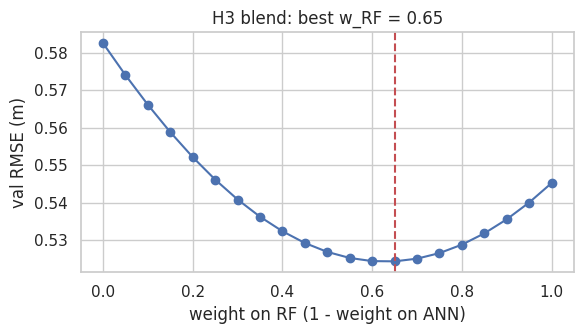

In [ ]:
# ---------- H3: weighted blend, weight chosen on validation ----------
p_rf = {s: REG_RESULTS['Random Forest'][f'pred_{s}'] for s in ['val', 'test']}
p_ann = {s: REG_RESULTS['ANN (MLP)'][f'pred_{s}'] for s in ['val', 'test']}
ws = np.round(np.arange(0, 1.0001, 0.05), 2)
val_rmse = [rmse(y_reg['val'], w * p_rf['val'] + (1 - w) * p_ann['val']) for w in ws]
w_best = float(ws[int(np.argmin(val_rmse))])
reg_register('H3 RF+ANN blend', 'Hybrid', w_best * p_rf['val'] + (1 - w_best) * p_ann['val'],
         w_best * p_rf['test'] + (1 - w_best) * p_ann['test'], params={'w_rf': w_best})
plt.figure(figsize=(6, 3.5)); plt.plot(ws, val_rmse, marker='o')
plt.axvline(w_best, ls='--', c='r'); plt.xlabel('weight on RF (1 - weight on ANN)'); plt.ylabel('val RMSE (m)')
plt.title(f'H3 blend: best w_RF = {w_best}'); plt.tight_layout(); plt.show()

###Validation comparison (model selection)

In [ ]:
REG_FAM_COLORS = {'Baseline': '#9E9E9E', 'ANN': '#8172B2', 'Bagging': '#4C72B0', 'Boosting': '#DD8452',
              'Stacking': '#55A868', 'Hybrid': '#C44E52'}

def reg_table(split):
    rows = [{'Model': n, 'Family': r['family'], **reg_evaluate(split, r[f'pred_{split}']), 'Fit_s': r['fit_s']}
            for n, r in REG_RESULTS.items()]
    return pd.DataFrame(rows).sort_values('RMSE').reset_index(drop=True)

def reg_show(t):
    try:
        display(t.style.format({c: '{:.4f}' for c in ['MAE', 'RMSE', 'R2', 'Skill', 'MAE_high', 'Warn_F1',
                                                       'Warn_Recall']} | {'Fit_s': '{:.1f}'})
                .background_gradient(subset=['Skill'], cmap='Greens')
                .background_gradient(subset=['RMSE', 'MAE_high'], cmap='Reds_r'))
    except Exception:
        display(t.round(4))

reg_val_tbl = reg_table('val'); reg_show(reg_val_tbl)

,Model,Family,MAE,RMSE,R2,Skill,MAE_high,Warn_F1,Warn_Recall,Fit_s
0,H3 RF+ANN blend,Hybrid,0.3218,0.5243,0.9538,0.1953,0.6076,0.7574,0.6413,nan
1,Averaging (Voting),Stacking,0.3203,0.5336,0.9522,0.1811,0.6358,0.7493,0.6390,76.8
2,H2 RF+ANN stacking,Hybrid,0.3319,0.5367,0.9516,0.1763,0.6346,0.7407,0.6176,193.4
3,CatBoost,Boosting,0.3285,0.5377,0.9514,0.1748,0.6528,0.7448,0.6413,8.4
4,HistGradientBoosting,Boosting,0.3299,0.5399,0.9510,0.1714,0.6515,0.7455,0.6366,5.4
5,Stacking (non-neg LR),Stacking,0.3279,0.5415,0.9507,0.1690,0.6506,0.7437,0.6271,578.5
6,LightGBM,Boosting,0.3285,0.5429,0.9505,0.1668,0.6594,0.7497,0.6437,3.3
7,Extra Trees,Bagging,0.3314,0.5430,0.9505,0.1667,0.6368,0.7528,0.6437,59.1
8,XGBoost,Boosting,0.3289,0.5431,0.9504,0.1666,0.6565,0.7444,0.6295,7.7
9,Random Forest,Bagging,0.3300,0.5452,0.9500,0.1632,0.6419,0.7507,0.6366,38.5


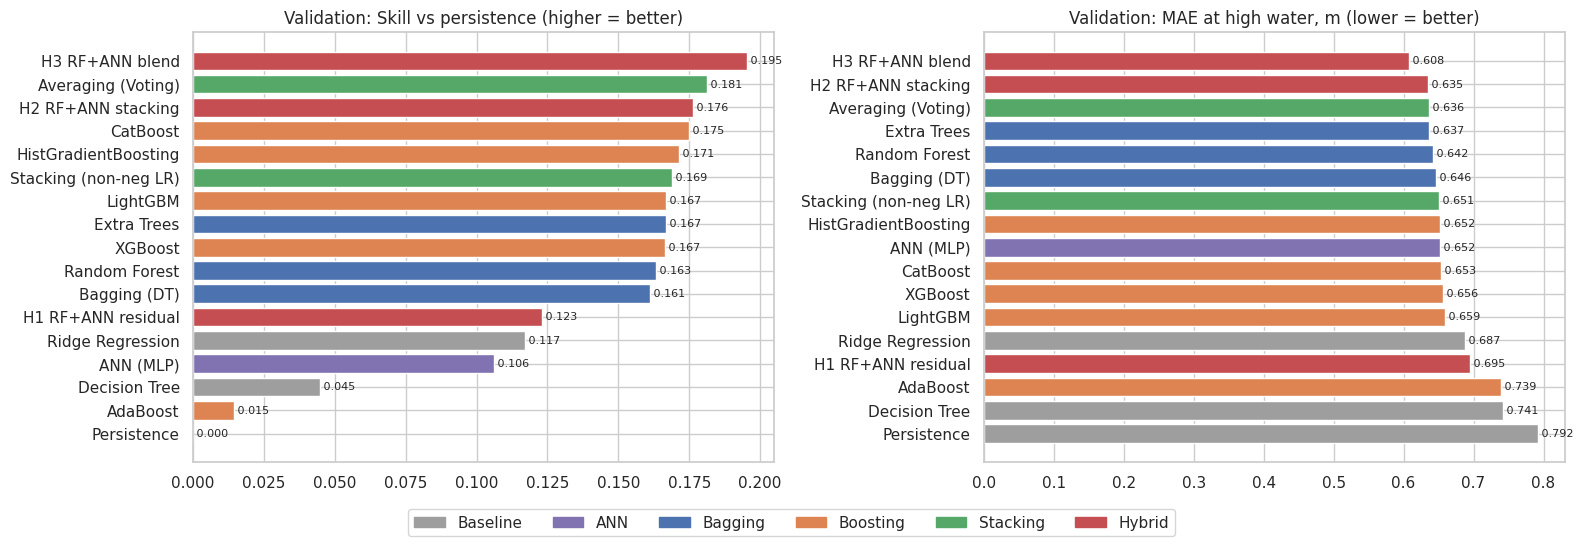

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(16, 5.5))
for a, metric, title in [(ax[0], 'Skill', 'Skill vs persistence (higher = better)'),
                         (ax[1], 'MAE_high', 'MAE at high water, m (lower = better)')]:
    t = reg_val_tbl.sort_values(metric, ascending=(metric == 'Skill'))
    a.barh(t['Model'], t[metric], color=t['Family'].map(REG_FAM_COLORS)); a.set_title('Validation: ' + title)
    for i, v in enumerate(t[metric]): a.text(v, i, f' {v:.3f}', va='center', fontsize=8)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in REG_FAM_COLORS.values()]
fig.legend(handles, REG_FAM_COLORS.keys(), loc='lower center', ncol=6)
plt.tight_layout(rect=(0, 0.06, 1, 1)); plt.show()

### Final test evaluation

In [ ]:
reg_test_tbl = reg_table('test'); reg_show(reg_test_tbl)
reg_best_by_family = reg_val_tbl.groupby('Family').head(1).set_index('Family')['Model'].to_dict()
reg_best_name = reg_val_tbl.loc[0, 'Model']
print('Best per family (chosen on validation):', reg_best_by_family)
print('Best overall (validation):', reg_best_name)

,Model,Family,MAE,RMSE,R2,Skill,MAE_high,Warn_F1,Warn_Recall,Fit_s
0,Averaging (Voting),Stacking,0.3061,0.4957,0.9495,0.1714,0.5548,0.7766,0.6770,76.8
1,Random Forest,Bagging,0.3066,0.5000,0.9487,0.1642,0.5656,0.7659,0.6659,38.5
2,CatBoost,Boosting,0.3166,0.5034,0.9480,0.1586,0.5581,0.7545,0.6460,8.4
3,H3 RF+ANN blend,Hybrid,0.3176,0.5061,0.9474,0.1539,0.5531,0.7694,0.6681,nan
4,Extra Trees,Bagging,0.3134,0.5062,0.9474,0.1539,0.5603,0.7332,0.6173,59.1
5,Stacking (non-neg LR),Stacking,0.3150,0.5093,0.9467,0.1486,0.5834,0.7391,0.6173,578.5
6,LightGBM,Boosting,0.3185,0.5114,0.9463,0.1451,0.5636,0.7577,0.6571,3.3
7,H1 RF+ANN residual,Hybrid,0.3260,0.5121,0.9461,0.1440,0.5619,0.7649,0.6659,107.0
8,HistGradientBoosting,Boosting,0.3166,0.5122,0.9461,0.1437,0.5835,0.7516,0.6460,5.4
9,XGBoost,Boosting,0.3236,0.5157,0.9454,0.1380,0.5905,0.7406,0.6350,7.7


Best per family (chosen on validation): {'Hybrid': 'H3 RF+ANN blend', 'Stacking': 'Averaging (Voting)', 'Boosting': 'CatBoost', 'Bagging': 'Extra Trees', 'Baseline': 'Ridge Regression', 'ANN': 'ANN (MLP)'}
Best overall (validation): H3 RF+ANN blend


In [ ]:
rng = np.random.default_rng(RANDOM_STATE)
yt = y_reg['test']; n = len(yt)
idx = rng.integers(0, n, size=(1000, n))
ci_rows = []
for name in reg_test_tbl['Model']:
    e = REG_RESULTS[name]['pred_test'] - yt
    rm_b = np.sqrt((e[idx] ** 2).mean(axis=1)); ma_b = np.abs(e[idx]).mean(axis=1)
    ci_rows.append({'Model': name, 'RMSE': np.sqrt((e ** 2).mean()),
                    'RMSE_95CI': f'[{np.percentile(rm_b, 2.5):.3f}, {np.percentile(rm_b, 97.5):.3f}]',
                    'MAE': np.abs(e).mean(),
                    'MAE_95CI': f'[{np.percentile(ma_b, 2.5):.3f}, {np.percentile(ma_b, 97.5):.3f}]'})
reg_ci_tbl = pd.DataFrame(ci_rows); display(reg_ci_tbl.round(4))

,Model,RMSE,RMSE_95CI,MAE,MAE_95CI
0,Averaging (Voting),0.4957,"[0.473, 0.518]",0.3061,"[0.295, 0.316]"
1,Random Forest,0.5000,"[0.476, 0.523]",0.3066,"[0.296, 0.317]"
2,CatBoost,0.5034,"[0.481, 0.525]",0.3166,"[0.306, 0.327]"
3,H3 RF+ANN blend,0.5061,"[0.483, 0.527]",0.3176,"[0.307, 0.328]"
4,Extra Trees,0.5062,"[0.483, 0.529]",0.3134,"[0.303, 0.324]"
5,Stacking (non-neg LR),0.5093,"[0.486, 0.531]",0.3150,"[0.304, 0.325]"
6,LightGBM,0.5114,"[0.487, 0.533]",0.3185,"[0.308, 0.329]"
7,H1 RF+ANN residual,0.5121,"[0.489, 0.535]",0.3260,"[0.315, 0.337]"
8,HistGradientBoosting,0.5122,"[0.489, 0.535]",0.3166,"[0.305, 0.327]"
9,XGBoost,0.5157,"[0.492, 0.537]",0.3236,"[0.313, 0.334]"


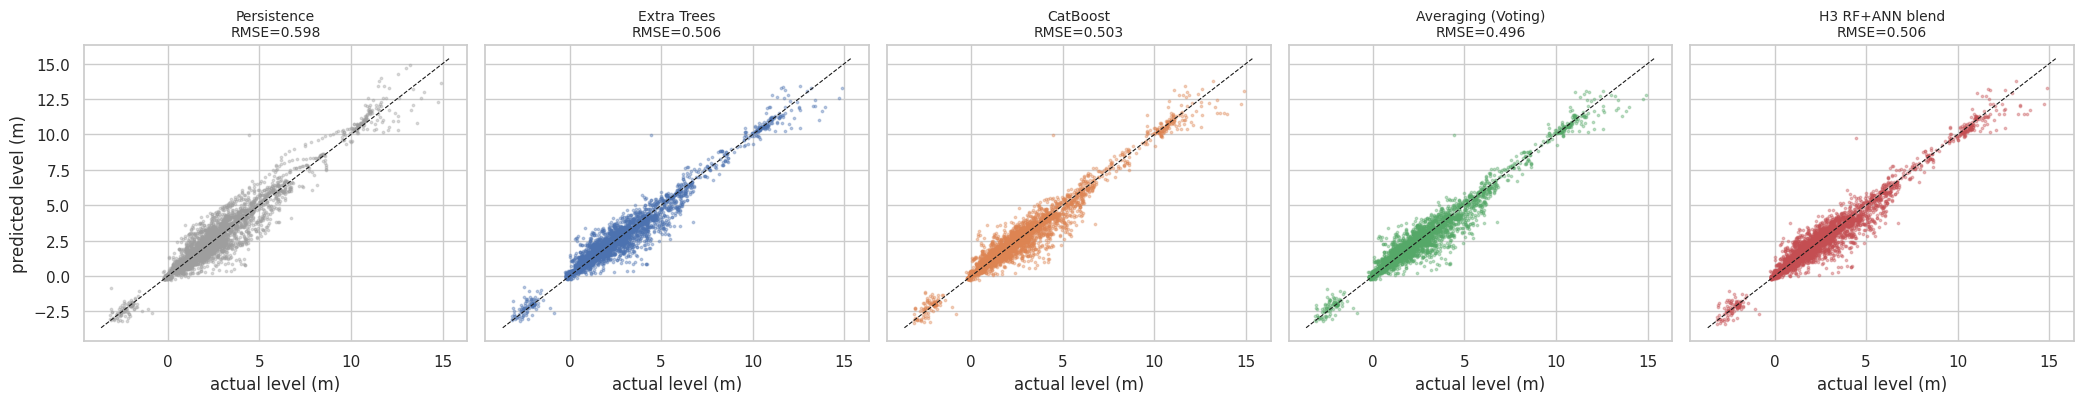

In [ ]:
names = ['Persistence'] + [reg_best_by_family[f] for f in ['Bagging', 'Boosting', 'Stacking', 'Hybrid'] if f in reg_best_by_family]
fig, ax = plt.subplots(1, len(names), figsize=(4.2 * len(names), 4.2), sharex=True, sharey=True)
for a, name in zip(ax, names):
    p = REG_RESULTS[name]['pred_test']
    a.scatter(yt, p, s=3, alpha=0.35, color=REG_FAM_COLORS[REG_RESULTS[name]['family']])
    lim = [yt.min() - 0.5, yt.max() + 0.5]; a.plot(lim, lim, 'k--', lw=0.8)
    a.set_title(f'{name}\nRMSE={rmse(yt, p):.3f}', fontsize=10); a.set_xlabel('actual level (m)')
ax[0].set_ylabel('predicted level (m)'); plt.tight_layout(); plt.show()

###Error analysis

Test MAE (m) by water-level band


,Persistence,Extra Trees,CatBoost,Averaging (Voting),H3 RF+ANN blend,rows
<50% alert,0.252,0.249,0.248,0.237,0.254,3073
50-80%,0.485,0.309,0.326,0.311,0.319,1532
80-100%,0.754,0.557,0.561,0.563,0.556,374
>= alert,0.537,0.562,0.555,0.547,0.551,449


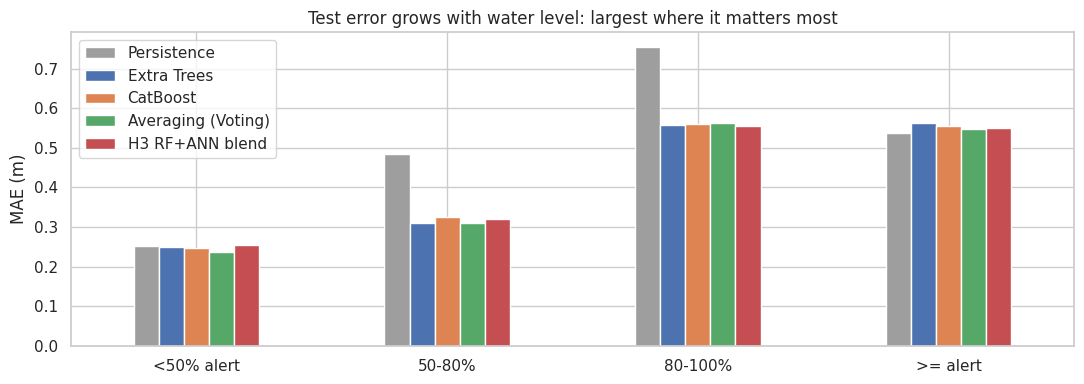

In [ ]:
ratio = yt / alert['test']
bands = pd.cut(ratio, [-np.inf, 0.5, 0.8, 1.0, np.inf], labels=['<50% alert', '50-80%', '80-100%', '>= alert'])
rows = []
for name in names:
    e = np.abs(REG_RESULTS[name]['pred_test'] - yt)
    rows.append(pd.Series(e).groupby(bands, observed=False).mean().rename(name))
band_tbl = pd.DataFrame(rows).T
band_tbl['rows'] = pd.Series(bands).value_counts().reindex(band_tbl.index).values
print('Test MAE (m) by water-level band'); display(band_tbl.round(3))
band_tbl.drop(columns='rows').plot.bar(figsize=(11, 4), color=[REG_FAM_COLORS[REG_RESULTS[n]['family']] for n in names])
plt.ylabel('MAE (m)'); plt.title('Test error grows with water level: largest where it matters most')
plt.xticks(rotation=0); plt.tight_layout(); plt.show()

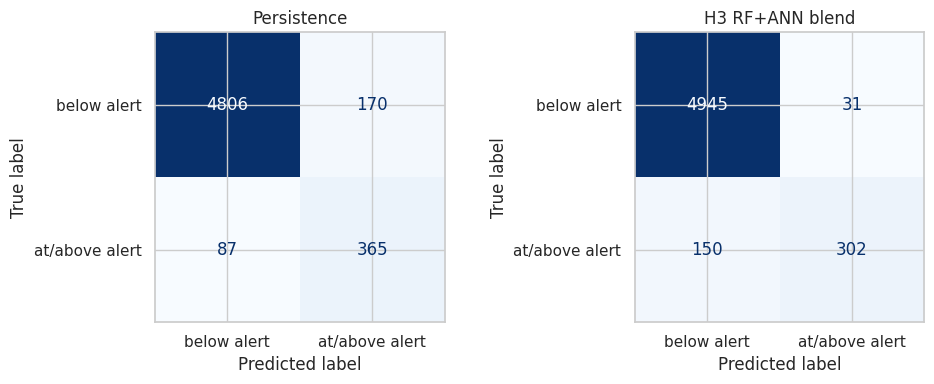

In [ ]:
r = REG_RESULTS[reg_best_name]
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for a, name in zip(ax, ['Persistence', reg_best_name]):
    cm = confusion_matrix((yt >= alert['test']).astype(int), (REG_RESULTS[name]['pred_test'] >= alert['test']).astype(int))
    ConfusionMatrixDisplay(cm, display_labels=['below alert', 'at/above alert']).plot(ax=a, colorbar=False, cmap='Blues')
    a.set_title(name)
plt.tight_layout(); plt.show()

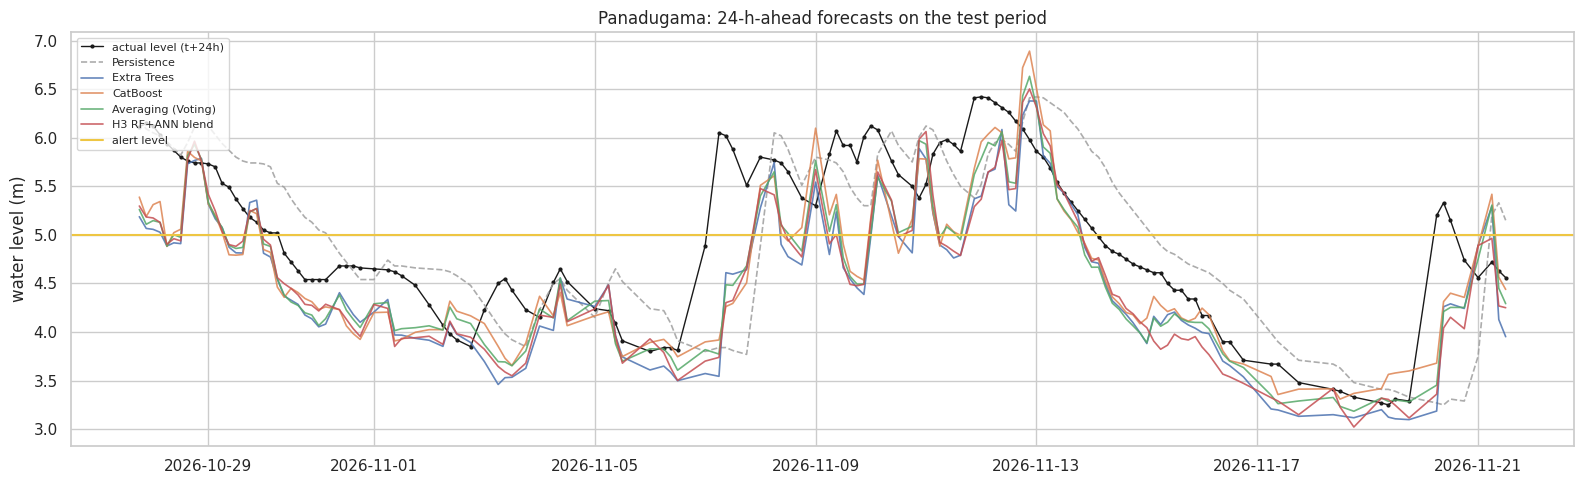

In [ ]:
d = ids_reg['test'][['obs_datetime', 'station']].copy()
d['actual'] = yt; d['alert'] = alert['test']
st = d[d.actual >= 0.8 * d.alert].station.value_counts().index[0]
m = (d.station == st).values
fig, ax = plt.subplots(figsize=(16, 5))
ax.plot(d.obs_datetime[m], d.actual[m], 'k.-', lw=1, ms=4, label='actual level (t+24h)')
for name in names:
    ax.plot(d.obs_datetime[m], REG_RESULTS[name]['pred_test'][m], lw=1.2, alpha=0.85, label=name,
            color=REG_FAM_COLORS[REG_RESULTS[name]['family']], ls='--' if name == 'Persistence' else '-')
ax.axhline(d.alert[m].iloc[0], color='#EEC643', lw=1.5, label='alert level')
ax.set_title(f'{st}: 24-h-ahead forecasts on the test period'); ax.set_ylabel('water level (m)')
ax.legend(loc='upper left', fontsize=8); plt.tight_layout(); plt.show()

###Feature Importance

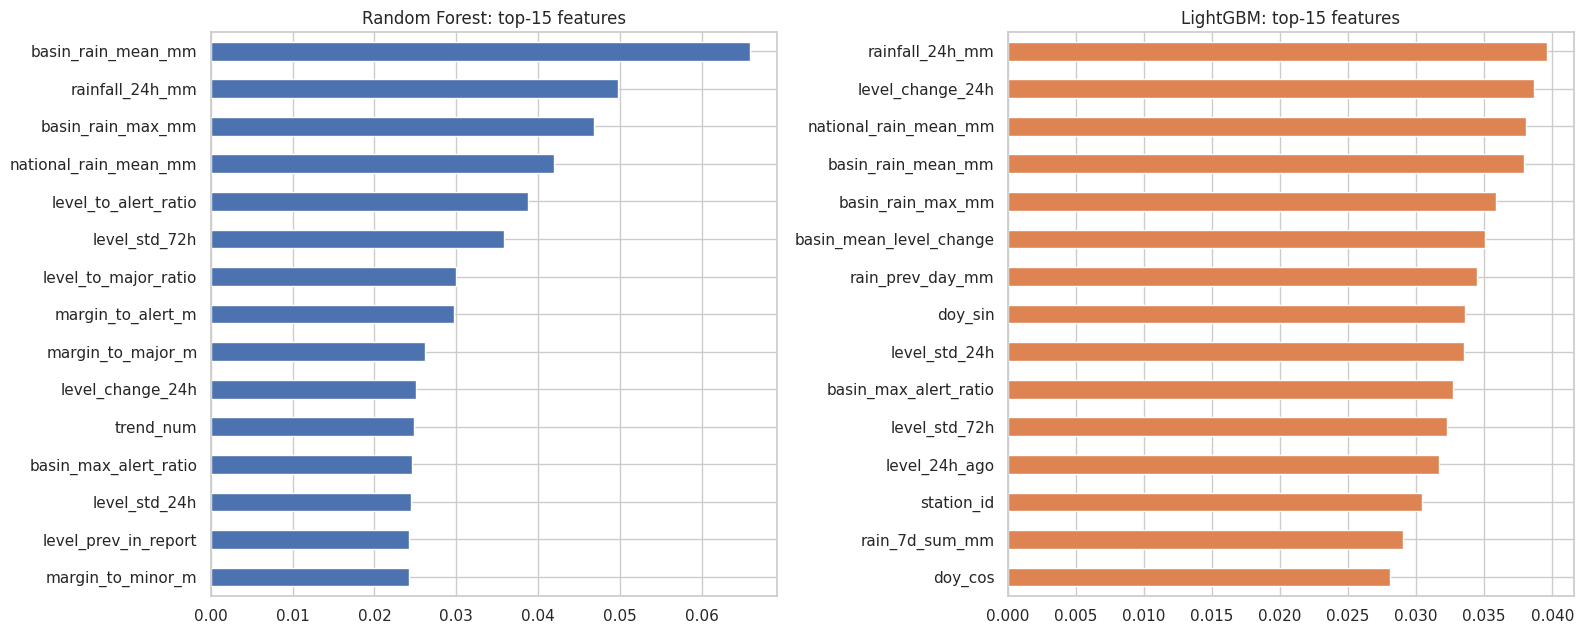

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(16, 6.5))
for a, name in zip(ax, ['Random Forest', 'LightGBM']):
    mdl = REG_RESULTS[name]['model']; cols = Xr_of(REG_RESULTS[name]['data'], 'train').columns
    imp = pd.Series(mdl.feature_importances_, index=cols)
    imp = (imp / imp.sum()).sort_values().tail(15)
    imp.plot.barh(ax=a, color=REG_FAM_COLORS[REG_RESULTS[name]['family']]); a.set_title(f'{name}: top-15 features')
plt.tight_layout(); plt.show()

###Save models and predictions (used by the dashboard)

In [ ]:
for name, r in REG_RESULTS.items():
    if r['model'] is not None:
        fn = name.replace(' ', '_').replace('(', '').replace(')', '').replace('+', 'plus').replace('/', '_')
        joblib.dump(r['model'], f'{REG_MODEL_DIR}/{fn}.joblib')

pred = ids_reg['test'][['obs_datetime', 'station', 'basin']].copy()
pred['level_now'] = level_now['test']; pred['alert_level'] = alert['test']; pred['y_true'] = yt
for name, r in REG_RESULTS.items():
    pred[f'pred__{name}'] = r['pred_test']
pred.to_parquet(f'{PROC}/reg_test_predictions.parquet')
reg_val_tbl.to_csv(f'{PROC}/reg_results_val.csv', index=False)
reg_test_tbl.to_csv(f'{PROC}/reg_results_test.csv', index=False)
reg_ci_tbl.to_csv(f'{PROC}/reg_results_test_ci.csv', index=False)
band_tbl.to_csv(f'{PROC}/reg_results_by_band.csv')
json.dump({n: {'family': r['family'], 'data': r['data'], 'params': {k: str(v) for k, v in r['params'].items()}}
           for n, r in REG_RESULTS.items()}, open(f'{PROC}/reg_model_registry.json', 'w'), indent=2)
print('Saved models to', REG_MODEL_DIR); print('Saved predictions and tables to', PROC)

Saved models to /content/drive/MyDrive/MachineLearningCA01/processed/models_reg
Saved predictions and tables to /content/drive/MyDrive/MachineLearningCA01/processed


###Summary

In [ ]:
cols = ['Model', 'Family', 'RMSE', 'MAE', 'R2', 'Skill', 'MAE_high', 'Warn_F1', 'Warn_Recall']
print('=' * 110); print('VALIDATION (model selection)'); print('=' * 110)
print(reg_val_tbl[cols].round(4).to_string(index=False))
print('\n' + '=' * 110); print('TEST (final, untouched)'); print('=' * 110)
print(reg_test_tbl[cols].round(4).to_string(index=False))
print('\nBootstrap 95% CI (test)'); print(reg_ci_tbl.round(4).to_string(index=False))
print('\nTest MAE by water-level band'); print(band_tbl.round(3).to_string())
print('\nStacking weights:', reg_stack_w.round(3).to_dict())
print('H2 weights:', dict(zip(['rf', 'ann'], np.round(h2.final_estimator_.coef_, 3))), '| H3 w_RF:', w_best)
print('Best per family (validation):', reg_best_by_family); print('Best overall (validation):', reg_best_name)
print('Tuned params:')
for n, r in REG_RESULTS.items():
    if r['params']: print(f'  {n:26s} {r["params"]}')

VALIDATION (model selection)
                Model   Family   RMSE    MAE     R2  Skill  MAE_high  Warn_F1  Warn_Recall
      H3 RF+ANN blend   Hybrid 0.5243 0.3218 0.9538 0.1953    0.6076   0.7574       0.6413
   Averaging (Voting) Stacking 0.5336 0.3203 0.9522 0.1811    0.6358   0.7493       0.6390
   H2 RF+ANN stacking   Hybrid 0.5367 0.3319 0.9516 0.1763    0.6346   0.7407       0.6176
             CatBoost Boosting 0.5377 0.3285 0.9514 0.1748    0.6528   0.7448       0.6413
 HistGradientBoosting Boosting 0.5399 0.3299 0.9510 0.1714    0.6515   0.7455       0.6366
Stacking (non-neg LR) Stacking 0.5415 0.3279 0.9507 0.1690    0.6506   0.7437       0.6271
             LightGBM Boosting 0.5429 0.3285 0.9505 0.1668    0.6594   0.7497       0.6437
          Extra Trees  Bagging 0.5430 0.3314 0.9505 0.1667    0.6368   0.7528       0.6437
              XGBoost Boosting 0.5431 0.3289 0.9504 0.1666    0.6565   0.7444       0.6295
        Random Forest  Bagging 0.5452 0.3300 0.9500 0.1632   

##Time-Series Hybrid: RF + ARIMA

In [ ]:
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.stattools import adfuller, acovf, levinson_durbin
from statsmodels.stats.diagnostic import acorr_ljungbox

needed = ['PROC', 'cut_val', 'cut_test', 'RANDOM_STATE', 'N_JOBS', 'SimpleImputer', 'RandomForestRegressor',
          'mean_absolute_error', 'mean_squared_error']
missing = [n for n in needed if n not in globals()]
assert not missing, f'Run Parts 1-3 first in this session - missing: {missing}'

TS_FOCUS = ['Hanwella', 'Kalawellawa (Millakanda)']
TS_STEP_H, TS_H = 3, 8
print('Validation starts:', cut_val, '| Test starts:', cut_test)

Validation starts: 2026-09-22 21:00:00 | Test starts: 2026-10-27 18:00:00


###Build 3-hourly series for every station

39 stations | grid: 4,242 steps of 3 h (2025-06-10 -> 2026-11-22)


,observed_steps,coverage_%
Hanwella,998.0,23.5
Kalawellawa (Millakanda),993.0,23.4


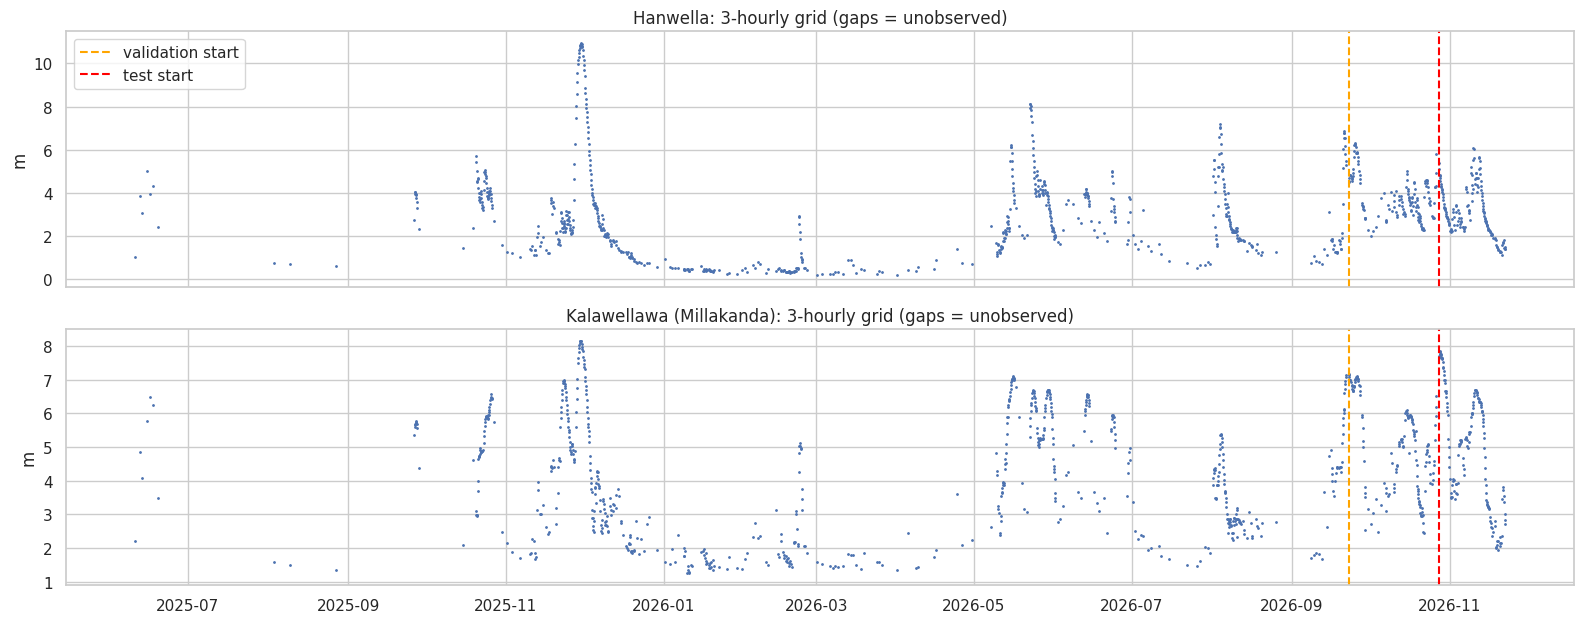

In [ ]:
ts_clean = pd.read_parquet(f'{PROC}/clean_full.parquet')
ts_clean['obs_datetime'] = pd.to_datetime(ts_clean['obs_datetime'])
ts_t0, ts_t1 = ts_clean.obs_datetime.min().floor('3h'), ts_clean.obs_datetime.max()
ts_grid = pd.date_range(ts_t0, ts_t1, freq=f'{TS_STEP_H}h')

ts_series = {}
for st, g in ts_clean.groupby('station', observed=True):
    s = g.drop_duplicates('obs_datetime').set_index('obs_datetime')['water_level']
    ts_series[st] = s.reindex(ts_grid)

ts_cov = pd.DataFrame({st: {'observed_steps': int(s.notna().sum()), 'coverage_%': 100 * s.notna().mean()}
                       for st, s in ts_series.items()}).T
print(f'{len(ts_series)} stations | grid: {len(ts_grid):,} steps of 3 h ({ts_t0:%Y-%m-%d} -> {ts_t1:%Y-%m-%d})')
display(ts_cov.loc[TS_FOCUS].round(1))

fig, ax = plt.subplots(len(TS_FOCUS), 1, figsize=(16, 3.2 * len(TS_FOCUS)), sharex=True)
for a, st in zip(ax, TS_FOCUS):
    s = ts_series[st]
    a.plot(s.index, s.values, '.', ms=2)
    a.axvline(cut_val, c='orange', ls='--', label='validation start'); a.axvline(cut_test, c='red', ls='--', label='test start')
    a.set_title(f'{st}: 3-hourly grid (gaps = unobserved)'); a.set_ylabel('m')
ax[0].legend(loc='upper left'); plt.tight_layout(); plt.show()

###Stationarity (Augmented Dickey-Fuller test)

In [ ]:
rows = []
for st in TS_FOCUS:
    tr = ts_series[st][ts_series[st].index < cut_val]
    x = tr.interpolate(method='time', limit_area='inside').dropna()
    for name, z in [('level', x), ('1st difference', x.diff().dropna())]:
        stat, p, *_ = adfuller(z, autolag='AIC')
        rows.append({'station': st, 'series': name, 'n': len(z), 'observed share': tr.notna().mean(),
                     'ADF stat': stat, 'p-value': p, 'stationary (p<0.05)': p < 0.05})
display(pd.DataFrame(rows).round(4))
print('-> Rivers are mean-reverting (they fall back to base flow), so ADF can reject a unit root for the level itself.')
print('   Both d = 0 (with a constant) and d = 1 are therefore plausible; Step 6 lets validation forecasts decide per station.')

,station,series,n,observed share,ADF stat,p-value,stationary (p<0.05)
0,Hanwella,level,3749,0.1864,-4.9190,0.0000,True
1,Hanwella,1st difference,3748,0.1864,-15.7939,0.0000,True
2,Kalawellawa (Millakanda),level,3749,0.1853,-3.5493,0.0068,True
3,Kalawellawa (Millakanda),1st difference,3748,0.1853,-13.5775,0.0000,True


-> Rivers are mean-reverting (they fall back to base flow), so ADF can reject a unit root for the level itself.
   Both d = 0 (with a constant) and d = 1 are therefore plausible; Step 6 lets validation forecasts decide per station.


###ACF / PACF of the 3-hour differences (guides the AR order p and MA order q)

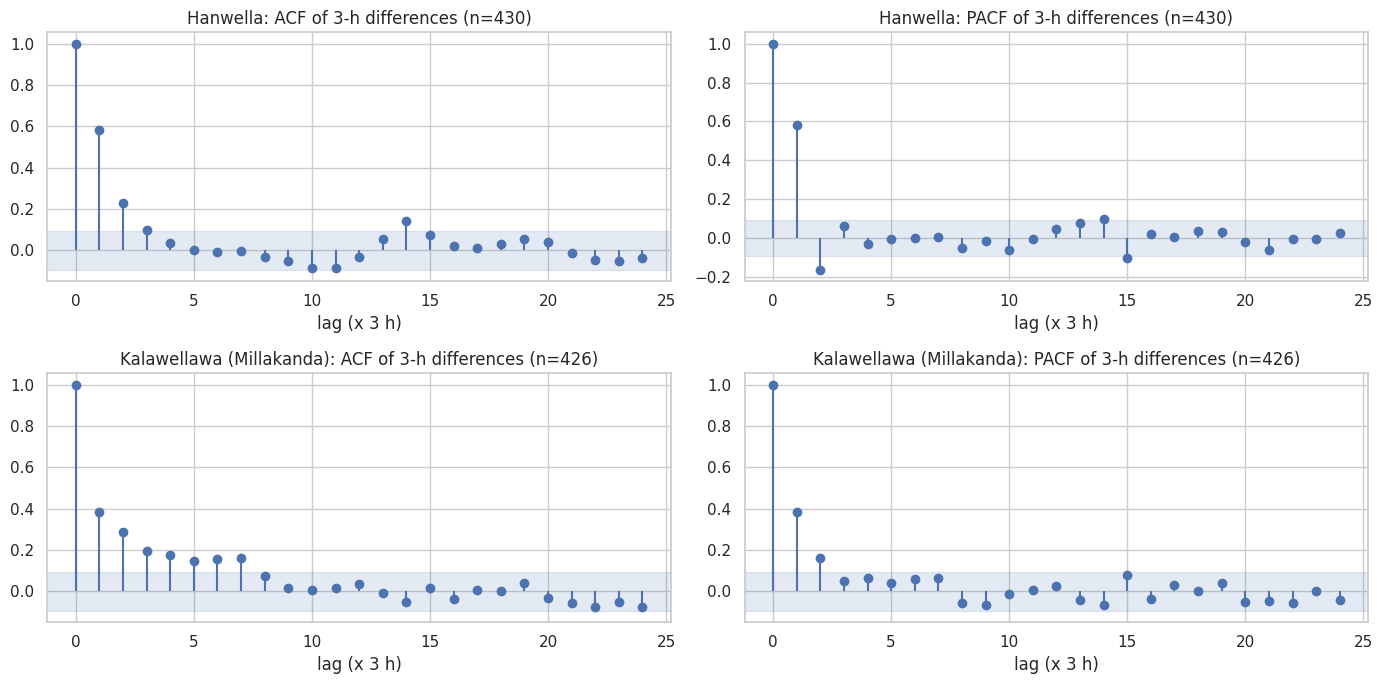

In [ ]:
TS_LAGS = 24
fig, ax = plt.subplots(len(TS_FOCUS), 2, figsize=(14, 3.5 * len(TS_FOCUS)))
for i, st in enumerate(TS_FOCUS):
    d3 = ts_series[st][ts_series[st].index < cut_val].diff()
    acov = acovf(d3.values, missing='conservative', nlag=TS_LAGS, fft=False)
    acf_v = acov / acov[0]
    pacf_v = levinson_durbin(acov, nlags=TS_LAGS, isacov=True)[2]
    band = 1.96 / np.sqrt(d3.notna().sum())
    for a, vals, name in [(ax[i, 0], acf_v, 'ACF'), (ax[i, 1], pacf_v, 'PACF')]:
        a.stem(range(len(vals)), vals, basefmt=' ')
        a.axhspan(-band, band, color='#4C72B0', alpha=0.15)
        a.set_title(f'{st}: {name} of 3-h differences (n={int(d3.notna().sum())})'); a.set_xlabel('lag (x 3 h)')
plt.tight_layout(); plt.show()

###ARIMA candidates for every station (AIC, training period only)

In [ ]:
ts_cands, ts_rows = {}, []
t0 = time.time()
for st, s in ts_series.items():
    tr = s[s.index < cut_val]
    ts_cands[st] = {}
    for d, trend in [(1, 'n'), (0, 'c')]:
        best = None
        for p in [1, 2, 3]:
            for q in [0, 1, 2]:
                try:
                    with warnings.catch_warnings():
                        warnings.simplefilter('ignore')
                        r = SARIMAX(tr, order=(p, d, q), trend=trend).fit(disp=False, maxiter=200)
                    if best is None or r.aic < best[0]:
                        best = (r.aic, (p, d, q), r)
                except Exception:
                    pass
        ts_cands[st][d] = {'order': best[1], 'trend': trend, 'fit': best[2], 'aic': best[0]}
print(f'Fitted 2 x 9 ARIMA models for {len(ts_cands)} stations in {time.time() - t0:.0f}s')

Fitted 2 x 9 ARIMA models for 39 stations in 1682s


###Rolling 24-h-ahead forecasts, with d chosen per station on validation

In [ ]:
t0 = time.time()
ts_all = []
for st, s in ts_series.items():
    v = s.values
    origins = np.where(~np.isnan(v[:-TS_H]) & ~np.isnan(v[TS_H:]))[0]
    for d, cand in ts_cands[st].items():
        res_full = SARIMAX(s, order=cand['order'], trend=cand['trend']).filter(cand['fit'].params)
        for i in origins:
            f = res_full.get_prediction(start=i + 1, end=i + TS_H, dynamic=0).predicted_mean.iloc[-1]
            ts_all.append((st, d, s.index[i], v[i], f, v[i + TS_H]))
ts_all = pd.DataFrame(ts_all, columns=['station', 'd', 'obs_datetime', 'level_now', 'arima_pred', 'actual_24h'])
ts_all['target_time'] = ts_all['obs_datetime'] + pd.Timedelta(hours=TS_STEP_H * TS_H)

ts_in_val = (ts_all.obs_datetime >= cut_val) & (ts_all.target_time < cut_test)
ts_val_rmse = (ts_all[ts_in_val].assign(se=lambda x: (x.arima_pred - x.actual_24h) ** 2)
            .groupby(['station', 'd']).se.mean().pow(0.5).unstack())
ts_choice = ts_val_rmse.idxmin(axis=1).to_dict()
ts_orders = {st: ts_cands[st][d]['order'] for st, d in ts_choice.items()}
ts_fits = {st: ts_cands[st][d]['fit'] for st, d in ts_choice.items()}
ts_fc = ts_all[ts_all.apply(lambda r: ts_choice[r.station] == r.d, axis=1)].drop(columns='d').reset_index(drop=True)

ts_order_tbl = pd.DataFrame([{'station': st, 'chosen_d': ts_choice[st], 'order': ts_orders[st],
                              'val_RMSE_d0': ts_val_rmse.loc[st, 0], 'val_RMSE_d1': ts_val_rmse.loc[st, 1],
                              'trend': ts_cands[st][ts_choice[st]]['trend']} for st in ts_choice])
print(f'{len(ts_all):,} candidate forecasts in {time.time() - t0:.0f}s')
print('Chosen d per station:', pd.Series(ts_choice).value_counts().to_dict())
print(ts_order_tbl['order'].astype(str).value_counts().to_string())
display(ts_order_tbl[ts_order_tbl.station.isin(TS_FOCUS)].round(4))
for st in TS_FOCUS:
    print(f'\n{st}  ARIMA{ts_orders[st]}'); print(ts_fits[st].summary().tables[1])

54,930 candidate forecasts in 117s
Chosen d per station: {1: 25, 0: 14}
order
(2, 1, 2)    10
(3, 1, 1)     7
(3, 0, 1)     7
(3, 1, 2)     3
(2, 1, 1)     3
(1, 0, 2)     2
(3, 0, 2)     2
(1, 1, 1)     1
(1, 1, 2)     1
(2, 0, 2)     1
(2, 0, 0)     1
(2, 0, 1)     1


,station,chosen_d,order,val_RMSE_d0,val_RMSE_d1,trend
8,Hanwella,1,"(2, 1, 2)",0.9210,0.8956,n
11,Kalawellawa (Millakanda),1,"(3, 1, 2)",0.8541,0.8413,n



Hanwella  ARIMA(2, 1, 2)
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          1.4015      0.027     51.638      0.000       1.348       1.455
ar.L2         -0.4281      0.029    -14.986      0.000      -0.484      -0.372
ma.L1         -0.4524      0.045     -9.991      0.000      -0.541      -0.364
ma.L2         -0.5376      0.045    -11.991      0.000      -0.625      -0.450
sigma2         0.0279      0.001     40.775      0.000       0.027       0.029

Kalawellawa (Millakanda)  ARIMA(3, 1, 2)
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.8844      0.208      4.251      0.000       0.477       1.292
ar.L2          0.4942      0.302      1.639      0.101      -0.097       1.085
ar.L3         -0.4027      0.099     -4.055      0.000      -0.

###Residual diagnostics of the chosen models (Ljung-Box)

Hanwella: Ljung-Box p-values (lags 8, 16) = [0.0517, 0.0445]
Kalawellawa (Millakanda): Ljung-Box p-values (lags 8, 16) = [0.6166, 0.1748]


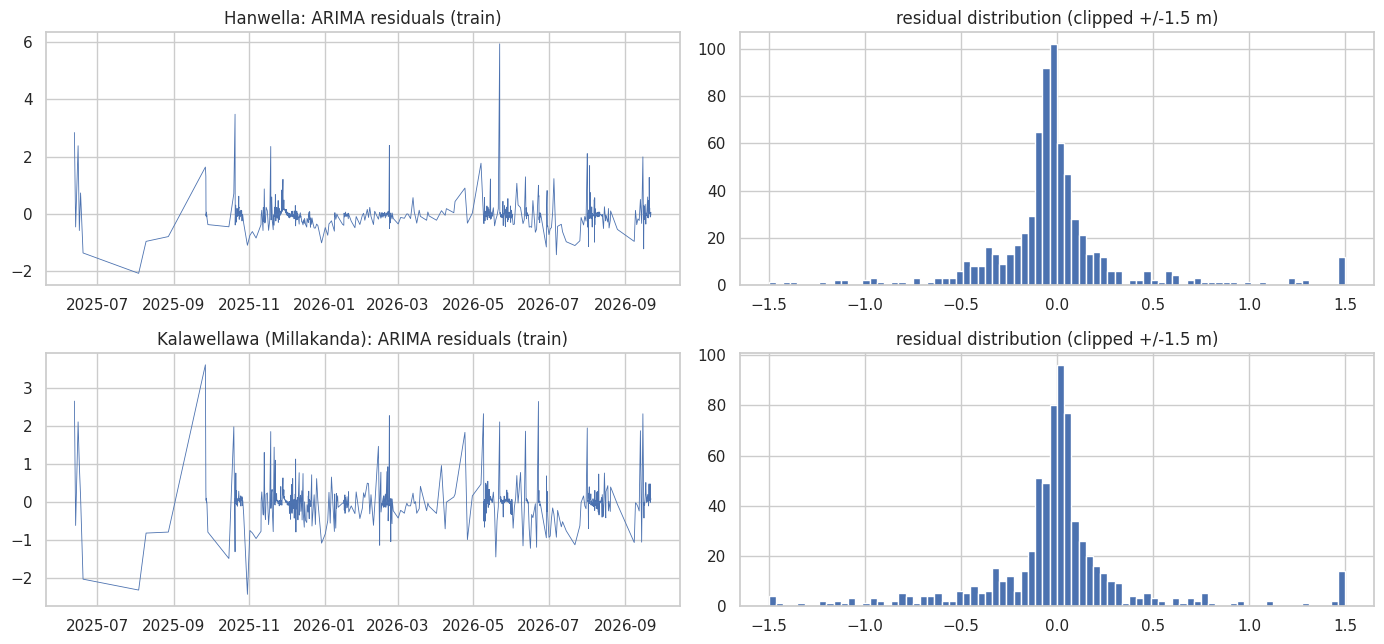

Heavy tails and spikes = sudden rises after heavy rain: the part a linear model cannot forecast.


In [ ]:
fig, ax = plt.subplots(len(TS_FOCUS), 2, figsize=(14, 3.3 * len(TS_FOCUS)))
for i, st in enumerate(TS_FOCUS):
    res = ts_fits[st].resid.dropna().iloc[1:]
    lb = acorr_ljungbox(res, lags=[8, 16], return_df=True)
    print(f'{st}: Ljung-Box p-values (lags 8, 16) = {lb["lb_pvalue"].round(4).tolist()}')
    ax[i, 0].plot(res.index, res.values, lw=0.6); ax[i, 0].set_title(f'{st}: ARIMA residuals (train)')
    ax[i, 1].hist(res.clip(-1.5, 1.5), bins=80); ax[i, 1].set_title('residual distribution (clipped +/-1.5 m)')
plt.tight_layout(); plt.show()
print('Heavy tails and spikes = sudden rises after heavy rain: the part a linear model cannot forecast.')

###Build the hybrid dataset

In [ ]:
ts_meta = json.load(open(f'{PROC}/meta.json'))
TS_FEATURES = ts_meta['features']
ts_df = ts_fc.merge(ts_clean[['station', 'obs_datetime', 'alert_level'] + [c for c in TS_FEATURES if c != 'alert_level']],
                    on=['station', 'obs_datetime'], how='inner')
ts_df['split'] = np.select(
    [(ts_df.target_time < cut_val),
     (ts_df.obs_datetime >= cut_val) & (ts_df.target_time < cut_test),
     (ts_df.obs_datetime >= cut_test)], ['train', 'val', 'test'], default='purged')
ts_df = ts_df[ts_df.split != 'purged'].reset_index(drop=True)


ts_df['arima_change'] = ts_df['arima_pred'] - ts_df['level_now']
TS_X_COLS = TS_FEATURES + ['arima_pred', 'arima_change']

TS = {sp: ts_df[ts_df.split == sp].reset_index(drop=True) for sp in ['train', 'val', 'test']}
ts_imputer = SimpleImputer(strategy='median').fit(TS['train'][TS_X_COLS])
TS_X = {sp: pd.DataFrame(ts_imputer.transform(TS[sp][TS_X_COLS]), columns=TS_X_COLS) for sp in TS}
for sp in TS:
    print(f'{sp:5s} origins={len(TS[sp]):6,}  stations={TS[sp].station.nunique()}')

train origins=18,147  stations=39
val   origins= 4,308  stations=39
test  origins= 4,935  stations=39


###Models

In [ ]:
TS_RESULTS = {}
ts_rmse = lambda a, b: float(np.sqrt(mean_squared_error(a, b)))

def ts_store(name, pv, pt, params=None, model=None):
    TS_RESULTS[name] = dict(pred_val=np.asarray(pv), pred_test=np.asarray(pt), params=params or {}, model=model)
    print(f'{name:20s} VAL RMSE={ts_rmse(TS["val"].actual_24h, pv):.4f}  TEST RMSE={ts_rmse(TS["test"].actual_24h, pt):.4f}')

ts_store('Persistence', TS['val'].level_now, TS['test'].level_now)
ts_store('ARIMA', TS['val'].arima_pred, TS['test'].arima_pred)

def ts_tune_rf(name, X_cols, base_col):

    ytr = TS['train'].actual_24h - TS['train'][base_col]
    best = None
    for params in [{'max_features': 0.3, 'min_samples_leaf': 5}, {'max_features': 'sqrt', 'min_samples_leaf': 5},
                   {'max_features': 0.3, 'min_samples_leaf': 20}]:
        m = RandomForestRegressor(n_estimators=300, n_jobs=N_JOBS, random_state=RANDOM_STATE, **params)
        m.fit(TS_X['train'][X_cols], ytr)
        pv = TS['val'][base_col].values + m.predict(TS_X['val'][X_cols])
        r = ts_rmse(TS['val'].actual_24h, pv); print(f'   {params}  val RMSE={r:.4f}')
        if best is None or r < best[0]:
            best = (r, m, params)
    m = best[1]
    ts_store(name, TS['val'][base_col].values + m.predict(TS_X['val'][X_cols]),
             TS['test'][base_col].values + m.predict(TS_X['test'][X_cols]), best[2], m)

print('\nRF (direct) grid:')
ts_tune_rf('RF (direct)', TS_FEATURES, 'level_now')
print('\nRF + ARIMA hybrid grid:')
ts_tune_rf('RF + ARIMA hybrid', TS_X_COLS, 'arima_pred')

Persistence          VAL RMSE=0.6231  TEST RMSE=0.6026
ARIMA                VAL RMSE=0.5955  TEST RMSE=0.5550

RF (direct) grid:
   {'max_features': 0.3, 'min_samples_leaf': 5}  val RMSE=0.5145
   {'max_features': 'sqrt', 'min_samples_leaf': 5}  val RMSE=0.5135
   {'max_features': 0.3, 'min_samples_leaf': 20}  val RMSE=0.5173
RF (direct)          VAL RMSE=0.5135  TEST RMSE=0.5038

RF + ARIMA hybrid grid:
   {'max_features': 0.3, 'min_samples_leaf': 5}  val RMSE=0.5029
   {'max_features': 'sqrt', 'min_samples_leaf': 5}  val RMSE=0.5005
   {'max_features': 0.3, 'min_samples_leaf': 20}  val RMSE=0.4990
RF + ARIMA hybrid    VAL RMSE=0.4990  TEST RMSE=0.5063


###Evaluation

In [ ]:
def ts_metrics(df_part, pred):
    y_, now, al = df_part.actual_24h.values, df_part.level_now.values, df_part.alert_level.values
    high = y_ >= 0.8 * al
    return {'RMSE': ts_rmse(y_, pred), 'MAE': mean_absolute_error(y_, pred),
            'Skill': 1 - ts_rmse(y_, pred) / ts_rmse(y_, now),
            'MAE_high': mean_absolute_error(y_[high], pred[high]) if high.any() else np.nan, 'n': len(y_)}

def ts_table(split, station=None):
    part = TS[split] if station is None else TS[split][TS[split].station == station]
    mask = np.ones(len(TS[split]), bool) if station is None else (TS[split].station == station).values
    return pd.DataFrame([{'Model': n, **ts_metrics(part, r[f'pred_{split}'][mask])} for n, r in TS_RESULTS.items()])

ts_val_tbl, ts_test_tbl = ts_table('val'), ts_table('test')
print('ALL STATIONS - validation'); display(ts_val_tbl.round(4))
print('ALL STATIONS - test'); display(ts_test_tbl.round(4))
ts_focus_tbls = {}
for st in TS_FOCUS:
    ts_focus_tbls[st] = ts_table('test', st)
    print(f'{st} - test'); display(ts_focus_tbls[st].round(4))

ALL STATIONS - validation


,Model,RMSE,MAE,Skill,MAE_high,n
0,Persistence,0.6231,0.3705,0.0000,0.7472,4308
1,ARIMA,0.5955,0.3527,0.0443,0.7954,4308
2,RF (direct),0.5135,0.3128,0.1759,0.5933,4308
3,RF + ARIMA hybrid,0.4990,0.3086,0.1991,0.5536,4308


ALL STATIONS - test


,Model,RMSE,MAE,Skill,MAE_high,n
0,Persistence,0.6026,0.3850,0.0000,0.6309,4935
1,ARIMA,0.5550,0.3695,0.0790,0.6145,4935
2,RF (direct),0.5038,0.3133,0.1640,0.5493,4935
3,RF + ARIMA hybrid,0.5063,0.3253,0.1599,0.4832,4935


Hanwella - test


,Model,RMSE,MAE,Skill,MAE_high,n
0,Persistence,0.7977,0.6505,0.0000,0.9683,131
1,ARIMA,0.7718,0.6314,0.0325,1.3587,131
2,RF (direct),0.5377,0.3712,0.3259,0.7917,131
3,RF + ARIMA hybrid,0.6612,0.5020,0.1711,0.9512,131


Kalawellawa (Millakanda) - test


,Model,RMSE,MAE,Skill,MAE_high,n
0,Persistence,0.8582,0.6876,0.0000,0.6478,131
1,ARIMA,0.7464,0.5919,0.1303,0.4934,131
2,RF (direct),0.5178,0.3939,0.3966,0.3834,131
3,RF + ARIMA hybrid,0.5263,0.3969,0.3868,0.3687,131


In [ ]:
rng_ts = np.random.default_rng(RANDOM_STATE)
yt_ts = TS['test'].actual_24h.values
idx_ts = rng_ts.integers(0, len(yt_ts), size=(1000, len(yt_ts)))
ts_ci = []
for n, r in TS_RESULTS.items():
    e = r['pred_test'] - yt_ts
    b = np.sqrt((e[idx_ts] ** 2).mean(axis=1))
    ts_ci.append({'Model': n, 'RMSE': np.sqrt((e ** 2).mean()),
                  'RMSE_95CI': f'[{np.percentile(b, 2.5):.3f}, {np.percentile(b, 97.5):.3f}]'})
ts_ci_tbl = pd.DataFrame(ts_ci); display(ts_ci_tbl.round(4))

ts_per_station = []
for st, g in TS['test'].groupby('station'):
    m = (TS['test'].station == st).values
    ts_per_station.append({'station': st, 'n': int(m.sum()),
                           **{n: ts_rmse(g.actual_24h, r['pred_test'][m]) for n, r in TS_RESULTS.items()}})
ts_per_station = pd.DataFrame(ts_per_station)
wins = (ts_per_station['RF + ARIMA hybrid'] < ts_per_station['ARIMA']).mean()
wins_rf = (ts_per_station['RF + ARIMA hybrid'] < ts_per_station['RF (direct)']).mean()
print(f'Hybrid beats ARIMA alone at {wins:.0%} of stations, and RF (direct) at {wins_rf:.0%} of stations (test RMSE)')

,Model,RMSE,RMSE_95CI
0,Persistence,0.6026,"[0.583, 0.621]"
1,ARIMA,0.5550,"[0.535, 0.574]"
2,RF (direct),0.5038,"[0.485, 0.524]"
3,RF + ARIMA hybrid,0.5063,"[0.488, 0.526]"


Hybrid beats ARIMA alone at 67% of stations, and RF (direct) at 51% of stations (test RMSE)


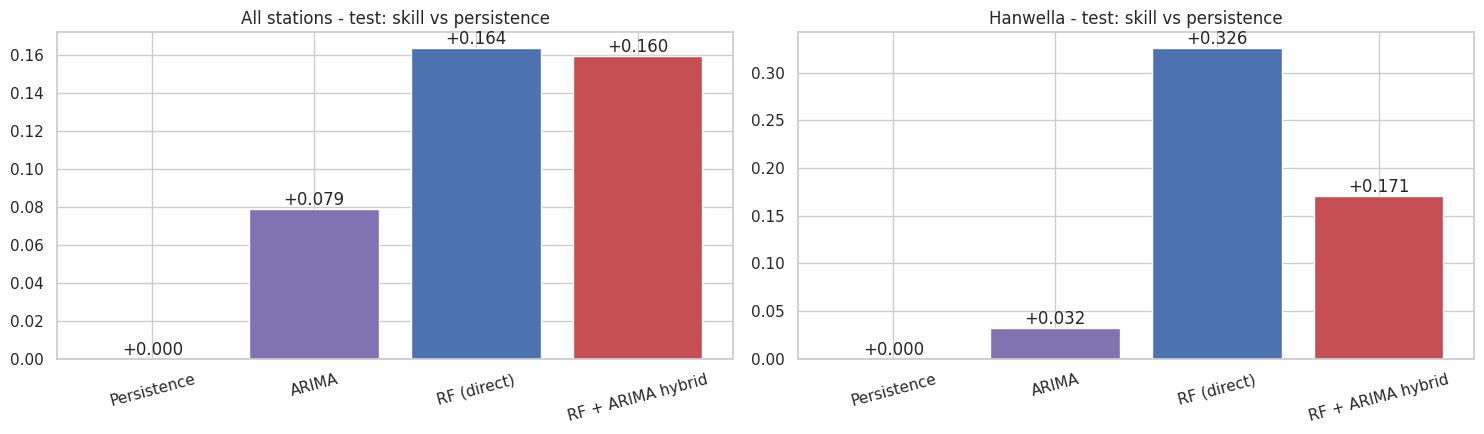

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
TS_COLORS = {'Persistence': '#9E9E9E', 'ARIMA': '#8172B2', 'RF (direct)': '#4C72B0', 'RF + ARIMA hybrid': '#C44E52'}
for a, (title, t) in zip(ax, [('All stations - test', ts_test_tbl)] +
                         [(f'{TS_FOCUS[0]} - test', ts_focus_tbls[TS_FOCUS[0]])]):
    a.bar(t['Model'], t['Skill'], color=[TS_COLORS[m] for m in t['Model']])
    a.axhline(0, c='k', lw=0.8); a.set_title(f'{title}: skill vs persistence'); a.tick_params(axis='x', rotation=15)
    for i, v in enumerate(t['Skill']): a.text(i, v, f'{v:+.3f}', ha='center', va='bottom' if v >= 0 else 'top')
plt.tight_layout(); plt.show()

###Forecast plots on the test period (focus stations)

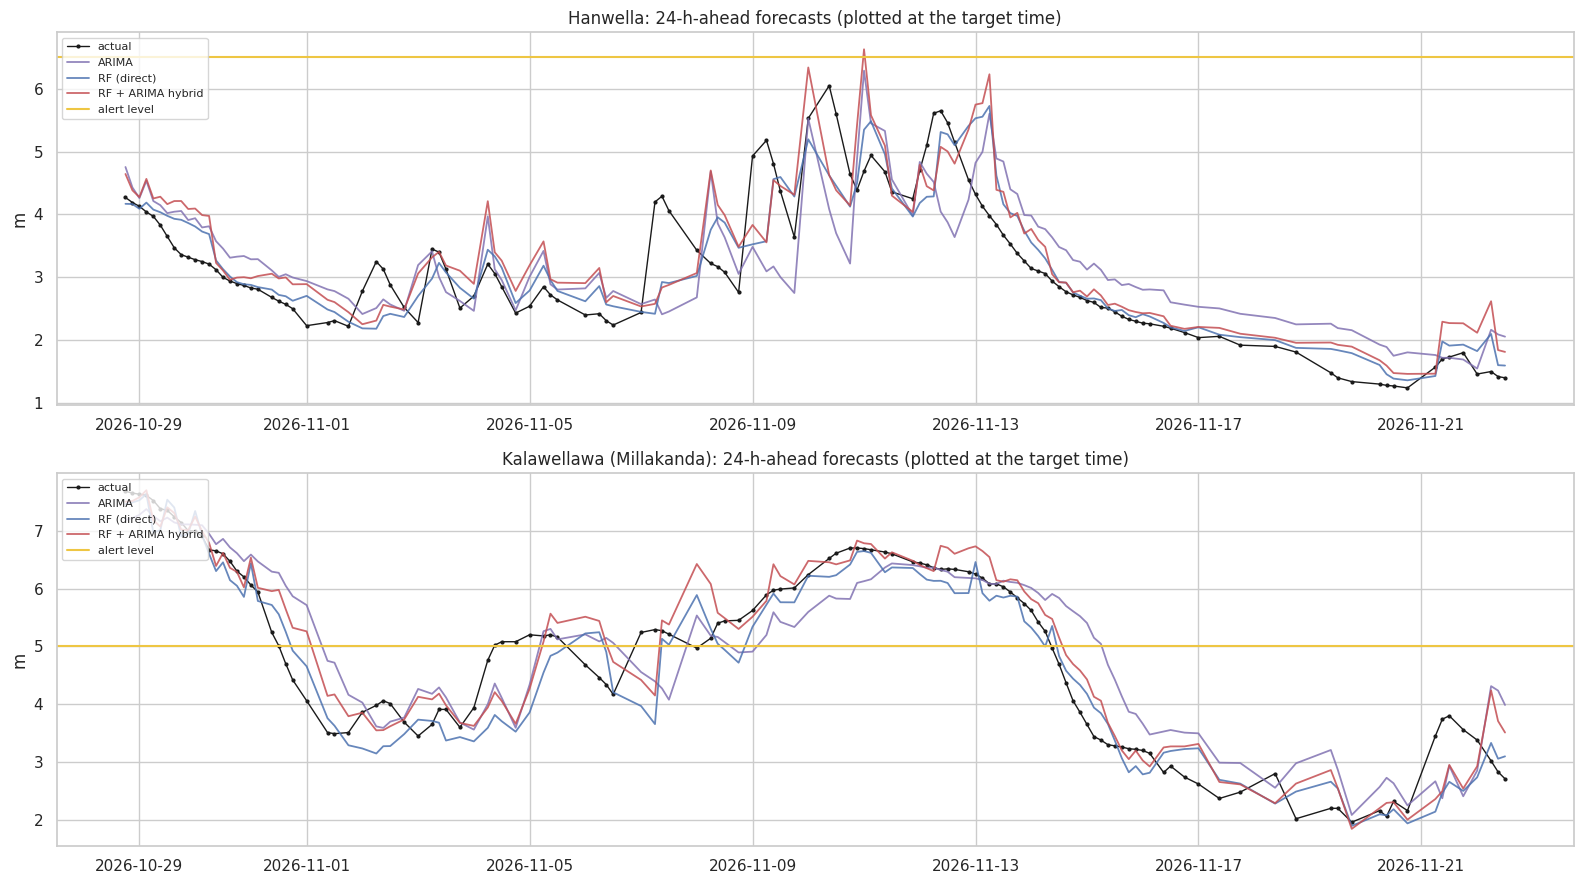

In [ ]:
fig, ax = plt.subplots(len(TS_FOCUS), 1, figsize=(16, 4.5 * len(TS_FOCUS)))
for a, st in zip(ax, TS_FOCUS):
    m = (TS['test'].station == st).values
    t = TS['test'].loc[m, 'target_time']
    a.plot(t, TS['test'].loc[m, 'actual_24h'], 'k.-', ms=4, lw=1, label='actual')
    for n in ['ARIMA', 'RF (direct)', 'RF + ARIMA hybrid']:
        a.plot(t, TS_RESULTS[n]['pred_test'][m], lw=1.3, alpha=0.85, color=TS_COLORS[n], label=n)
    a.axhline(TS['test'].loc[m, 'alert_level'].iloc[0], color='#EEC643', lw=1.5, label='alert level')
    a.set_title(f'{st}: 24-h-ahead forecasts (plotted at the target time)'); a.set_ylabel('m')
    a.legend(loc='upper left', fontsize=8)
plt.tight_layout(); plt.show()

###What does the Random Forest correct?

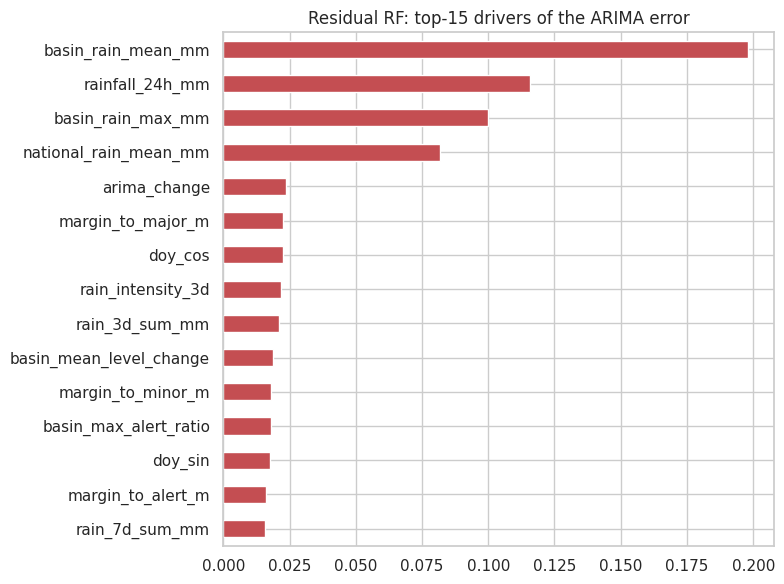

basin_rain_mean_mm         0.1980
rainfall_24h_mm            0.1158
basin_rain_max_mm          0.0998
national_rain_mean_mm      0.0819
arima_change               0.0238
margin_to_major_m          0.0226
doy_cos                    0.0224
rain_intensity_3d          0.0218
rain_3d_sum_mm             0.0211
basin_mean_level_change    0.0187
margin_to_minor_m          0.0181
basin_max_alert_ratio      0.0178
doy_sin                    0.0175
margin_to_alert_m          0.0159
rain_7d_sum_mm             0.0158

Correlation between the ARIMA error and the RF correction (test): 0.459


In [ ]:
ts_imp = pd.Series(TS_RESULTS['RF + ARIMA hybrid']['model'].feature_importances_, index=TS_X_COLS)
ts_imp = (ts_imp / ts_imp.sum()).sort_values(ascending=False)
plt.figure(figsize=(8, 6)); ts_imp.head(15).sort_values().plot.barh(color='#C44E52')
plt.title('Residual RF: top-15 drivers of the ARIMA error'); plt.tight_layout(); plt.show()
print(ts_imp.head(15).round(4).to_string())

ts_e_arima = TS['test'].actual_24h - TS['test'].arima_pred
ts_corr = TS_RESULTS['RF + ARIMA hybrid']['pred_test'] - TS['test'].arima_pred
print(f'\nCorrelation between the ARIMA error and the RF correction (test): {np.corrcoef(ts_e_arima, ts_corr)[0, 1]:.3f}')

###Save results (used by the dashboard)

In [ ]:
ts_out = TS['test'][['station', 'obs_datetime', 'target_time', 'level_now', 'alert_level', 'actual_24h']].copy()
for n, r in TS_RESULTS.items():
    ts_out[f'pred__{n}'] = r['pred_test']
ts_out.to_parquet(f'{PROC}/ts_test_predictions.parquet')
ts_test_tbl.to_csv(f'{PROC}/ts_results_test.csv', index=False)
ts_val_tbl.to_csv(f'{PROC}/ts_results_val.csv', index=False)
ts_ci_tbl.to_csv(f'{PROC}/ts_results_test_ci.csv', index=False)
ts_per_station.to_csv(f'{PROC}/ts_results_per_station.csv', index=False)
ts_order_tbl.to_csv(f'{PROC}/ts_arima_orders.csv', index=False)
os.makedirs(f'{PROC}/models_ts', exist_ok=True)
joblib.dump({'rf_hybrid': TS_RESULTS['RF + ARIMA hybrid']['model'], 'rf_direct': TS_RESULTS['RF (direct)']['model'],
             'imputer': ts_imputer, 'x_cols': TS_X_COLS, 'arima_orders': ts_orders,
             'arima_params': {st: f.params for st, f in ts_fits.items()},
             'arima_trend': {st: ts_cands[st][d]['trend'] for st, d in ts_choice.items()}}, f'{PROC}/models_ts/rf_arima_hybrid.joblib')
print('Saved to', PROC)

Saved to /content/drive/MyDrive/MachineLearningCA01/processed


###Summary

In [ ]:
print('=' * 90); print('PART 4 - RF + ARIMA HYBRID (24-h-ahead water level)'); print('=' * 90)
print('Chosen d per station (validation):', pd.Series(ts_choice).value_counts().to_dict())
print('ARIMA orders chosen:', ts_order_tbl['order'].astype(str).value_counts().to_dict())
for st in TS_FOCUS: print(f'  {st}: ARIMA{ts_orders[st]}')
print('Origins: ' + ', '.join(f'{sp}={len(TS[sp]):,}' for sp in TS))
print('\nALL STATIONS - validation'); print(ts_val_tbl.round(4).to_string(index=False))
print('\nALL STATIONS - test'); print(ts_test_tbl.round(4).to_string(index=False))
for st in TS_FOCUS:
    print(f'\n{st} - test'); print(ts_focus_tbls[st].round(4).to_string(index=False))
print('\nBootstrap 95% CI (test)'); print(ts_ci_tbl.round(4).to_string(index=False))
print(f'\nHybrid beats ARIMA at {wins:.0%} of stations; beats RF (direct) at {wins_rf:.0%} of stations')
print('Top-5 drivers of ARIMA error:', ts_imp.head(5).round(3).to_dict())
print('RF params:', {n: r['params'] for n, r in TS_RESULTS.items() if r['params']})

PART 4 - RF + ARIMA HYBRID (24-h-ahead water level)
Chosen d per station (validation): {1: 25, 0: 14}
ARIMA orders chosen: {'(2, 1, 2)': 10, '(3, 1, 1)': 7, '(3, 0, 1)': 7, '(3, 1, 2)': 3, '(2, 1, 1)': 3, '(1, 0, 2)': 2, '(3, 0, 2)': 2, '(1, 1, 1)': 1, '(1, 1, 2)': 1, '(2, 0, 2)': 1, '(2, 0, 0)': 1, '(2, 0, 1)': 1}
  Hanwella: ARIMA(2, 1, 2)
  Kalawellawa (Millakanda): ARIMA(3, 1, 2)
Origins: train=18,147, val=4,308, test=4,935

ALL STATIONS - validation
            Model   RMSE    MAE  Skill  MAE_high    n
      Persistence 0.6231 0.3705 0.0000    0.7472 4308
            ARIMA 0.5955 0.3527 0.0443    0.7954 4308
      RF (direct) 0.5135 0.3128 0.1759    0.5933 4308
RF + ARIMA hybrid 0.4990 0.3086 0.1991    0.5536 4308

ALL STATIONS - test
            Model   RMSE    MAE  Skill  MAE_high    n
      Persistence 0.6026 0.3850 0.0000    0.6309 4935
            ARIMA 0.5550 0.3695 0.0790    0.6145 4935
      RF (direct) 0.5038 0.3133 0.1640    0.5493 4935
RF + ARIMA hybrid 0.5063 0.3253 0.

##Trained Summary

In [ ]:
if 'PROC' not in globals():
    from google.colab import drive
    drive.mount('/content/drive')
    PROC = '/content/drive/MyDrive/MachineLearningCA01/processed'

SUM_OUT = os.path.join(PROC, 'summary'); os.makedirs(SUM_OUT, exist_ok=True)
sum_rd = lambda f: pd.read_csv(os.path.join(PROC, f))
SUM = {
    'clf_val': sum_rd('clf_results_val.csv'), 'clf_test': sum_rd('clf_results_test.csv'),
    'clf_ci': sum_rd('clf_results_test_ci.csv'), 'clf_onset': sum_rd('clf_results_new_alert.csv'),
    'reg_val': sum_rd('reg_results_val.csv'), 'reg_test': sum_rd('reg_results_test.csv'),
    'reg_ci': sum_rd('reg_results_test_ci.csv'), 'reg_band': sum_rd('reg_results_by_band.csv'),
    'ts_val': sum_rd('ts_results_val.csv'), 'ts_test': sum_rd('ts_results_test.csv'),
    'ts_ci': sum_rd('ts_results_test_ci.csv'), 'ts_station': sum_rd('ts_results_per_station.csv'),
    'ts_orders': sum_rd('ts_arima_orders.csv'),
}
sum_meta = json.load(open(os.path.join(PROC, 'meta.json')))
for k, v in SUM.items():
    print(f'{k:10s} {v.shape}')

clf_val    (13, 12)
clf_test   (13, 12)
clf_ci     (13, 5)
clf_onset  (13, 6)
reg_val    (17, 10)
reg_test   (17, 10)
reg_ci     (17, 5)
reg_band   (4, 7)
ts_val     (4, 6)
ts_test    (4, 6)
ts_ci      (4, 3)
ts_station (39, 6)
ts_orders  (39, 6)


In [ ]:
sum_clean = pd.read_parquet(os.path.join(PROC, 'clean_full.parquet'))
sum_clean['obs_datetime'] = pd.to_datetime(sum_clean['obs_datetime'])
sum_split = sum_clean.groupby('split', observed=True).agg(
    rows=('station', 'size'), start=('obs_datetime', 'min'), end=('obs_datetime', 'max'),
    alert_or_flood_24h=('target_alert_or_flood_24h', 'mean')).reindex(['train', 'val', 'test'])
sum_split['alert_or_flood_24h'] = (sum_split['alert_or_flood_24h'] * 100).round(2)
sum_split = sum_split.rename(columns={'alert_or_flood_24h': 'positive_rate_%'})

sum_dataset = pd.DataFrame({
    'Item': ['Source PDF reports', 'Cleaned station-observations', 'Gauging stations', 'River basins',
             'Period', 'Features used by the models', 'Classification target', 'Regression target'],
    'Value': ['1,135', f'{len(sum_clean):,}', sum_clean.station.nunique(), sum_clean.basin.nunique(),
              f'{sum_clean.obs_datetime.min():%d %b %Y} to {sum_clean.obs_datetime.max():%d %b %Y}',
              len(sum_meta['features']), 'Alert level or above within 24 h', 'Water level 24 h ahead (m)']})
display(sum_dataset)
display(sum_split)

,Item,Value
0,Source PDF reports,"1,135"
1,Cleaned station-observations,"37,300"
2,Gauging stations,39
3,River basins,18
4,Period,10 Jun 2025 to 22 Nov 2026
5,Features used by the models,53
6,Classification target,Alert level or above within 24 h
7,Regression target,Water level 24 h ahead (m)


,rows,start,end,positive_rate_%
split,,,,
train,26076,2025-06-10 09:00:00,2026-09-21 21:00:00,8.45
val,5492,2026-09-22 21:00:00,2026-10-26 18:00:00,11.55
test,5732,2026-10-27 18:00:00,2026-11-22 12:00:00,12.17


###Classification: best model per family

In [ ]:
def sum_best_per_family(val, test, key, ascending):
    best = val.sort_values(key, ascending=ascending).groupby('Family').head(1)[['Family', 'Model']]
    return best.merge(test, on=['Model', 'Family']).sort_values(key, ascending=ascending).reset_index(drop=True)

sum_clf_best = sum_best_per_family(SUM['clf_val'], SUM['clf_test'], 'PR_AUC', ascending=False)
sum_clf_best = sum_clf_best.merge(SUM['clf_onset'][['Model', 'Recall']].rename(columns={'Recall': 'New_alert_recall'}),
                                  on='Model', how='left')
sum_clf_cols = ['Family', 'Model', 'PR_AUC', 'ROC_AUC', 'F1', 'Recall', 'Precision', 'MCC', 'New_alert_recall']
display(sum_clf_best[sum_clf_cols].round(4))

sum_clf_family = SUM['clf_test'].groupby('Family').agg(models=('Model', 'size'), best_PR_AUC=('PR_AUC', 'max'),
                                                         mean_PR_AUC=('PR_AUC', 'mean'), best_F1=('F1', 'max'))
print('All models, grouped by family (test):'); display(sum_clf_family.round(4))

,Family,Model,PR_AUC,ROC_AUC,F1,Recall,Precision,MCC,New_alert_recall
0,Bagging,Random Forest,0.9054,0.9718,0.8225,0.7821,0.8672,0.8006,0.2139
1,Stacking,Soft Voting,0.9032,0.9736,0.8132,0.8167,0.8097,0.7872,0.3369
2,Boosting,LightGBM,0.8972,0.9726,0.8065,0.7518,0.8698,0.7845,0.1658
3,Baseline,Logistic Regression,0.8849,0.9742,0.8111,0.7807,0.8440,0.7868,0.2139


All models, grouped by family (test):


,models,best_PR_AUC,mean_PR_AUC,best_F1
Family,,,,
Bagging,3,0.9054,0.9040,0.8252
Baseline,3,0.8849,0.8239,0.8228
Boosting,5,0.9071,0.8968,0.8368
Stacking,2,0.9032,0.9018,0.8177


###Regression: best model per family

In [ ]:
sum_reg_best = sum_best_per_family(SUM['reg_val'], SUM['reg_test'], 'RMSE', ascending=True)
sum_reg_cols = ['Family', 'Model', 'RMSE', 'MAE', 'R2', 'Skill', 'MAE_high', 'Warn_F1']
display(sum_reg_best[sum_reg_cols].round(4))
sum_reg_family = SUM['reg_test'].groupby('Family').agg(models=('Model', 'size'), best_RMSE=('RMSE', 'min'),
                                                         mean_RMSE=('RMSE', 'mean'), best_Skill=('Skill', 'max'))
print('All models, grouped by family (test):'); display(sum_reg_family.round(4))

,Family,Model,RMSE,MAE,R2,Skill,MAE_high,Warn_F1
0,Stacking,Averaging (Voting),0.4957,0.3061,0.9495,0.1714,0.5548,0.7766
1,Boosting,CatBoost,0.5034,0.3166,0.9480,0.1586,0.5581,0.7545
2,Hybrid,H3 RF+ANN blend,0.5061,0.3176,0.9474,0.1539,0.5531,0.7694
3,Bagging,Extra Trees,0.5062,0.3134,0.9474,0.1539,0.5603,0.7332
4,Baseline,Ridge Regression,0.5474,0.3651,0.9384,0.0849,0.6508,0.6343
5,ANN,ANN (MLP),0.6062,0.4148,0.9245,-0.0134,0.5991,0.7324


All models, grouped by family (test):


,models,best_RMSE,mean_RMSE,best_Skill
Family,,,,
ANN,1,0.6062,0.6062,-0.0134
Bagging,3,0.5000,0.5074,0.1642
Baseline,3,0.5474,0.5820,0.0849
Boosting,5,0.5034,0.5263,0.1586
Hybrid,3,0.5061,0.5118,0.1539
Stacking,2,0.4957,0.5025,0.1714


###RF vs XGBoost

,Random Forest,XGBoost,Better
Classification PR-AUC,0.9054,0.8940,Random Forest
Classification F1,0.8225,0.7971,Random Forest
Classification recall,0.7821,0.8023,XGBoost
New-alert recall,0.2139,0.3155,XGBoost
Regression RMSE (m),0.5000,0.5157,Random Forest
Regression skill,0.1642,0.1380,Random Forest
MAE at high water (m),0.5656,0.5905,Random Forest
"Training time, clf (s)",51.5572,3.1396,XGBoost
"Training time, reg (s)",38.4761,7.6557,XGBoost


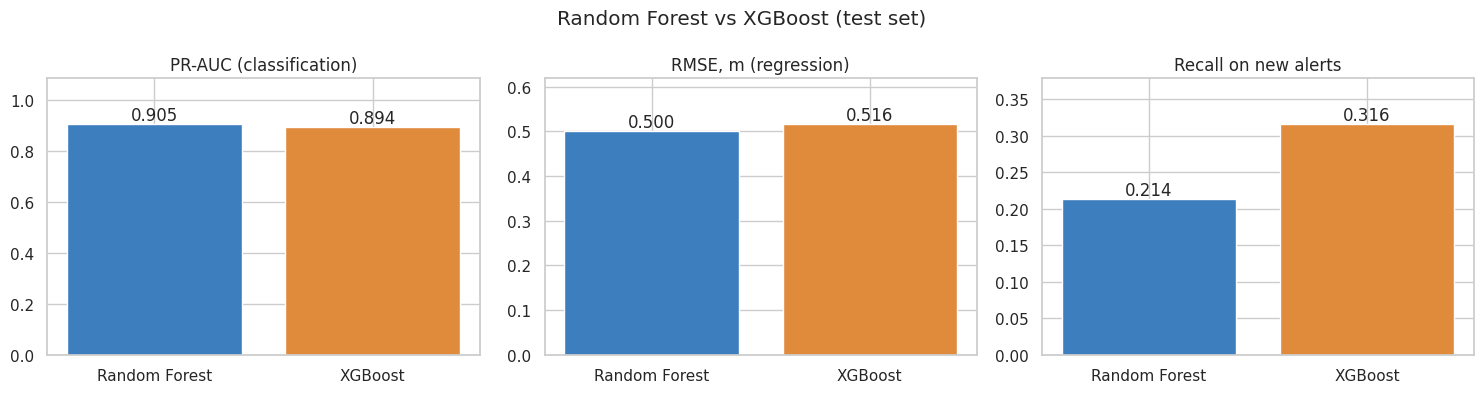

In [ ]:
def sum_row(tbl, model, cols):
    return tbl.set_index('Model').loc[model, cols]

sum_rf_xgb = pd.DataFrame({
    m: {'Classification PR-AUC': sum_row(SUM['clf_test'], m, ['PR_AUC']).iloc[0],
        'Classification F1': sum_row(SUM['clf_test'], m, ['F1']).iloc[0],
        'Classification recall': sum_row(SUM['clf_test'], m, ['Recall']).iloc[0],
        'New-alert recall': sum_row(SUM['clf_onset'], m, ['Recall']).iloc[0],
        'Regression RMSE (m)': sum_row(SUM['reg_test'], m, ['RMSE']).iloc[0],
        'Regression skill': sum_row(SUM['reg_test'], m, ['Skill']).iloc[0],
        'MAE at high water (m)': sum_row(SUM['reg_test'], m, ['MAE_high']).iloc[0],
        'Training time, clf (s)': sum_row(SUM['clf_test'], m, ['Fit_s']).iloc[0],
        'Training time, reg (s)': sum_row(SUM['reg_test'], m, ['Fit_s']).iloc[0]}
    for m in ['Random Forest', 'XGBoost']})
higher_better = {'Classification PR-AUC', 'Classification F1', 'Classification recall', 'New-alert recall', 'Regression skill'}
sum_rf_xgb['Better'] = [('Random Forest' if (r['Random Forest'] > r['XGBoost']) == (i in higher_better) else 'XGBoost')
                        for i, r in sum_rf_xgb.iterrows()]
display(sum_rf_xgb.round(4))

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, (metric, tbl, col) in zip(ax, [('PR-AUC (classification)', SUM['clf_test'], 'PR_AUC'),
                                      ('RMSE, m (regression)', SUM['reg_test'], 'RMSE'),
                                      ('Recall on new alerts', SUM['clf_onset'], 'Recall')]):
    v = tbl.set_index('Model').loc[['Random Forest', 'XGBoost'], col]
    a.bar(v.index, v.values, color=['#3D7EBF', '#E08A3C'])
    for i, x in enumerate(v.values): a.text(i, x, f'{x:.3f}', ha='center', va='bottom')
    a.set_title(metric); a.set_ylim(0, v.max() * 1.2)
plt.suptitle('Random Forest vs XGBoost (test set)'); plt.tight_layout()
plt.savefig(os.path.join(SUM_OUT, 'fig_rf_vs_xgboost.png'), dpi=150, bbox_inches='tight'); plt.show()

###Hybrid models

RF + ANN hybrids (test)


,Model,RMSE,MAE,Skill,MAE_high
0,Persistence,0.5982,0.3756,0.0000,0.6371
1,ANN (MLP),0.6062,0.4148,-0.0134,0.5991
2,Random Forest,0.5000,0.3066,0.1642,0.5656
3,H1 RF+ANN residual,0.5121,0.3260,0.1440,0.5619
4,H2 RF+ANN stacking,0.5172,0.3229,0.1354,0.5900
5,H3 RF+ANN blend,0.5061,0.3176,0.1539,0.5531


RF + ARIMA hybrid (test, all stations)


,Model,RMSE,MAE,Skill,MAE_high
0,Persistence,0.6026,0.3850,0.0000,0.6309
1,ARIMA,0.5550,0.3695,0.0790,0.6145
2,RF (direct),0.5038,0.3133,0.1640,0.5493
3,RF + ARIMA hybrid,0.5063,0.3253,0.1599,0.4832


Hybrid beats ARIMA at 67% of 39 stations; beats RF (direct) at 51%.
Differencing order chosen on validation: {1: 25, 0: 14}


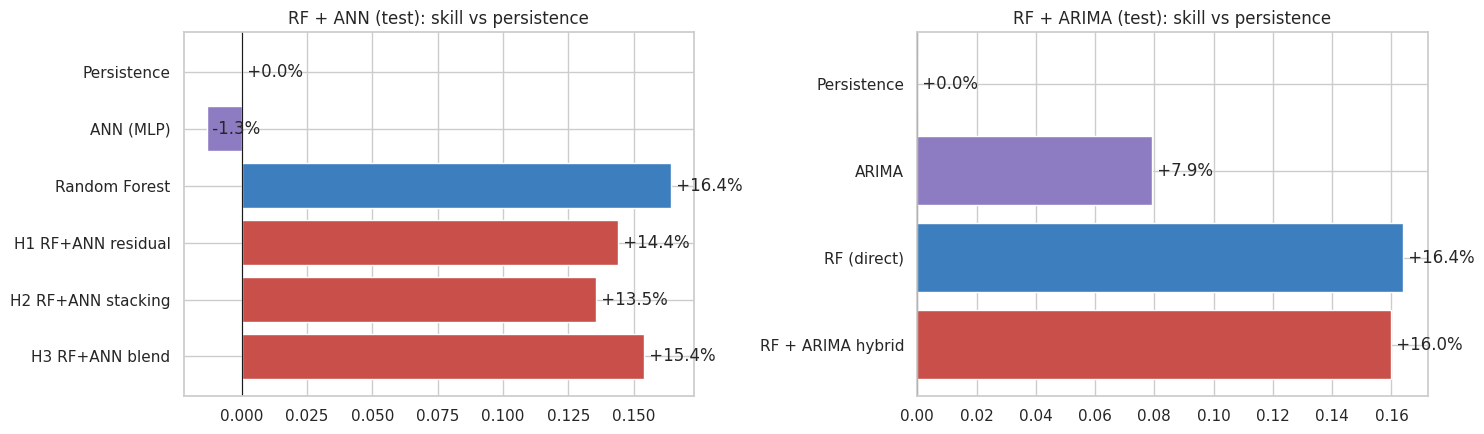

In [ ]:
sum_rfann = SUM['reg_test'].set_index('Model').loc[
    ['Persistence', 'ANN (MLP)', 'Random Forest', 'H1 RF+ANN residual', 'H2 RF+ANN stacking', 'H3 RF+ANN blend'],
    ['RMSE', 'MAE', 'Skill', 'MAE_high']].reset_index()
print('RF + ANN hybrids (test)'); display(sum_rfann.round(4))

sum_rfarima = SUM['ts_test'][['Model', 'RMSE', 'MAE', 'Skill', 'MAE_high']].copy()
sum_ts_wins = (SUM['ts_station']['RF + ARIMA hybrid'] < SUM['ts_station']['ARIMA']).mean()
sum_ts_wins_rf = (SUM['ts_station']['RF + ARIMA hybrid'] < SUM['ts_station']['RF (direct)']).mean()
print('RF + ARIMA hybrid (test, all stations)'); display(sum_rfarima.round(4))
print(f'Hybrid beats ARIMA at {sum_ts_wins:.0%} of {len(SUM["ts_station"])} stations; '
      f'beats RF (direct) at {sum_ts_wins_rf:.0%}.')
print('Differencing order chosen on validation:', SUM['ts_orders']['chosen_d'].value_counts().to_dict())

fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
for a, (t, title) in zip(ax, [(sum_rfann, 'RF + ANN (test)'), (sum_rfarima, 'RF + ARIMA (test)')]):
    cols = ['#9AA0A6' if m in ('Persistence',) else '#8E7CC3' if m in ('ANN (MLP)', 'ARIMA') else
            '#3D7EBF' if m in ('Random Forest', 'RF (direct)') else '#C9504A' for m in t.Model]
    a.barh(t.Model, t.Skill, color=cols); a.axvline(0, c='k', lw=0.8)
    for i, v in enumerate(t.Skill): a.text(v, i, f' {v:+.1%}', va='center')
    a.set_title(f'{title}: skill vs persistence'); a.invert_yaxis()
plt.tight_layout(); plt.savefig(os.path.join(SUM_OUT, 'fig_hybrids.png'), dpi=150, bbox_inches='tight'); plt.show()

###Statistical comparison

In [ ]:
def sum_parse_ci(s):
    lo, hi = s.strip('[]').split(',')
    return float(lo), float(hi)

def sum_overlap(ci_tbl, col, a, b):
    la, ha = sum_parse_ci(ci_tbl.set_index('Model').loc[a, col])
    lb, hb = sum_parse_ci(ci_tbl.set_index('Model').loc[b, col])
    return max(la, lb) <= min(ha, hb)

sum_pairs = []
sum_cb = sum_clf_best.set_index('Family')['Model']
sum_rb = sum_reg_best.set_index('Family')['Model']
for task, ci, col, best in [('Classification', SUM['clf_ci'], 'PR_AUC_95CI', sum_cb),
                            ('Regression', SUM['reg_ci'], 'RMSE_95CI', sum_rb)]:
    for f1, f2 in [('Bagging', 'Boosting'), ('Bagging', 'Stacking'), ('Boosting', 'Stacking')]:
        if f1 in best and f2 in best:
            a, b = best[f1], best[f2]
            sum_pairs.append({'Task': task, 'Comparison': f'{f1} ({a}) vs {f2} ({b})',
                              'CI A': ci.set_index('Model').loc[a, col], 'CI B': ci.set_index('Model').loc[b, col],
                              'Intervals overlap': sum_overlap(ci, col, a, b)})
    base = 'Persistence'
    top = best.get('Boosting', best.iloc[0])
    sum_pairs.append({'Task': task, 'Comparison': f'{top} vs {base}',
                      'CI A': ci.set_index('Model').loc[top, col], 'CI B': ci.set_index('Model').loc[base, col],
                      'Intervals overlap': sum_overlap(ci, col, top, base)})
sum_pairs.append({'Task': 'Time series', 'Comparison': 'RF + ARIMA hybrid vs ARIMA',
                  'CI A': SUM['ts_ci'].set_index('Model').loc['RF + ARIMA hybrid', 'RMSE_95CI'],
                  'CI B': SUM['ts_ci'].set_index('Model').loc['ARIMA', 'RMSE_95CI'],
                  'Intervals overlap': sum_overlap(SUM['ts_ci'], 'RMSE_95CI', 'RF + ARIMA hybrid', 'ARIMA')})
sum_stats = pd.DataFrame(sum_pairs)
display(sum_stats)

,Task,Comparison,CI A,CI B,Intervals overlap
0,Classification,Bagging (Random Forest) vs Boosting (LightGBM),"[0.888, 0.922]","[0.880, 0.914]",True
1,Classification,Bagging (Random Forest) vs Stacking (Soft Voting),"[0.888, 0.922]","[0.885, 0.920]",True
2,Classification,Boosting (LightGBM) vs Stacking (Soft Voting),"[0.880, 0.914]","[0.885, 0.920]",True
3,Classification,LightGBM vs Persistence,"[0.880, 0.914]","[0.687, 0.753]",False
4,Regression,Bagging (Extra Trees) vs Boosting (CatBoost),"[0.483, 0.529]","[0.481, 0.525]",True
5,Regression,Bagging (Extra Trees) vs Stacking (Averaging (...,"[0.483, 0.529]","[0.473, 0.518]",True
6,Regression,Boosting (CatBoost) vs Stacking (Averaging (Vo...,"[0.481, 0.525]","[0.473, 0.518]",True
7,Regression,CatBoost vs Persistence,"[0.481, 0.525]","[0.576, 0.622]",False
8,Time series,RF + ARIMA hybrid vs ARIMA,"[0.488, 0.526]","[0.535, 0.574]",False


###Summary figure

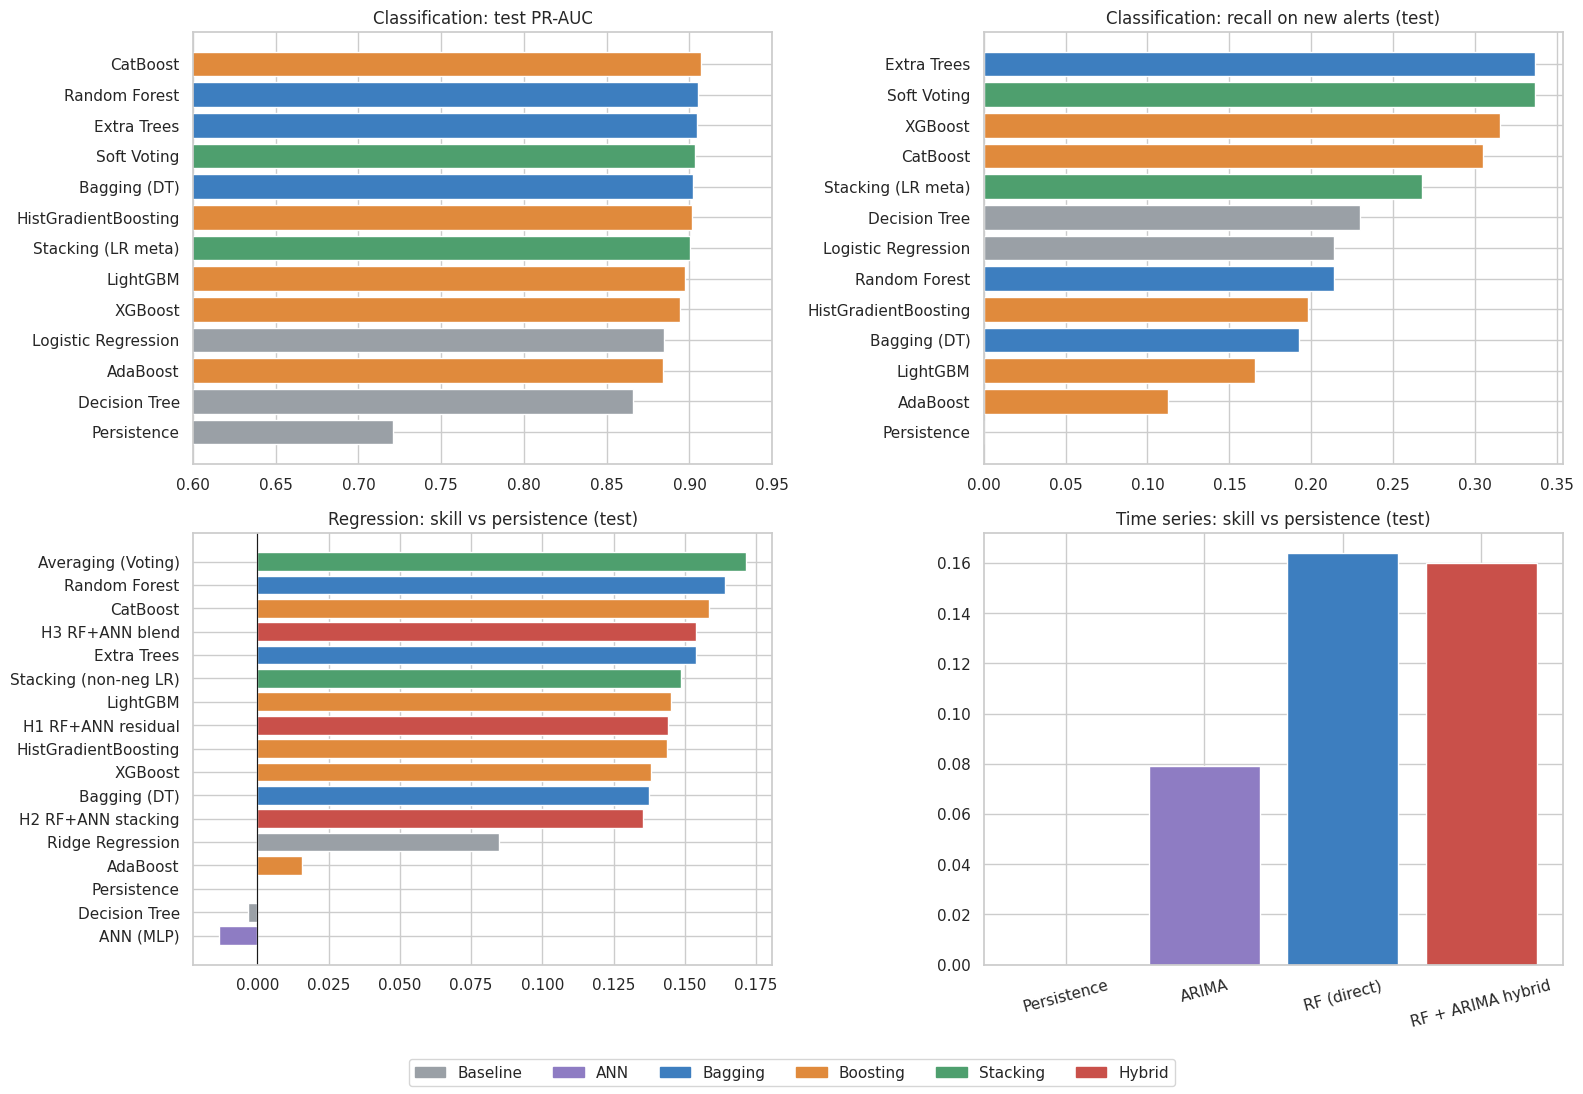

In [ ]:
FAMC = {'Baseline': '#9AA0A6', 'ANN': '#8E7CC3', 'Bagging': '#3D7EBF', 'Boosting': '#E08A3C',
        'Stacking': '#4E9F6E', 'Hybrid': '#C9504A'}
fig, ax = plt.subplots(2, 2, figsize=(16, 11))
t = SUM['clf_test'].sort_values('PR_AUC')
ax[0, 0].barh(t.Model, t.PR_AUC, color=t.Family.map(FAMC)); ax[0, 0].set_xlim(0.6, 0.95)
ax[0, 0].set_title('Classification: test PR-AUC')
t = SUM['clf_onset'].sort_values('Recall')
ax[0, 1].barh(t.Model, t.Recall, color=t.Family.map(FAMC)); ax[0, 1].set_title('Classification: recall on new alerts (test)')
t = SUM['reg_test'].sort_values('Skill')
ax[1, 0].barh(t.Model, t.Skill, color=t.Family.map(FAMC)); ax[1, 0].axvline(0, c='k', lw=0.8)
ax[1, 0].set_title('Regression: skill vs persistence (test)')
t = SUM['ts_test']
ax[1, 1].bar(t.Model, t.Skill, color=['#9AA0A6', '#8E7CC3', '#3D7EBF', '#C9504A'])
ax[1, 1].set_title('Time series: skill vs persistence (test)'); ax[1, 1].tick_params(axis='x', rotation=15)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in FAMC.values()]
fig.legend(handles, FAMC.keys(), loc='lower center', ncol=6)
plt.tight_layout(rect=(0, 0.04, 1, 1))
plt.savefig(os.path.join(SUM_OUT, 'fig_summary.png'), dpi=150, bbox_inches='tight'); plt.show()

In [ ]:
import shutil, zipfile
SUM_BUNDLE = os.path.join(PROC, 'dashboard_bundle')
shutil.rmtree(SUM_BUNDLE, ignore_errors=True); os.makedirs(SUM_BUNDLE)
sum_files = ['meta.json', 'clean_full.parquet', 'clf_X_test_raw.parquet', 'clf_ids_test.parquet',
             'clf_results_val.csv', 'clf_results_test.csv', 'clf_results_test_ci.csv', 'clf_results_new_alert.csv',
             'clf_model_registry.json', 'clf_test_predictions.parquet',
             'reg_results_val.csv', 'reg_results_test.csv', 'reg_results_test_ci.csv', 'reg_results_by_band.csv',
             'reg_model_registry.json', 'reg_test_predictions.parquet',
             'ts_results_val.csv', 'ts_results_test.csv', 'ts_results_test_ci.csv', 'ts_results_per_station.csv',
             'ts_arima_orders.csv', 'ts_test_predictions.parquet']
sum_missing = [f for f in sum_files if not os.path.exists(os.path.join(PROC, f))]
for f in sum_files:
    if f not in sum_missing:
        shutil.copy(os.path.join(PROC, f), SUM_BUNDLE)

joblib.load(f'{PROC}/models_clf/CatBoost.joblib').save_model(f'{SUM_BUNDLE}/catboost_clf.cbm')
joblib.load(f'{PROC}/models_reg/CatBoost.joblib').save_model(f'{SUM_BUNDLE}/catboost_reg.cbm')

def sum_importances(task, names):
    reg = json.load(open(f'{PROC}/{task}_model_registry.json'))
    rows = []
    for name in names:
        fn = f"{PROC}/models_{task}/{name.replace(' ', '_').replace('(', '').replace(')', '').replace('+', 'plus')}.joblib"
        if name not in reg or not os.path.exists(fn):
            continue
        m = joblib.load(fn)
        cols = pd.read_parquet(f"{PROC}/{task}_X_test_{reg[name]['data']}.parquet").columns
        imp = pd.Series(m.feature_importances_, index=cols); imp = imp / imp.sum()
        rows += [{'task': task, 'model': name, 'family': reg[name]['family'], 'feature': k, 'importance': v}
                 for k, v in imp.items()]
        del m
    return rows
names5 = ['Random Forest', 'Extra Trees', 'XGBoost', 'LightGBM', 'CatBoost']
pd.DataFrame(sum_importances('clf', names5) + sum_importances('reg', names5)).to_csv(
    f'{SUM_BUNDLE}/feature_importance.csv', index=False)

sum_zip = os.path.join(PROC, 'dashboard_bundle.zip')
with zipfile.ZipFile(sum_zip, 'w', zipfile.ZIP_DEFLATED) as z:
    for f in sorted(os.listdir(SUM_BUNDLE)):
        z.write(os.path.join(SUM_BUNDLE, f), arcname=f)
print(f'Created {sum_zip}  ({os.path.getsize(sum_zip) / 1e6:.1f} MB, {len(os.listdir(SUM_BUNDLE))} files)')
print('Missing inputs:', sum_missing or 'none')

Created /content/drive/MyDrive/MachineLearningCA01/processed/dashboard_bundle.zip  (5.0 MB, 25 files)
Missing inputs: none


##Load the Saved Models and Evaluate Them on Validation and Test

In [ ]:
if 'PROC' not in globals():
    from google.colab import drive
    drive.mount('/content/drive')
    PROC = '/content/drive/MyDrive/MachineLearningCA01/processed'

import os, json, time, sys, warnings, joblib
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.metrics import (average_precision_score, roc_auc_score, f1_score, precision_score, recall_score,
                             matthews_corrcoef, mean_absolute_error, mean_squared_error, r2_score, confusion_matrix)
from statsmodels.tsa.statespace.sarimax import SARIMAX
warnings.filterwarnings('ignore')

def to_logit(p):
    p = np.clip(p, 1e-4, 1 - 1e-4)
    return np.log(p / (1 - p))
sys.modules['__main__'].to_logit = to_logit

LD_DIRS = {k: os.path.join(PROC, f'models_{k}') for k in ['clf', 'reg', 'ts']}
for k, d in LD_DIRS.items():
    files = sorted(os.listdir(d))
    size = sum(os.path.getsize(os.path.join(d, f)) for f in files) / 1e6
    print(f'models_{k:4s}: {len(files):2d} files, {size:,.0f} MB')
ld_file = lambda name: name.replace(' ', '_').replace('(', '').replace(')', '').replace('+', 'plus').replace('/', '_') + '.joblib'

models_clf : 12 files, 178 MB
models_reg : 15 files, 1,897 MB
models_ts  :  1 files, 99 MB


In [ ]:
LD_SPLITS = ['val', 'test']
ld_rp = lambda f: pd.read_parquet(os.path.join(PROC, f))
LD = {}
for task in ['clf', 'reg']:
    LD[task] = {
        'X': {kind: {s: ld_rp(f'{task}_X_{s}_{kind}.parquet') for s in LD_SPLITS} for kind in ['raw', 'imputed', 'scaled']},
        'y': {s: ld_rp(f'{task}_y_{s}.parquet')['y'].values for s in LD_SPLITS},
        'ids': {s: ld_rp(f'{task}_ids_{s}.parquet') for s in LD_SPLITS},
        'registry': json.load(open(os.path.join(PROC, f'{task}_model_registry.json'))),
        'saved_test': pd.read_csv(os.path.join(PROC, f'{task}_results_test.csv')),
    }
for task in LD:
    print(task, {s: LD[task]['X']['raw'][s].shape for s in LD_SPLITS})

clf {'val': (5490, 53), 'test': (5693, 53)}
reg {'val': (5151, 53), 'test': (5428, 53)}


###Classification models


In [ ]:
def ld_clf_metrics(y, p, thr):
    pred = (p >= thr).astype(int)
    return {'PR_AUC': average_precision_score(y, p), 'ROC_AUC': roc_auc_score(y, p) if len(np.unique(p)) > 1 else 0.5,
            'F1': f1_score(y, pred, zero_division=0), 'Recall': recall_score(y, pred, zero_division=0),
            'Precision': precision_score(y, pred, zero_division=0), 'MCC': matthews_corrcoef(y, pred)}

ld_c = LD['clf']
LD_CLF = {}
t0 = time.time()
for name, info in ld_c['registry'].items():
    if name == 'Persistence':
        pv, pt = [(ld_c['X']['raw'][s]['status'].values >= 1).astype(float) for s in LD_SPLITS]
    else:
        m = joblib.load(os.path.join(LD_DIRS['clf'], ld_file(name)))
        pv, pt = [m.predict_proba(ld_c['X'][info['data']][s])[:, 1] for s in LD_SPLITS]
        del m
    LD_CLF[name] = {'family': info['family'], 'threshold': info['threshold'], 'val': pv, 'test': pt}
print(f'Loaded and scored {len(LD_CLF)} classifiers in {time.time() - t0:.0f}s')

ld_clf_tbl = {s: pd.DataFrame([{'Model': n, 'Family': r['family'], **ld_clf_metrics(ld_c['y'][s], r[s], r['threshold']),
                                'Threshold': r['threshold']} for n, r in LD_CLF.items()])
                 .sort_values('PR_AUC', ascending=False).reset_index(drop=True) for s in LD_SPLITS}
print('VALIDATION'); display(ld_clf_tbl['val'].round(4))
print('TEST'); display(ld_clf_tbl['test'].round(4))

Loaded and scored 13 classifiers in 8s
VALIDATION


,Model,Family,PR_AUC,ROC_AUC,F1,Recall,Precision,MCC,Threshold
0,Soft Voting,Stacking,0.8925,0.9709,0.8159,0.8107,0.8211,0.7920,0.3261
1,LightGBM,Boosting,0.8913,0.9727,0.8119,0.7524,0.8817,0.7926,0.5574
2,XGBoost,Boosting,0.8905,0.9703,0.8137,0.8028,0.8250,0.7899,0.2695
3,Stacking (LR meta),Stacking,0.8892,0.9710,0.8104,0.7650,0.8615,0.7890,0.8409
4,CatBoost,Boosting,0.8858,0.9717,0.7929,0.7366,0.8585,0.7710,0.6538
5,HistGradientBoosting,Boosting,0.8816,0.9686,0.8073,0.7334,0.8977,0.7900,0.7057
6,Random Forest,Bagging,0.8765,0.9665,0.7839,0.7240,0.8547,0.7616,0.3375
7,Extra Trees,Bagging,0.8724,0.9655,0.7875,0.7571,0.8205,0.7618,0.2950
8,Bagging (DT),Bagging,0.8674,0.9650,0.7870,0.7256,0.8598,0.7653,0.4922
9,Logistic Regression,Baseline,0.8615,0.9640,0.7864,0.7287,0.8540,0.7640,0.8876


TEST


,Model,Family,PR_AUC,ROC_AUC,F1,Recall,Precision,MCC,Threshold
0,CatBoost,Boosting,0.9071,0.9752,0.8368,0.8066,0.8694,0.8159,0.6538
1,Random Forest,Bagging,0.9054,0.9718,0.8225,0.7821,0.8672,0.8006,0.3375
2,Extra Trees,Bagging,0.9048,0.9734,0.8252,0.8139,0.8368,0.8014,0.2950
3,Soft Voting,Stacking,0.9032,0.9736,0.8132,0.8167,0.8097,0.7872,0.3261
4,Bagging (DT),Bagging,0.9018,0.9706,0.8188,0.7792,0.8626,0.7964,0.4922
5,HistGradientBoosting,Boosting,0.9013,0.9758,0.8233,0.7633,0.8936,0.8042,0.7057
6,Stacking (LR meta),Stacking,0.9005,0.9741,0.8177,0.7864,0.8516,0.7944,0.8409
7,LightGBM,Boosting,0.8972,0.9726,0.8065,0.7518,0.8698,0.7845,0.5574
8,XGBoost,Boosting,0.8940,0.9711,0.7971,0.8023,0.7920,0.7688,0.2695
9,Logistic Regression,Baseline,0.8849,0.9742,0.8111,0.7807,0.8440,0.7868,0.8876


###Regression models (including the RF + ANN hybrids)

In [ ]:
ld_r = LD['reg']
ld_now = {s: ld_r['X']['raw'][s]['water_level'].values for s in LD_SPLITS}
ld_alert = {s: ld_r['X']['raw'][s]['alert_level'].values for s in LD_SPLITS}
ld_rmse = lambda a, b: float(np.sqrt(mean_squared_error(a, b)))

ld_d_std = (pd.read_parquet(os.path.join(PROC, 'reg_y_train.parquet'))['y'].values
            - pd.read_parquet(os.path.join(PROC, 'reg_X_train_raw.parquet'))['water_level'].values).std()

LD_REG = {'Persistence': {'family': 'Baseline', 'val': ld_now['val'], 'test': ld_now['test']}}
t0 = time.time()
for name, info in ld_r['registry'].items():
    if name in ('Persistence', 'H3 RF+ANN blend'):
        continue
    m = joblib.load(os.path.join(LD_DIRS['reg'], ld_file(name)))
    out = {}
    for s in LD_SPLITS:
        if name == 'H1 RF+ANN residual':
            rf_p = m['rf'].predict(ld_r['X']['imputed'][s])
            out[s] = ld_now[s] + rf_p + m['ann_residual'].predict(np.column_stack([ld_r['X']['scaled'][s].values, rf_p / ld_d_std]))
        else:
            out[s] = ld_now[s] + m.predict(ld_r['X'][info['data']][s])
    del m
    LD_REG[name] = {'family': info['family'], **out}
ld_w = float(ld_r['registry']['H3 RF+ANN blend']['params']['w_rf'])
LD_REG['H3 RF+ANN blend'] = {'family': 'Hybrid', **{s: ld_w * LD_REG['Random Forest'][s] + (1 - ld_w) * LD_REG['ANN (MLP)'][s]
                                                   for s in LD_SPLITS}}
print(f'Loaded and scored {len(LD_REG)} regressors in {time.time() - t0:.0f}s (H3 weight on RF = {ld_w})')

def ld_reg_metrics(s, pred):
    y, al = ld_r['y'][s], ld_alert[s]
    high = y >= 0.8 * al
    return {'RMSE': ld_rmse(y, pred), 'MAE': mean_absolute_error(y, pred), 'R2': r2_score(y, pred),
            'Skill': 1 - ld_rmse(y, pred) / ld_rmse(y, ld_now[s]), 'MAE_high': mean_absolute_error(y[high], pred[high]),
            'Warn_F1': f1_score((y >= al).astype(int), (pred >= al).astype(int), zero_division=0)}

ld_reg_tbl = {s: pd.DataFrame([{'Model': n, 'Family': v['family'], **ld_reg_metrics(s, v[s])} for n, v in LD_REG.items()])
                 .sort_values('RMSE').reset_index(drop=True) for s in LD_SPLITS}
print('VALIDATION'); display(ld_reg_tbl['val'].round(4))
print('TEST'); display(ld_reg_tbl['test'].round(4))

Loaded and scored 17 regressors in 17s (H3 weight on RF = 0.65)
VALIDATION


,Model,Family,RMSE,MAE,R2,Skill,MAE_high,Warn_F1
0,H3 RF+ANN blend,Hybrid,0.5243,0.3218,0.9538,0.1953,0.6076,0.7574
1,Averaging (Voting),Stacking,0.5336,0.3203,0.9522,0.1811,0.6358,0.7493
2,H2 RF+ANN stacking,Hybrid,0.5367,0.3319,0.9516,0.1763,0.6346,0.7407
3,CatBoost,Boosting,0.5377,0.3285,0.9514,0.1748,0.6528,0.7448
4,HistGradientBoosting,Boosting,0.5399,0.3299,0.9510,0.1714,0.6515,0.7455
5,Stacking (non-neg LR),Stacking,0.5415,0.3279,0.9507,0.1690,0.6506,0.7437
6,LightGBM,Boosting,0.5429,0.3285,0.9505,0.1668,0.6594,0.7497
7,Extra Trees,Bagging,0.5430,0.3314,0.9505,0.1667,0.6368,0.7528
8,XGBoost,Boosting,0.5431,0.3289,0.9504,0.1666,0.6565,0.7444
9,Random Forest,Bagging,0.5452,0.3300,0.9500,0.1632,0.6419,0.7507


TEST


,Model,Family,RMSE,MAE,R2,Skill,MAE_high,Warn_F1
0,Averaging (Voting),Stacking,0.4957,0.3061,0.9495,0.1714,0.5548,0.7766
1,Random Forest,Bagging,0.5000,0.3066,0.9487,0.1642,0.5656,0.7659
2,CatBoost,Boosting,0.5034,0.3166,0.9480,0.1586,0.5581,0.7545
3,H3 RF+ANN blend,Hybrid,0.5061,0.3176,0.9474,0.1539,0.5531,0.7694
4,Extra Trees,Bagging,0.5062,0.3134,0.9474,0.1539,0.5603,0.7332
5,Stacking (non-neg LR),Stacking,0.5093,0.3150,0.9467,0.1486,0.5834,0.7391
6,LightGBM,Boosting,0.5114,0.3185,0.9463,0.1451,0.5636,0.7577
7,H1 RF+ANN residual,Hybrid,0.5121,0.3260,0.9461,0.1440,0.5619,0.7649
8,HistGradientBoosting,Boosting,0.5122,0.3166,0.9461,0.1437,0.5835,0.7516
9,XGBoost,Boosting,0.5157,0.3236,0.9454,0.1380,0.5905,0.7406


###RF + ARIMA time-series hybrid

In [ ]:
ld_pack = joblib.load(os.path.join(LD_DIRS['ts'], 'rf_arima_hybrid.joblib'))
print('Package contents:', list(ld_pack.keys()))
ld_meta = json.load(open(os.path.join(PROC, 'meta.json')))
ld_cut_val, ld_cut_test = pd.Timestamp(ld_meta['cut_val']), pd.Timestamp(ld_meta['cut_test'])
ld_clean = ld_rp('clean_full.parquet'); ld_clean['obs_datetime'] = pd.to_datetime(ld_clean['obs_datetime'])
ld_grid = pd.date_range(ld_clean.obs_datetime.min().floor('3h'), ld_clean.obs_datetime.max(), freq='3h')

t0 = time.time()
ld_rows = []
for st, g in ld_clean.groupby('station', observed=True):
    s = g.drop_duplicates('obs_datetime').set_index('obs_datetime')['water_level'].reindex(ld_grid)
    res = SARIMAX(s, order=ld_pack['arima_orders'][st], trend=ld_pack['arima_trend'][st]).filter(ld_pack['arima_params'][st])
    v = s.values
    for i in np.where(~np.isnan(v[:-8]) & ~np.isnan(v[8:]))[0]:
        ld_rows.append((st, s.index[i], v[i], res.get_prediction(start=i + 1, end=i + 8, dynamic=0).predicted_mean.iloc[-1], v[i + 8]))
ld_fc = pd.DataFrame(ld_rows, columns=['station', 'obs_datetime', 'level_now', 'arima_pred', 'actual_24h'])
ld_fc['target_time'] = ld_fc.obs_datetime + pd.Timedelta(hours=24)
ld_feats = ld_meta['features']
ld_ts = ld_fc.merge(ld_clean[['station', 'obs_datetime', 'alert_level'] + [f for f in ld_feats if f != 'alert_level']],
                    on=['station', 'obs_datetime'], how='inner')
ld_ts['split'] = np.select([(ld_ts.obs_datetime >= ld_cut_val) & (ld_ts.target_time < ld_cut_test),
                            ld_ts.obs_datetime >= ld_cut_test], ['val', 'test'], default='other')
ld_ts['arima_change'] = ld_ts.arima_pred - ld_ts.level_now
print(f'{len(ld_fc):,} rolling ARIMA forecasts rebuilt in {time.time() - t0:.0f}s')

LD_TS = {}
for s in LD_SPLITS:
    part = ld_ts[ld_ts.split == s].reset_index(drop=True)
    X = pd.DataFrame(ld_pack['imputer'].transform(part[ld_pack['x_cols']]), columns=ld_pack['x_cols'])
    LD_TS[s] = {'part': part, 'Persistence': part.level_now.values, 'ARIMA': part.arima_pred.values,
                'RF (direct)': part.level_now.values + ld_pack['rf_direct'].predict(X[ld_feats]),
                'RF + ARIMA hybrid': part.arima_pred.values + ld_pack['rf_hybrid'].predict(X[ld_pack['x_cols']])}

def ld_ts_metrics(part, pred):
    y, now, al = part.actual_24h.values, part.level_now.values, part.alert_level.values
    high = y >= 0.8 * al
    return {'RMSE': ld_rmse(y, pred), 'MAE': mean_absolute_error(y, pred), 'Skill': 1 - ld_rmse(y, pred) / ld_rmse(y, now),
            'MAE_high': mean_absolute_error(y[high], pred[high]), 'n': len(y)}

ld_ts_tbl = {s: pd.DataFrame([{'Model': m, **ld_ts_metrics(LD_TS[s]['part'], LD_TS[s][m])}
                              for m in ['Persistence', 'ARIMA', 'RF (direct)', 'RF + ARIMA hybrid']]) for s in LD_SPLITS}
print('VALIDATION'); display(ld_ts_tbl['val'].round(4))
print('TEST'); display(ld_ts_tbl['test'].round(4))

Package contents: ['rf_hybrid', 'rf_direct', 'imputer', 'x_cols', 'arima_orders', 'arima_params', 'arima_trend']
27,465 rolling ARIMA forecasts rebuilt in 56s
VALIDATION


,Model,RMSE,MAE,Skill,MAE_high,n
0,Persistence,0.6231,0.3705,0.0000,0.7472,4308
1,ARIMA,0.5955,0.3527,0.0443,0.7954,4308
2,RF (direct),0.5135,0.3128,0.1759,0.5933,4308
3,RF + ARIMA hybrid,0.4990,0.3086,0.1991,0.5536,4308


TEST


,Model,RMSE,MAE,Skill,MAE_high,n
0,Persistence,0.6026,0.3850,0.0000,0.6309,4935
1,ARIMA,0.5550,0.3695,0.0790,0.6145,4935
2,RF (direct),0.5038,0.3133,0.1640,0.5493,4935
3,RF + ARIMA hybrid,0.5063,0.3253,0.1599,0.4832,4935


###Check: do the loaded models reproduce the saved results?

In [ ]:
def ld_compare(new, saved_file, cols):
    saved = pd.read_csv(os.path.join(PROC, saved_file)).set_index('Model')
    j = new.set_index('Model')[cols].join(saved[cols], rsuffix='_saved', how='inner')
    return max(float((j[c] - j[c + '_saved']).abs().max()) for c in cols), len(j)

ld_checks = []
for task, tbl, f, cols in [('Classification', ld_clf_tbl['test'], 'clf_results_test.csv', ['PR_AUC', 'F1', 'Recall', 'Precision']),
                           ('Regression', ld_reg_tbl['test'], 'reg_results_test.csv', ['RMSE', 'MAE', 'Skill']),
                           ('Time series', ld_ts_tbl['test'], 'ts_results_test.csv', ['RMSE', 'MAE', 'Skill'])]:
    diff, n = ld_compare(tbl, f, cols)
    ld_checks.append({'Task': task, 'Models compared': n, 'Max abs difference': diff, 'Reproduced': diff < 1e-6})
ld_check_tbl = pd.DataFrame(ld_checks)
display(ld_check_tbl)
print('All saved models reproduce the reported results.' if ld_check_tbl.Reproduced.all()
      else 'Some results differ - see the table above.')

,Task,Models compared,Max abs difference,Reproduced
0,Classification,13,1.110223e-16,True
1,Regression,17,8.326673e-17,True
2,Time series,4,8.326673e-17,True


All saved models reproduce the reported results.


###Example: predictions for one station (test period)

Hanwella: the 10 test readings with the highest water level


,time,level_now_m,alert_within_24h (actual),P(alert) CatBoost,P(alert) Random Forest,CatBoost warning
0,2026-11-10 03:00:00,6.09,0.0,0.428,0.570,0
1,2026-11-10 09:00:00,6.05,0.0,0.095,0.170,0
2,2026-11-12 09:00:00,5.65,0.0,0.077,0.055,0
3,2026-11-12 06:00:00,5.61,0.0,0.692,0.230,1
4,2026-11-10 12:00:00,5.60,0.0,0.021,0.032,0
5,2026-11-10 00:00:00,5.53,0.0,0.544,0.398,0
6,2026-11-12 12:00:00,5.46,0.0,0.027,0.022,0
7,2026-10-27 18:00:00,5.39,0.0,0.015,0.028,0
8,2026-11-09 06:00:00,5.18,0.0,0.134,0.402,0
9,2026-11-12 15:00:00,5.15,0.0,0.014,0.025,0


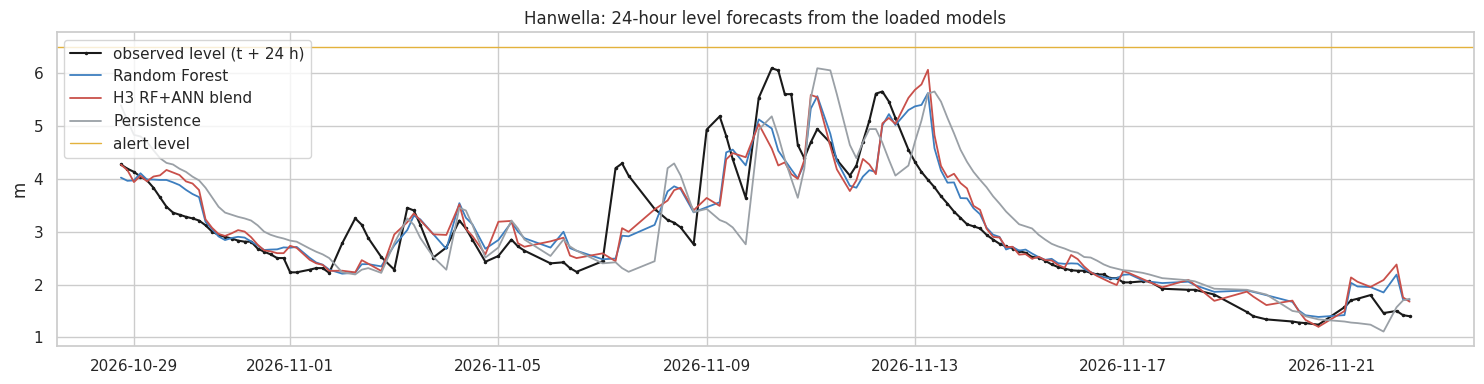

In [ ]:
LD_STATION = 'Hanwella'
ld_ids = ld_c['ids']['test'].reset_index(drop=True)
mk = (ld_ids.station == LD_STATION).values
ld_example = pd.DataFrame({
    'time': ld_ids.obs_datetime[mk].values,
    'level_now_m': ld_c['X']['raw']['test']['water_level'].values[mk],
    'alert_within_24h (actual)': ld_c['y']['test'][mk],
    'P(alert) CatBoost': LD_CLF['CatBoost']['test'][mk].round(3),
    'P(alert) Random Forest': LD_CLF['Random Forest']['test'][mk].round(3),
})
ld_example['CatBoost warning'] = (ld_example['P(alert) CatBoost'] >= LD_CLF['CatBoost']['threshold']).astype(int)
print(f'{LD_STATION}: the 10 test readings with the highest water level')
display(ld_example.sort_values('level_now_m', ascending=False).head(10).reset_index(drop=True))

r_ids = ld_r['ids']['test'].reset_index(drop=True)
mk = (r_ids.station == LD_STATION).values
t = pd.to_datetime(r_ids.obs_datetime[mk]) + pd.Timedelta(hours=24)
fig, ax = plt.subplots(figsize=(15, 4))
ax.plot(t, ld_r['y']['test'][mk], 'k.-', ms=3, label='observed level (t + 24 h)')
for name, col in [('Random Forest', '#3D7EBF'), ('H3 RF+ANN blend', '#C9504A'), ('Persistence', '#9AA0A6')]:
    ax.plot(t, LD_REG[name]['test'][mk], lw=1.3, color=col, label=name)
ax.axhline(ld_alert['test'][mk][0], color='#E3B23C', lw=1, label='alert level')
ax.set_title(f'{LD_STATION}: 24-hour level forecasts from the loaded models'); ax.set_ylabel('m'); ax.legend(loc='upper left')
plt.tight_layout(); plt.show()

In [ ]:
print('=' * 90); print('SAVED MODELS LOADED AND EVALUATED'); print('=' * 90)
print(ld_check_tbl.to_string(index=False))
print('\nClassification (test) - top 5'); print(ld_clf_tbl['test'][['Model', 'Family', 'PR_AUC', 'F1', 'Recall', 'Precision']].head(5).round(4).to_string(index=False))
print('\nRegression (test) - top 5'); print(ld_reg_tbl['test'][['Model', 'Family', 'RMSE', 'MAE', 'Skill']].head(5).round(4).to_string(index=False))
print('\nTime series (test)'); print(ld_ts_tbl['test'][['Model', 'RMSE', 'MAE', 'Skill']].round(4).to_string(index=False))

SAVED MODELS LOADED AND EVALUATED
          Task  Models compared  Max abs difference  Reproduced
Classification               13        1.110223e-16        True
    Regression               17        8.326673e-17        True
   Time series                4        8.326673e-17        True

Classification (test) - top 5
        Model   Family  PR_AUC     F1  Recall  Precision
     CatBoost Boosting  0.9071 0.8368  0.8066     0.8694
Random Forest  Bagging  0.9054 0.8225  0.7821     0.8672
  Extra Trees  Bagging  0.9048 0.8252  0.8139     0.8368
  Soft Voting Stacking  0.9032 0.8132  0.8167     0.8097
 Bagging (DT)  Bagging  0.9018 0.8188  0.7792     0.8626

Regression (test) - top 5
             Model   Family   RMSE    MAE  Skill
Averaging (Voting) Stacking 0.4957 0.3061 0.1714
     Random Forest  Bagging 0.5000 0.3066 0.1642
          CatBoost Boosting 0.5034 0.3166 0.1586
   H3 RF+ANN blend   Hybrid 0.5061 0.3176 0.1539
       Extra Trees  Bagging 0.5062 0.3134 0.1539

Time series (te